# 05 · Simple Linear Regression, Step by Step
*AI Foundations · Notebook 05 of 19*

Can you predict a student's mock-contest score from how many hours a week they practice?
In this notebook you will build the simplest learning machine there is, a straight line,
and train it **completely by hand**: predict, measure the mistake, compute two derivatives,
nudge two numbers, repeat. Every model later in this course, from logistic regression to deep
neural networks, is trained by this same *predict → loss → gradient → update* loop. Seeing it
work number by number in a tiny example pays off in every notebook that follows.

**What you will learn**
- How to frame a regression problem: features, labels, model, parameters, hypothesis space.
- How to measure mistakes with residuals, how SSE, MSE, RMSE and absolute error differ, and
  *why* squared error is the default (including its maximum-likelihood justification).
- What the loss looks like: a parabola in one parameter, a convex bowl in two.
- How to derive the gradients $\partial \ell/\partial w = 2x(\hat y - y)$ and
  $\partial \ell/\partial b = 2(\hat y - y)$ with the chain rule, and check them numerically.
- How to run stochastic gradient descent by hand for a full epoch, then for many epochs.
- How per-sample SGD, mini-batch and full-batch gradient descent differ, why the learning rate
  has a hard upper limit set by the curvature, and why centering the feature speeds training up.
- How to derive the exact least-squares solution and connect it to covariance and correlation.
- How to judge a fit with $R^2$, residual plots, leverage and influence, and when to reach for
  a robust loss.
- How statisticians quantify uncertainty: standard errors, t-tests, confidence vs prediction
  intervals, and assumption checks with `statsmodels`.
- How to reproduce everything in PyTorch, where autograd computes the derivatives for you.

**Prerequisites:** basic Python, NumPy and matplotlib, plus high-school algebra. Derivatives are
reviewed from scratch (it helps if you have met one before).      **Estimated time:** ~4 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️. Each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. The problem: from practice hours to contest scores
2. Measuring mistakes: residuals and loss functions
3. The loss landscape: a parabola and a bowl
4. Which way is downhill? Derivatives and gradients
5. The training loop, by hand
6. Per-sample SGD vs full-batch vs mini-batch
7. Choosing the learning rate (and why centering helps)
8. The exact answer: least squares in closed form
9. How good is the fit? $R^2$, residuals, outliers
10. The statistics view: uncertainty and assumptions
11. The same model in PyTorch
12. Quiz
13. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, data folder and a tiny test harness.
import random
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import scipy
from scipy import stats
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
import torch
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # for any library that still uses NumPy's legacy global RNG
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# One fixed, colorblind-checked categorical palette, always used in the same order.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = PALETTE
INK, MUTED = "#0b0b0b", "#898781"   # text-like marks, and recessive reference marks

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)          # print wide tables on one line (no "..." columns)
pd.set_option("display.max_columns", 20)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

for mod in (np, pd, matplotlib, scipy, sklearn, statsmodels, torch):
    print(f"{mod.__name__:<12} {mod.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

numpy        2.5.3
pandas       2.3.3
matplotlib   3.11.2
scipy        1.18.1
sklearn      1.9.1
statsmodels  0.15.0
torch        2.14.1+cu130


## 1. The problem: from practice hours to contest scores

A coach runs an olympiad training club. Each week she records how many hours every student
practiced, and at the end of the week the club sits a mock contest scored out of 100. She
wonders: *can I predict a student's score from their practice hours?* A good prediction rule
would let her set realistic goals for newcomers and notice early when someone is falling behind.

### 1.1 Our dataset

Here are six students, listed in the order they appear in the coach's notebook (not sorted, and
the order will matter later, in Section 6).

In [2]:
students = pd.DataFrame({
    "student": ["Ava", "Ben", "Chen", "Dana", "Eli", "Fay"],
    "hours":   [3, 6, 1, 8, 4, 2],        # feature x: practice hours per week
    "score":   [49, 65, 37, 82, 56, 47],  # label y: mock-contest score (out of 100)
})
x = students["hours"].to_numpy(dtype=float)   # shape (6,)
y = students["score"].to_numpy(dtype=float)   # shape (6,)
n = len(x)
display(students)
print(f"x has shape {x.shape}, y has shape {y.shape}.  "
      f"Mean hours = {x.mean():.2f}, mean score = {y.mean():.2f}")

,student,hours,score
0,Ava,3,49
1,Ben,6,65
2,Chen,1,37
3,Dana,8,82
4,Eli,4,56
5,Fay,2,47


x has shape (6,), y has shape (6,).  Mean hours = 4.00, mean score = 56.00


Each row is one **sample** (also called an *example* or *observation*). We write the $i$-th
sample as $(x_i, y_i)$: Ava is $(x_1, y_1) = (3, 49)$, Ben is $(x_2, y_2) = (6, 65)$, and so on.
Stacking them gives two vectors $\mathbf{x} = (x_1, \dots, x_n) \in \mathbb{R}^{n}$ and
$\mathbf{y} = (y_1, \dots, y_n) \in \mathbb{R}^{n}$ with $n = 6$. The averages will show up
again and again, so remember them: $\bar x = 4$ hours and $\bar y = 56$ points.

Always plot your data before modelling it.

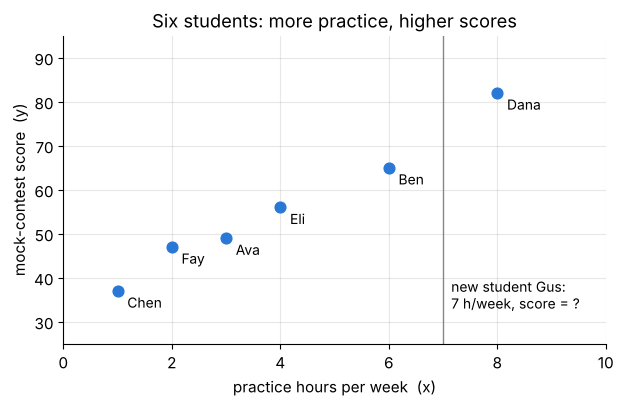

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, y, s=60, color=BLUE, zorder=3)
for name, xi, yi in zip(students["student"], x, y):
    ax.annotate(name, (xi, yi), textcoords="offset points", xytext=(7, -12), fontsize=10)
ax.axvline(7, color=MUTED, lw=1)
ax.text(7.15, 33, "new student Gus:\n7 h/week, score = ?", fontsize=10)
ax.set(xlabel="practice hours per week  (x)", ylabel="mock-contest score  (y)",
       title="Six students: more practice, higher scores", xlim=(0, 10), ylim=(25, 95))
plt.show()

The points climb from left to right, almost along a straight line but not exactly: some
students did a bit better than the trend, some a bit worse (a good night's sleep, a lucky
problem set, nerves...). A new member, **Gus**, practices **7 hours per week**. What score
should we expect from him? To answer, we need a *rule* that turns hours into a score.

### 1.2 The vocabulary of supervised learning

This is a **supervised learning** problem: we are given inputs together with the correct
answers, and we want a rule that also works for new inputs. Because the answer is a real number
(not a category such as "pass/fail"), it is a **regression** problem.

| Term | Meaning | In our example |
|---|---|---|
| sample $(x_i, y_i)$ | one row of data | Ava: $(3, 49)$ |
| feature (input) $x$ | what we know *before* the outcome | practice hours per week |
| label (target) $y$ | what we want to predict | mock-contest score |
| dataset $\mathcal{D}$ | all $n$ samples $\{(x_i, y_i)\}_{i=1}^{n}$ | the 6 students |
| model $f$ | a rule that maps an input to a prediction $\hat y = f(x)$ | $\hat y = wx + b$ |
| parameters $\boldsymbol\theta$ | numbers inside the model that *learning* adjusts | slope $w$, intercept $b$ |
| hypothesis space $\mathcal{H}$ | the set of all models we are willing to consider | all straight lines |
| loss | one number that says how wrong the predictions are | mean squared error (Section 2) |
| hyperparameters | settings *we* choose, not learned from data | learning rate, number of epochs |
| training | searching $\mathcal{H}$ for parameters with small loss | gradient descent (Section 5) |
| inference | using the trained model on new inputs | predicting Gus's score |

Our **model** is a straight line,

$$
\hat y = f_{w,b}(x) = w\,x + b ,
$$

where the hat on $\hat y$ ("y-hat") marks a *prediction*, as opposed to the true label $y$.
The **hypothesis space** is the whole family of lines,

$$
\mathcal{H} = \{\, f_{w,b}(x) = wx + b \;:\; w \in \mathbb{R},\ b \in \mathbb{R} \,\}.
$$

Every choice of the pair $(w, b)$ picks one line from this family. So "learning" here means
*choosing two numbers*. Keep this duality in mind, because it powers the pictures in Section 3:
**one point $(w, b)$ in the parameter plane is one whole line in the data plane.**

> **Key idea.** *Simple* linear regression means one feature. *Linear* means the prediction is
> a linear function of the parameters $w$ and $b$ (it equals $x \cdot w + 1 \cdot b$). As a
> function of the input $x$ it is, strictly speaking, *affine*, because of the intercept. What
> counts is linearity in the parameters: a curve such as $\hat y = w_1 x + w_2 x^2 + b$ is
> still linear regression, with the two features $x$ and $x^2$. Later notebooks add more
> features ($\hat y = \mathbf{w}^\top \mathbf{x} + b$), but every idea in this notebook carries
> over unchanged.

### 1.3 What do $w$ and $b$ do?

* $w$ is the **slope**: moving one hour to the right changes the prediction by exactly $w$,
  because $f(x+1) - f(x) = w(x+1) + b - (wx + b) = w$. Units: *points per weekly hour*.
* $b$ is the **intercept** (in machine learning also called the **bias**): the prediction at
  $x = 0$, since $f(0) = b$. Units: *points*.

What happens to the predictions when we nudge a parameter?

* Changing $b$ by $\Delta$ changes **every** prediction by the same $\Delta$: the line slides
  up or down, staying parallel to itself.
* Changing $w$ by $\Delta$ changes the prediction at $x$ by $\Delta \cdot x$: nothing moves at
  $x = 0$, and the effect grows with $|x|$. The line *rotates about the point* $(0, b)$, the
  spot where it crosses the vertical axis.

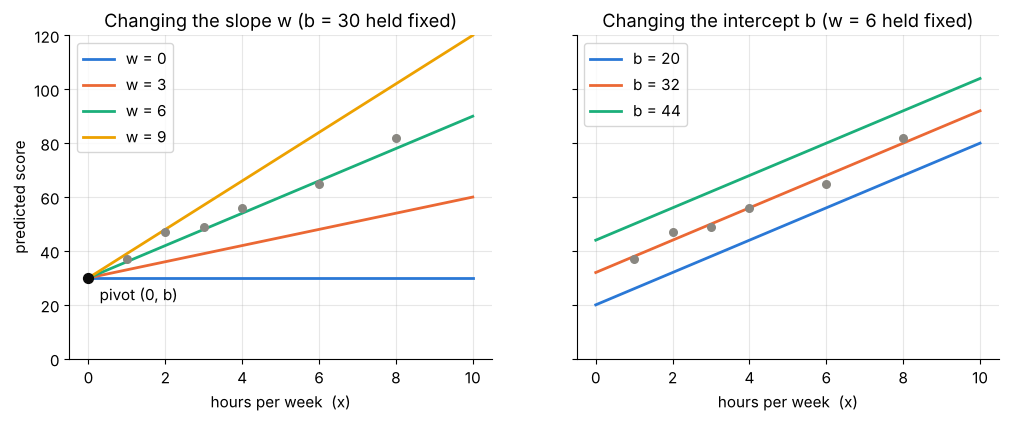

In [4]:
xs = np.linspace(0, 10, 50)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)

ax = axes[0]
for k, w_ in enumerate([0, 3, 6, 9]):
    ax.plot(xs, w_ * xs + 30, color=PALETTE[k], lw=2, label=f"w = {w_}")
ax.scatter(x, y, s=30, color=MUTED, zorder=3)
ax.scatter([0], [30], s=50, color=INK, zorder=4)
ax.annotate("pivot (0, b)", (0, 30), textcoords="offset points", xytext=(8, -16))
ax.set(title="Changing the slope w (b = 30 held fixed)", xlabel="hours per week  (x)",
       ylabel="predicted score", ylim=(0, 120))
ax.legend(loc="upper left")

ax = axes[1]
for k, b_ in enumerate([20, 32, 44]):
    ax.plot(xs, 6 * xs + b_, color=PALETTE[k], lw=2, label=f"b = {b_}")
ax.scatter(x, y, s=30, color=MUTED, zorder=3)
ax.set(title="Changing the intercept b (w = 6 held fixed)", xlabel="hours per week  (x)")
ax.legend(loc="upper left")
plt.show()

Left: the slope tilts the line around $(0, b)$. Right: the intercept shifts it up and down in
parallel. The gray points are our students, and the line $w = 6$, $b = 32$ on the right looks
very promising. We will later *prove* it is the best line for this data.

> **Common pitfall.** Do not over-interpret $b$. It is the predicted score of a student who
> practices **zero** hours, but nobody in our data practiced fewer than 1 hour. Using the line
> outside the range of the data (*extrapolation*) is risky: the true relationship may bend
> there. Within the data range, $w$ is the useful number: "each extra weekly hour goes with
> about $w$ more points".

**Quick check.**
1. With $w = 6$ and $b = 32$, how much does the prediction change when practice goes from
   5 to 7 hours per week?
2. You add 3 to $b$ and leave $w$ alone. Which predictions change, and by how much?
3. You add 1 to $w$ and leave $b$ alone. By how much does the prediction for Dana ($x = 8$) change?
   For a hypothetical student with $x = 0$?

<details>
<summary>Answer</summary>

1. Two extra hours times 6 points per hour $= 12$ points (from 62 to 74).
2. All of them, each by exactly $+3$: the line moves up in parallel.
3. Dana's prediction rises by $1 \times 8 = 8$ points, and the prediction at $x = 0$ does not change
   at all, because that is the pivot of the rotation.
</details>

## 2. Measuring mistakes: residuals and loss functions

Before we can *find* the best line we must define what "best" means. Here are four candidate
lines. Which one would you pick?

| name | line | story |
|---|---|---|
| A | $\hat y = 2x + 20$ | the coach's first rough guess |
| B | $\hat y = 8x + 25$ | passes exactly through Ava's point $(3, 49)$ |
| C | $\hat y = 5x + 38$ | a line drawn "by eye" |
| D | $\hat y = 6x + 32$ | the line we will eventually learn |

Line A is clearly too low. Choosing between B, C and D by eye is much harder, and an
algorithm cannot "look" anyway. We need **one number per line** that measures how wrong it is.

### 2.1 Residuals: the vertical distances

For a candidate line, the **residual** of sample $i$ is the vertical gap between the true label
and the prediction:

$$
r_i = y_i - \hat y_i = y_i - (w x_i + b).
$$

A positive residual means the point lies **above** the line (the model under-predicts), and a
negative residual means it lies **below** (the model over-predicts). We will also use the
opposite sign, the **error** $e_i = \hat y_i - y_i = -r_i$ (prediction minus truth), because
it appears naturally in the derivatives of Section 4.

> **Common pitfall.** Sign conventions differ between books: statistics usually uses
> $y - \hat y$, machine learning code often uses $\hat y - y$. Both are fine, but never mix
> them inside one calculation. In this notebook: residual $r = y - \hat y$, error $e = \hat y - y$.

Why *vertical* distances and not the shortest (perpendicular) distance to the line? Because
our goal is to predict $y$ from a **known** $x$. The mistake we care about is measured in
points, along the $y$ axis. A perpendicular distance would mix hours and points (different
units!) and would change if you merely rescaled an axis, for example by measuring practice in
minutes.

In [5]:
def predict(x, w, b):
    """Prediction of the line y_hat = w*x + b (works for scalars and NumPy arrays)."""
    return w * x + b


CANDIDATES = {"A": (2.0, 20.0), "B": (8.0, 25.0), "C": (5.0, 38.0), "D": (6.0, 32.0)}

w_c, b_c = CANDIDATES["C"]
table_c = students.copy()
table_c["y_hat"] = predict(x, w_c, b_c)
table_c["residual r = y - y_hat"] = y - table_c["y_hat"]
table_c["r squared"] = table_c["residual r = y - y_hat"] ** 2
display(table_c)
print("sum of residuals:", table_c["residual r = y - y_hat"].sum(),
      "| sum of squared residuals:", table_c["r squared"].sum())

,student,hours,score,y_hat,residual r = y - y_hat,r squared
0,Ava,3,49,53.0,-4.0,16.0
1,Ben,6,65,68.0,-3.0,9.0
2,Chen,1,37,43.0,-6.0,36.0
3,Dana,8,82,78.0,4.0,16.0
4,Eli,4,56,58.0,-2.0,4.0
5,Fay,2,47,48.0,-1.0,1.0


sum of residuals: -12.0 | sum of squared residuals: 82.0


For line C, Ava's residual is $49 - 53 = -4$ (the line over-predicts her by 4 points) and
Dana's is $82 - 78 = +4$ (it under-predicts her by 4). Let us draw these gaps for lines B and C.

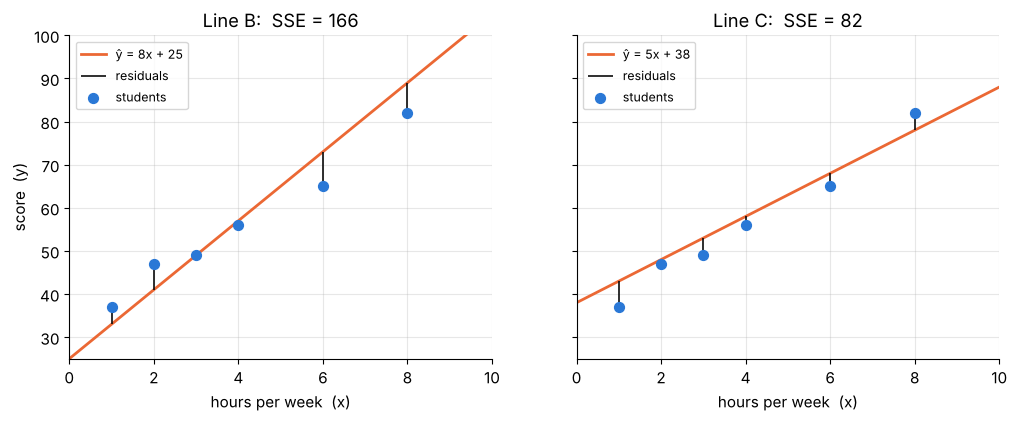

In [6]:
def plot_residuals(ax, w, b, title):
    """Scatter the students, draw the line y = w*x + b and its residuals as vertical segments."""
    y_hat = predict(x, w, b)
    ax.plot(xs, predict(xs, w, b), color=ORANGE, lw=2, label=f"ŷ = {w:g}x + {b:g}")
    ax.vlines(x, np.minimum(y, y_hat), np.maximum(y, y_hat), color=INK, lw=1.2, label="residuals")
    ax.scatter(x, y, s=50, color=BLUE, zorder=3, label="students")
    sse = np.sum((y - y_hat) ** 2)
    ax.set(title=f"{title}:  SSE = {sse:g}", xlabel="hours per week  (x)", xlim=(0, 10), ylim=(25, 100))
    ax.legend(loc="upper left", fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
plot_residuals(axes[0], *CANDIDATES["B"], title="Line B")
plot_residuals(axes[1], *CANDIDATES["C"], title="Line C")
axes[0].set_ylabel("score  (y)")
plt.show()

### 2.2 From many residuals to one number

**First idea: add the residuals up.** That fails, because positive and negative residuals
cancel. The flat line $\hat y = 56$ (always predict the average score) has residuals that sum
to exactly zero, even though it completely ignores practice hours! In fact *any* line through
the point $(\bar x, \bar y)$ has residuals summing to zero (you can check this algebraically:
$\sum_i (y_i - \bar y - w(x_i - \bar x)) = 0 - w \cdot 0$).

**Fix: make every term non-negative.** Two natural options:

* absolute values, $\sum_i |r_i|$, giving the **mean absolute error**
  $\text{MAE} = \frac{1}{n}\sum_i |r_i|$.
* squares, $\sum_i r_i^2$, giving the **sum of squared errors** and its relatives.

### 2.3 SSE, MSE and RMSE

$$
\text{SSE}(w,b) = \sum_{i=1}^{n} \big(y_i - (w x_i + b)\big)^2, \qquad
\text{MSE}(w,b) = \frac{1}{n}\,\text{SSE}(w,b), \qquad
\text{RMSE}(w,b) = \sqrt{\text{MSE}(w,b)} .
$$

* **SSE** (sum of squared errors, also *RSS*, residual sum of squares) grows with the number
  of samples, so it is awkward for comparing datasets of different sizes.
* **MSE** (mean squared error) is the average squared mistake, and it does not depend on $n$
  directly. It is the standard **training loss** and the one we minimize below.
* **RMSE** is back in the units of $y$ (points), so it reads as "a typical mistake is about
  this many points". It is the friendliest number to report.

All three are $\ge 0$, equal $0$ only for a perfect fit, and, because $t \mapsto t/n$ and
$t \mapsto \sqrt{t/n}$ are increasing functions, they are **minimized by the same line**.
They differ in scale, which matters for gradient descent: the gradient of SSE is $n$ times the
gradient of MSE, so a learning rate that suits one is $n$ times too large or too small for the other.

In [7]:
def loss_report(w, b, xx=None, yy=None):
    """Return a dict of error summaries for the line y = w*x + b on (xx, yy) (default: students)."""
    xx = x if xx is None else xx
    yy = y if yy is None else yy
    r = yy - predict(xx, w, b)
    return {"sum of residuals": r.sum(), "SAE (sum |r|)": np.abs(r).sum(), "SSE": np.sum(r ** 2),
            "MSE": np.mean(r ** 2), "RMSE": np.sqrt(np.mean(r ** 2)), "MAE": np.mean(np.abs(r))}


lines = {**{f"{k}: ŷ = {w:g}x + {b:g}": (w, b) for k, (w, b) in CANDIDATES.items()},
         "flat: ŷ = 56": (0.0, 56.0)}
report = pd.DataFrame({name: loss_report(w, b) for name, (w, b) in lines.items()}).T
display(report.round(3))

,sum of residuals,SAE (sum |r|),SSE,MSE,RMSE,MAE
A: ŷ = 2x + 20,168.0,168.0,5272.0,878.667,29.642,28.000
B: ŷ = 8x + 25,-6.0,26.0,166.0,27.667,5.260,4.333
C: ŷ = 5x + 38,-12.0,20.0,82.0,13.667,3.697,3.333
D: ŷ = 6x + 32,0.0,10.0,24.0,4.000,2.000,1.667
flat: ŷ = 56,0.0,70.0,1248.0,208.000,14.422,11.667


Read the table column by column:

* **Sum of residuals** says the flat line and line D are "perfect" (0). Useless as a loss.
* **SSE / MSE / RMSE** rank the lines D (SSE 24) < C (82) < B (166) < flat (1248) < A (5272).
  Line B passes *exactly* through Ava's point, yet it is worse than C: being perfect on one
  student does not make a line good for the group.
* **RMSE** of line D is 2 points, i.e. its typical mistake is about 2 points, and for the coach's
  first guess A it is about 30 points.

### 2.4 Why squared error?

Squared error is the default loss for regression for four reasons.

**1. It is smooth.** $r^2$ has the derivative $2r$ everywhere. $|r|$ has a sharp corner at
$r = 0$ where the derivative jumps from $-1$ to $+1$. Gradient-based training (Section 4) loves
smooth functions.

**2. It punishes big mistakes much more than small ones.**

| residual $r$ | 0.5 | 1 | 2 | 5 | 10 |
|---|---|---|---|---|---|
| absolute $\lvert r\rvert$ | 0.5 | 1 | 2 | 5 | 10 |
| squared $r^2$ | 0.25 | 1 | 4 | 25 | 100 |

Under squared loss, one 10-point miss costs as much as one hundred 1-point misses, so the fit
works hard to avoid large errors. (This is a strength when large errors are truly costly, and
a weakness when they come from flukes or data-entry mistakes. Section 2.5 and Section 9 discuss this further.)

**3. It leads to clean mathematics.** SSE is a quadratic function of $(w, b)$: its graph is a
bowl with a single lowest point (Section 3), and that point has a closed-form formula (Section 8).

**4. It is what probability theory recommends when the noise is Gaussian.** Suppose the data
were generated as "true line plus random noise",

$$
y_i = w x_i + b + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2) \text{ independently}.
$$

Then $y_i$ has the normal density with mean $w x_i + b$:
$p(y_i \mid x_i; w, b) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\big(-\frac{(y_i - w x_i - b)^2}{2\sigma^2}\big)$.
The **likelihood** of the whole dataset is the product of these densities (independence), and
taking logarithms turns the product into a sum:

$$
\log \prod_{i=1}^{n} p(y_i \mid x_i; w, b)
= \underbrace{-\frac{n}{2}\log(2\pi\sigma^2)}_{\text{does not depend on } w,\,b}
\;-\; \frac{1}{2\sigma^2} \sum_{i=1}^{n} (y_i - w x_i - b)^2 .
$$

The only part that depends on $(w, b)$ is $-\text{SSE}(w,b)/(2\sigma^2)$. So **the line that
makes the observed data most probable (the maximum-likelihood line) is exactly the line with
the smallest SSE**. Least squares is not an arbitrary choice: it is the right choice when the
noise is roughly bell-shaped.

> **Going deeper.** Repeat the argument with Laplace noise, $p(\varepsilon) \propto e^{-|\varepsilon|/s}$,
> and the log-likelihood becomes $-\frac{1}{s}\sum_i |y_i - w x_i - b|$ plus a constant:
> maximum likelihood then means minimizing the **absolute** error. Heavy-tailed noise favors
> absolute-type losses. Choosing a loss amounts to stating what you believe about the noise.

### 2.5 Squared vs absolute error: mean vs median

The difference between the two losses is easiest to see in the simplest possible "model":
predict **one constant** $c$ for everybody, ignoring hours.

* Minimizing $\sum_i (y_i - c)^2$: setting the derivative $-2\sum_i (y_i - c)$ to zero gives
  $c = \frac{1}{n}\sum_i y_i = \bar y$, the **mean**.
* Minimizing $\sum_i |y_i - c|$: the derivative is $-\sum_i \operatorname{sign}(y_i - c)$ (number
  of points below $c$ minus number above), which is zero when half the points are on each side:
  $c$ is a **median**.

Now add a seventh score of 2 points (a student who walked out after ten minutes) and watch
what happens to each minimizer.

6 scores                 mean =  56.00   median =  52.50   absolute-loss minimizers: [49, 56]
6 scores + outlier (2)   mean =  48.29   median =  49.00   absolute-loss minimizers: [49, 49]


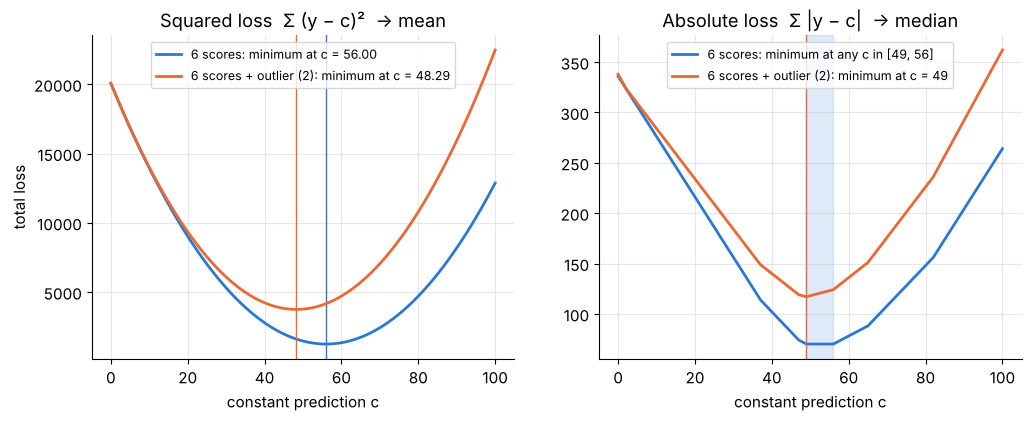

In [8]:
def abs_loss_minimizers(data):
    """Return (lo, hi): every c in [lo, hi] minimizes sum |data - c| (lo == hi when n is odd)."""
    s = np.sort(data)
    k = len(s)
    return s[(k - 1) // 2], s[k // 2]


c_grid = np.linspace(0, 100, 1001)
y_out = np.append(y, 2.0)          # the six scores plus one outlier

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for data, label, color in [(y, "6 scores", BLUE), (y_out, "6 scores + outlier (2)", ORANGE)]:
    sq = ((data[:, None] - c_grid) ** 2).sum(axis=0)
    ab = np.abs(data[:, None] - c_grid).sum(axis=0)
    lo, hi = abs_loss_minimizers(data)
    axes[0].plot(c_grid, sq, color=color, lw=2, label=f"{label}: minimum at c = {data.mean():.2f}")
    axes[0].axvline(data.mean(), color=color, lw=1)
    where = f"c = {lo:g}" if lo == hi else f"any c in [{lo:g}, {hi:g}]"
    axes[1].plot(c_grid, ab, color=color, lw=2, label=f"{label}: minimum at {where}")
    if lo == hi:
        axes[1].axvline(lo, color=color, lw=1)
    else:
        axes[1].axvspan(lo, hi, color=color, alpha=0.15)
    print(f"{label:<24} mean = {data.mean():6.2f}   median = {np.median(data):6.2f}   "
          f"absolute-loss minimizers: [{lo:g}, {hi:g}]")
axes[0].set(title="Squared loss  Σ (y − c)²  → mean", xlabel="constant prediction c", ylabel="total loss")
axes[1].set(title="Absolute loss  Σ |y − c|  → median", xlabel="constant prediction c")
for ax in axes:
    ax.legend(fontsize=9, loc="upper center")
plt.show()

One wild score drags the mean (the squared-loss answer) from 56 down to about 48.29, while the
median (the absolute-loss answer) only moves from 52.5 to 49. The squared loss is a smooth
parabola, while the absolute loss is a chain of straight segments with corners at the data points.

Look closely at the blue absolute-loss curve: with 6 points its bottom is **flat** between the
two middle scores, 49 and 56 (shaded), so *every* $c$ in $[49, 56]$ is a minimizer, and
`np.median` simply reports the midpoint 52.5 by convention. Squared loss never has this
ambiguity: a parabola has exactly one lowest point.

> **Key idea.** Squared error ↔ mean ↔ Gaussian noise: smooth, unique, but sensitive to
> outliers. Absolute error ↔ median ↔ Laplace noise: robust to outliers, but has corners and
> possibly non-unique minimizers. Section 9.5 returns to robust losses for lines.

> **Olympiad tip.** Contest questions love "which constant minimizes the total squared (or
> absolute) distance to these numbers?". The answers are the mean and the median, and the
> derivative argument above is the two-line proof.

### ✏️ Exercise 1: predictions and squared errors

Implement `predict_line(x, w, b)` (the line's predictions) and `squared_errors(y, y_hat)`
(the per-sample squared errors $(\hat y_i - y_i)^2$). Both must work on NumPy arrays.

In [9]:
# ✏️ Exercise 1: predictions and squared errors
def predict_line(x, w, b):
    """Return w*x + b for a NumPy array (or scalar) x."""
    # YOUR CODE HERE
    raise NotImplementedError


def squared_errors(y, y_hat):
    """Return the array of per-sample squared errors (y_hat_i - y_i)**2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = predict_line(np.array([0.0, 1.0, 2.5]), 4.0, 10.0)
    assert np.allclose(out, [10.0, 14.0, 20.0]), f"predict_line gave {out}"
    se = squared_errors(np.array([3.0, 5.0, 7.0]), np.array([1.0, 8.0, 7.0]))
    assert np.allclose(se, [4.0, 9.0, 0.0]), f"squared_errors gave {se}"
    total = squared_errors(y, predict_line(x, 2.0, 20.0)).sum()
    assert np.isclose(total, 5272.0), f"SSE of line A should be 5272, got {total}"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def predict_line(x, w, b):
    return w * x + b

def squared_errors(y, y_hat):
    return (y_hat - y) ** 2
```
NumPy applies `*`, `+` and `**` element by element, so the same one-liners work for a single
number and for a whole array of students.
</details>

### ✏️ Exercise 2: SSE, MSE, RMSE and MAE

Write `regression_metrics(y, y_hat)` returning a dict with keys `"SSE"`, `"MSE"`, `"RMSE"`
and `"MAE"`. Then the checker also verifies your function on line C of our students.

In [10]:
# ✏️ Exercise 2: error summaries
def regression_metrics(y, y_hat):
    """Return {"SSE": ..., "MSE": ..., "RMSE": ..., "MAE": ...} for arrays y and y_hat."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    m = regression_metrics(np.array([2.0, 4.0, 6.0, 8.0]), np.array([3.0, 3.0, 6.0, 10.0]))
    assert set(m) == {"SSE", "MSE", "RMSE", "MAE"}, f"wrong keys: {set(m)}"
    assert np.isclose(m["SSE"], 6.0), f"SSE should be 6, got {m['SSE']}"
    assert np.isclose(m["MSE"], 1.5), f"MSE should be 1.5, got {m['MSE']}"
    assert np.isclose(m["RMSE"], np.sqrt(1.5)), f"RMSE should be sqrt(1.5), got {m['RMSE']}"
    assert np.isclose(m["MAE"], 1.0), f"MAE should be 1, got {m['MAE']}"
    mc = regression_metrics(y, 5.0 * x + 38.0)
    assert np.isclose(mc["SSE"], 82.0) and np.isclose(mc["MAE"], 20 / 6), f"line C metrics wrong: {mc}"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def regression_metrics(y, y_hat):
    r = y - y_hat
    sse = float(np.sum(r ** 2))
    mse = sse / len(y)
    return {"SSE": sse, "MSE": mse, "RMSE": mse ** 0.5, "MAE": float(np.mean(np.abs(r)))}
```
Compute the residuals once, then everything else is a one-line summary of them. Note that the
RMSE is the square root of the *mean*, not the mean of square roots (that would be the MAE).
</details>

## 3. The loss landscape: a parabola and a bowl

From now on our **training loss** is the mean squared error of the line on the six students:

$$
\mathcal{L}(w, b) = \text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n} \big(w x_i + b - y_i\big)^2 .
$$

The data $(x_i, y_i)$ are fixed numbers, and only $w$ and $b$ can change. So $\mathcal{L}$ is an
ordinary function of two variables, and "learning" means finding its lowest point. Before
reaching for any algorithm, let us *look* at this function.

### 3.1 Freeze the slope, vary the intercept: a parabola

Fix $w$ at some value and treat $\mathcal{L}$ as a function of $b$ alone. Write
$u_i = y_i - w x_i$ for the part of each score that the slope term does not explain, so that
$\mathcal{L}(w, b) = \frac{1}{n}\sum_i (b - u_i)^2$. Add and subtract the average $\bar u$:

$$
(b - u_i)^2 = \big((b - \bar u) - (u_i - \bar u)\big)^2
            = (b - \bar u)^2 - 2(b - \bar u)(u_i - \bar u) + (u_i - \bar u)^2 .
$$

Averaging over $i$, the middle term disappears because the deviations $u_i - \bar u$ sum to
zero. What is left is

$$
\mathcal{L}(w, b) = \big(b - b^*(w)\big)^2 + \operatorname{Var}(y - w x),
\qquad b^*(w) = \bar u = \bar y - w \bar x ,
$$

where $\operatorname{Var}$ is the average squared deviation from the mean. Three facts can be
read off directly:

1. For every fixed $w$ the loss is an upward **parabola** in $b$, always with the same
   curvature: its second derivative is exactly $2$.
2. Its lowest point is at $b^*(w) = \bar y - w\bar x$. For our students
   ($\bar x = 4$, $\bar y = 56$) that is $b^*(w) = 56 - 4w$.
3. The height of that lowest point, $\operatorname{Var}(y - wx)$, depends on $w$: a bad slope
   cannot be rescued by a good intercept.

w = 2:  best intercept b* =   48,  lowest MSE =  94.667
w = 4:  best intercept b* =   40,  lowest MSE =  26.667
w = 6:  best intercept b* =   32,  lowest MSE =   4.000


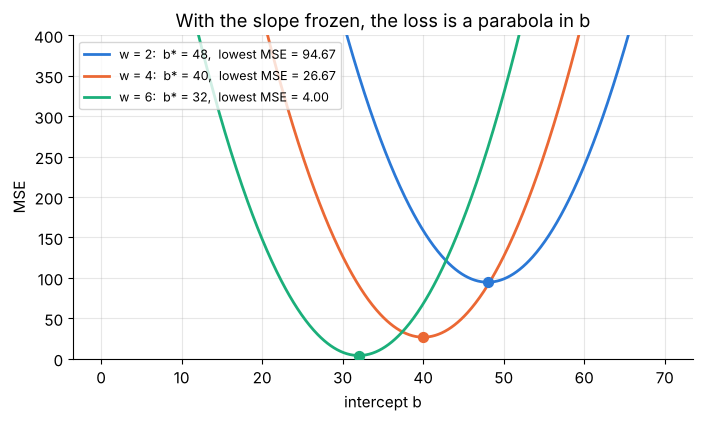

In [11]:
def mse(w, b, xx=None, yy=None):
    """Training loss: mean squared error of the line y = w*x + b (default data: the students)."""
    xx = x if xx is None else xx
    yy = y if yy is None else yy
    return float(np.mean((w * xx + b - yy) ** 2))


b_grid = np.linspace(0, 70, 701)
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, w_fix in enumerate([2.0, 4.0, 6.0]):
    curve = [mse(w_fix, b_) for b_ in b_grid]
    b_star = y.mean() - w_fix * x.mean()          # vertex predicted by the formula
    floor = np.var(y - w_fix * x)                 # height of the vertex predicted by the formula
    assert np.isclose(mse(w_fix, b_star), floor)  # formula agrees with direct computation
    ax.plot(b_grid, curve, color=PALETTE[k], lw=2,
            label=f"w = {w_fix:g}:  b* = {b_star:g},  lowest MSE = {floor:.2f}")
    ax.scatter([b_star], [floor], color=PALETTE[k], s=50, zorder=3)
    print(f"w = {w_fix:g}:  best intercept b* = {b_star:4.0f},  lowest MSE = {floor:7.3f}")
ax.set(xlabel="intercept b", ylabel="MSE", ylim=(0, 400),
       title="With the slope frozen, the loss is a parabola in b")
ax.legend(fontsize=9)
plt.show()

The three parabolas are the same shape slid to different places. With the coach's slope
$w = 2$, the best intercept is $b = 48$, but even there the MSE is 94.67. With $w = 6$, the
best intercept is $32$ and the MSE drops to $4$. To find the best line we must tune **both**
numbers together, so let us look at the loss over the whole $(w, b)$ plane.

### 3.2 Both parameters: a convex bowl

Expanding the square $(w x_i + b - y_i)^2 = x_i^2 w^2 + 2x_i\, w b + b^2 - 2x_i y_i\, w - 2 y_i\, b + y_i^2$
and averaging over students gives

$$
\mathcal{L}(w, b) = \overline{x^2}\, w^2 + 2\bar x\, w b + b^2 - 2\,\overline{xy}\, w - 2\bar y\, b + \overline{y^2},
$$

where a bar means "average over the students", e.g. $\overline{x^2} = \frac{1}{n}\sum_i x_i^2$
and $\overline{xy} = \frac{1}{n}\sum_i x_i y_i$. Whatever the data, the loss is a **quadratic
function of $(w, b)$**. Let us compute its coefficients and double-check the expansion.

In [12]:
x2_bar, xy_bar, y2_bar = np.mean(x ** 2), np.mean(x * y), np.mean(y ** 2)
print(f"mean(x²) = {x2_bar:.4f}   mean(x) = {x.mean():g}   mean(xy) = {xy_bar:g}   "
      f"mean(y) = {y.mean():g}   mean(y²) = {y2_bar:g}")
print(f"L(w, b) = {x2_bar:.4f} w² + {2 * x.mean():g} wb + b² − {2 * xy_bar:g} w − {2 * y.mean():g} b + {y2_bar:g}")


def mse_quadratic(w, b):
    """The same loss, evaluated through the expanded quadratic formula."""
    return x2_bar * w**2 + 2 * x.mean() * w * b + b**2 - 2 * xy_bar * w - 2 * y.mean() * b + y2_bar


for w_, b_ in [(2, 20), (8, 25), (-3.7, 51.2)]:
    print(f"(w, b) = ({w_:5}, {b_:5}):  direct MSE = {mse(w_, b_):10.4f}   quadratic formula = {mse_quadratic(w_, b_):10.4f}")

mean(x²) = 21.6667   mean(x) = 4   mean(xy) = 258   mean(y) = 56   mean(y²) = 3344
L(w, b) = 21.6667 w² + 8 wb + b² − 516 w − 112 b + 3344
(w, b) = (    2,    20):  direct MSE =   878.6667   quadratic formula =   878.6667
(w, b) = (    8,    25):  direct MSE =    27.6667   quadratic formula =    27.6667
(w, b) = ( -3.7,  51.2):  direct MSE =   921.3367   quadratic formula =   921.3367


A quadratic function of two variables whose "square terms" win in every direction is a
**bowl** (a paraboloid). Let us draw it twice: as a 3-D surface, and as a **contour map**, a
view from above in which each gray curve connects all $(w, b)$ with the same loss, like height
lines on a hiking map. The helpers below are reused for the rest of the notebook.

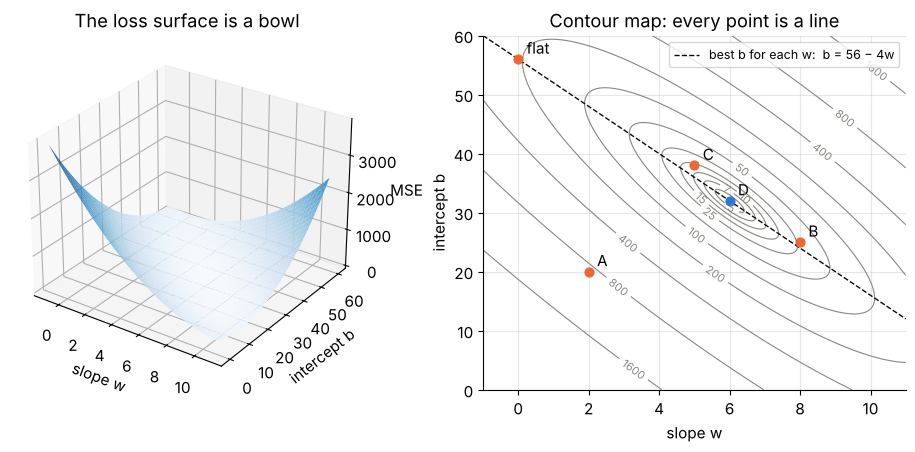

lowest grid point: w = 6.00, b = 32.00, MSE = 4.000


In [13]:
def mse_grid(W, B, xx=None, yy=None):
    """MSE for every (w, b) pair of a meshgrid, where broadcasting adds a last axis over the samples."""
    xx = x if xx is None else xx
    yy = y if yy is None else yy
    return np.mean((W[..., None] * xx + B[..., None] - yy) ** 2, axis=-1)


LEVELS = [5, 7, 10, 15, 25, 50, 100, 200, 400, 800, 1600]


def draw_contours(ax, wlim=(-1, 11), blim=(0, 60), levels=LEVELS, xx=None, yy=None, labels=True):
    """Draw MSE contour lines on the (w, b) plane and return the lowest grid point (w, b, MSE)."""
    Wg, Bg = np.meshgrid(np.linspace(*wlim, 301), np.linspace(*blim, 301))
    Z = mse_grid(Wg, Bg, xx, yy)
    cs = ax.contour(Wg, Bg, Z, levels=levels, colors=MUTED, linewidths=0.8)
    if labels:
        ax.clabel(cs, fmt="%g", fontsize=8)
    ax.set(xlabel="slope w", ylabel="intercept b", xlim=wlim, ylim=blim)
    k = np.unravel_index(Z.argmin(), Z.shape)
    return Wg[k], Bg[k], Z[k]


Wg, Bg = np.meshgrid(np.linspace(-1, 11, 121), np.linspace(0, 60, 121))
fig = plt.figure(figsize=(12, 4.6))
ax3 = fig.add_subplot(1, 2, 1, projection="3d")
ax3.plot_surface(Wg, Bg, mse_grid(Wg, Bg), cmap="Blues", linewidth=0, alpha=0.95)
ax3.set(xlabel="slope w", ylabel="intercept b", zlabel="MSE", title="The loss surface is a bowl")
ax3.view_init(elev=28, azim=-55)

ax = fig.add_subplot(1, 2, 2)
w_low, b_low, z_low = draw_contours(ax)
w_line = np.linspace(-1, 11, 10)
ax.plot(w_line, 56 - 4 * w_line, color=INK, lw=1, ls="--", label="best b for each w:  b = 56 − 4w")
for name, (w_, b_) in {**CANDIDATES, "flat": (0.0, 56.0)}.items():
    ax.scatter(w_, b_, s=40, color=BLUE if name == "D" else ORANGE, zorder=3)
    ax.annotate(name, (w_, b_), textcoords="offset points", xytext=(6, 4))
ax.set_title("Contour map: every point is a line")
ax.legend(loc="upper right", fontsize=9)
plt.show()
print(f"lowest grid point: w = {w_low:.2f}, b = {b_low:.2f}, MSE = {z_low:.3f}")

How to read the right-hand map: **every point $(w, b)$ is a whole line** in the data plane,
and its "height" is that line's MSE.

* There is a single lowest point. On a fine grid it sits at $w = 6$, $b = 32$ with MSE $4$:
  line D. (Section 8 proves this is exactly the minimum.)
* The coach's guess A is far up the wall (MSE 878.67), the flat line sits at MSE 208, while
  C (13.67) and B (27.67) are on the lower slopes, matching the table of Section 2.3.
* The contours are long, thin, **tilted** ellipses: the bowl is really a narrow valley.

### 3.3 Why is the valley thin and tilted?

The tilt comes from the cross term $2\bar x\, wb = 8wb$. Suppose you raise the slope by 1.
Near the middle of the data ($x \approx \bar x = 4$) every prediction goes up by about 4
points, and you can almost exactly undo that by lowering $b$ by 4. The line then *pivots
about the center of the data* and stays close to most students, so the loss barely changes.
Changing $w$ alone or $b$ alone instead moves the line away from everybody.

In [14]:
for w_, b_, what in [(7, 32, "slope +1 only"), (6, 36, "intercept +4 only"),
                     (7, 28, "slope +1 and intercept −4 (pivot about (4, 56))")]:
    print(f"(w, b) = ({w_}, {b_}):  MSE = {mse(w_, b_):6.2f}   <- {what}")

(w, b) = (7, 32):  MSE =  25.67   <- slope +1 only
(w, b) = (6, 36):  MSE =  20.00   <- intercept +4 only
(w, b) = (7, 28):  MSE =   9.67   <- slope +1 and intercept −4 (pivot about (4, 56))


Starting from the best line (MSE 4): raising the slope alone costs $+21.67$, raising the
intercept by 4 alone costs $+16$, but doing *both* moves "slope +1, intercept −4" costs only
$+5.67$, because that combined move travels along the valley.

The dashed line $b = 56 - 4w$ on the map collects, for every slope, the best intercept from
Section 3.1. Since $b = \bar y - w\bar x \iff \bar y = w\bar x + b$, these are exactly **the
lines that pass through the center of the data** $(\bar x, \bar y) = (4, 56)$: walking along
the valley floor rotates the line about the data's center.

> **Key idea.** Every slice of the bowl with $w$ fixed has curvature
> $\partial^2\mathcal{L}/\partial b^2 = 2$, and every slice with $b$ fixed has curvature
> $\partial^2\mathcal{L}/\partial w^2 = 2\,\overline{x^2} \approx 43.3$. The walls are about
> 22 times steeper in the $w$ direction than in the $b$ direction. This mismatch in curvature,
> plus the tilt, will make gradient descent zig-zag and crawl (Section 7), and centering the
> feature will fix it.

> **Going deeper.** The bowl is **convex**: it curves upward in every direction, so it has one
> global minimum and no other valleys to get trapped in. Formally, the matrix of second
> derivatives (the Hessian, Section 7) is $2\begin{pmatrix}\overline{x^2} & \bar x \\ \bar x & 1\end{pmatrix}$,
> whose determinant $4(\overline{x^2} - \bar x^2) = 4\operatorname{Var}(x)$ is positive unless
> all students practiced exactly the same hours. Neural networks lose this luxury, which is
> why their training is so much harder to analyze.

**Quick check.** The flat line $(0, 56)$ lies exactly on the dashed valley floor, while line B
$(8, 25)$ does not. Yet the flat line's MSE (208) is far worse than B's (27.67). How can a
point on the valley floor be so high?

<details>
<summary>Answer</summary>

The valley floor only means "the best intercept *for this slope*". By Section 3.1 its height
is $\operatorname{Var}(y - wx)$, which depends on the slope: for $w = 0$ it is
$\operatorname{Var}(y) = 208$, while for $w = 8$ it is $\operatorname{Var}(y - 8x) = 26.67$.
Line B has a far better slope and pays only $(25 - b^*(8))^2 = (25 - 24)^2 = 1$ extra for its
slightly-off intercept: $26.67 + 1 = 27.67$. A good slope matters more than a perfect intercept.
</details>

### ✏️ Exercise 3: the SSE of many lines at once

The contour map needed the loss of about 90,000 different lines. Write
`sse_for_params(W, B, x, y)` that returns the SSE of the line $\hat y = W x + B$ for **every**
pair of parameters at once. `W` and `B` are NumPy arrays of the same (arbitrary) shape, `x`
and `y` are 1-D arrays of length $n$, and the result must have the same shape as `W`. Avoid
Python loops: add a trailing axis with `W[..., None]` so that broadcasting pairs every
parameter pair with every sample, then sum over that last axis.

Warm-up by hand first: what is the SSE of the line $\hat y = 7x + 30$ on our six students?
(The checker knows.)

In [15]:
# ✏️ Exercise 3: the SSE of many lines at once
def sse_for_params(W, B, x, y):
    """Return an array (same shape as W) with the SSE of the line y = W*x + B on data (x, y)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    W_test = np.array([2.0, 8.0, 5.0, 6.0, 7.0])
    B_test = np.array([20.0, 25.0, 38.0, 32.0, 30.0])
    out = sse_for_params(W_test, B_test, x, y)
    assert np.shape(out) == (5,), f"expected shape (5,), got {np.shape(out)}"
    assert np.allclose(out[:4], [5272.0, 166.0, 82.0, 24.0]), f"lines A-D should give 5272, 166, 82, 24, but got {out[:4]}"
    assert np.isclose(out[4], 82.0), f"the line 7x + 30 has SSE 82 (same as line C!), got {out[4]}"
    Wg, Bg = np.meshgrid(np.linspace(0, 10, 7), np.linspace(10, 50, 5))
    grid = sse_for_params(Wg, Bg, x, y)
    assert np.shape(grid) == (5, 7), f"a (5, 7) grid of parameters must give a (5, 7) result, got {np.shape(grid)}"
    assert np.allclose(grid, n * mse_grid(Wg, Bg)), "grid values disagree with n * mse_grid"
    tiny = sse_for_params(np.array([1.0]), np.array([0.0]), np.array([1.0, 2.0]), np.array([2.0, 2.0]))
    assert np.allclose(tiny, [1.0]), f"line y = x on points (1, 2), (2, 2) has SSE 1, got {tiny}"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sse_for_params(W, B, x, y):
    W, B = np.asarray(W, dtype=float), np.asarray(B, dtype=float)
    residuals = y - (W[..., None] * x + B[..., None])   # shape W.shape + (n,)
    return np.sum(residuals ** 2, axis=-1)
```
`W[..., None]` has shape `W.shape + (1,)`, which broadcasts against `x` of shape `(n,)` to
`W.shape + (n,)`: one row of $n$ residuals for every parameter pair. Summing over the last
axis leaves one SSE per pair. By hand, $\hat y = 7x + 30$ predicts 51, 72, 37, 86, 58, 44,
the residuals are $-2, -7, 0, -4, -2, 3$, and their squares add up to $4 + 49 + 0 + 16 + 4 + 9 = 82$.
</details>

## 4. Which way is downhill? Derivatives and gradients

The contour map shows where the minimum is, but only because we evaluated the loss at about
90,000 grid points. That brute force is hopeless for real models: with a million parameters,
even a coarse grid of 10 values per parameter would need $10^{1{,}000{,}000}$ evaluations.
Instead we will stand at one point, feel the slope under our feet, and step downhill. The tool
that measures "the slope under our feet" is the **derivative**.

### 4.1 A derivative refresher

For a function $g$ of one variable, the derivative

$$
g'(t) = \lim_{h \to 0} \frac{g(t + h) - g(t)}{h}
$$

is the slope of the tangent line at $t$, so that $g(t + h) \approx g(t) + g'(t)\, h$ for small
$h$. Its **sign** tells you the direction: if $g'(t) > 0$ the function rises to the right (to
go down, move left), if $g'(t) < 0$ it falls to the right (move right), and at the bottom of a
smooth valley $g'(t) = 0$. Its **size** tells you how steep it is.

Take the parabola from Section 3.1 with the slope frozen at $w = 6$:

$$
\mathcal{L}(b) = (b - 32)^2 + 4, \qquad \mathcal{L}'(b) = 2(b - 32).
$$

b = 20:  L'(b) from the formula = -24.0000,  finite difference = -24.0000
b = 26:  L'(b) from the formula = -12.0000,  finite difference = -12.0000
b = 32:  L'(b) from the formula = +0.0000,  finite difference = +0.0000
b = 40:  L'(b) from the formula = +16.0000,  finite difference = +16.0000


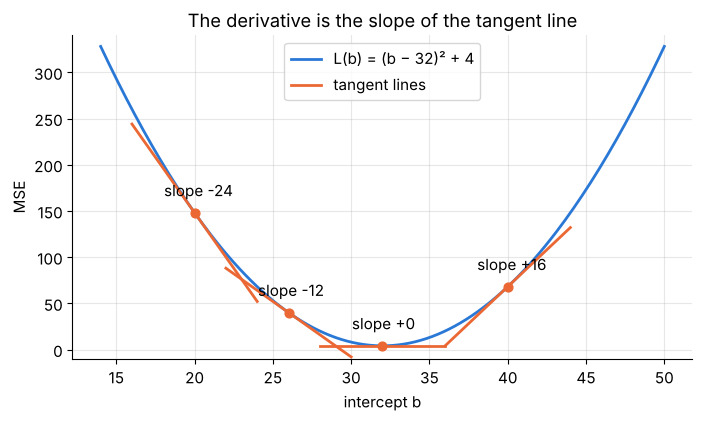

In [16]:
def loss_b(b, w_fixed=6.0):
    """Training MSE as a function of the intercept alone (slope frozen at w_fixed)."""
    return mse(w_fixed, b)


def num_deriv(g, t, h=1e-5):
    """Central finite-difference estimate of g'(t)."""
    return (g(t + h) - g(t - h)) / (2 * h)


b_line = np.linspace(14, 50, 200)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(b_line, [loss_b(b_) for b_ in b_line], color=BLUE, lw=2, label="L(b) = (b − 32)² + 4")
for k, b0 in enumerate([20, 26, 32, 40]):
    slope = 2 * (b0 - 32)
    seg = np.array([b0 - 4, b0 + 4])
    ax.plot(seg, loss_b(b0) + slope * (seg - b0), color=ORANGE, lw=2,
            label="tangent lines" if k == 0 else None)
    ax.scatter([b0], [loss_b(b0)], color=ORANGE, s=40, zorder=3)
    ax.annotate(f"slope {slope:+g}", (b0, loss_b(b0)), textcoords="offset points", xytext=(-22, 12))
    print(f"b = {b0}:  L'(b) from the formula = {slope:+.4f},  finite difference = {num_deriv(loss_b, b0):+.4f}")
ax.set(xlabel="intercept b", ylabel="MSE", ylim=(-10, 340),
       title="The derivative is the slope of the tangent line")
ax.legend()
plt.show()

At $b = 20$ the slope is $-24$: the loss falls to the right, so we should *increase* $b$. At
$b = 40$ the slope is $+16$: decrease $b$. At $b = 32$ the tangent is flat: we are at the
bottom. The finite-difference estimates agree with the formula (for a parabola the central
difference is exact up to rounding), which is a handy way to test derivative code.

### 4.2 Gradient descent in one dimension

The rule "step *against* the derivative, by an amount proportional to it" is called
**gradient descent**:

$$
b_{\text{new}} = b - \eta\, \mathcal{L}'(b),
$$

where the **learning rate** $\eta > 0$ (Greek *eta*) sets the step size. The minus sign is the
whole trick: a positive derivative (uphill to the right) makes us step left, and vice versa.
Why proportional to the derivative? Far from the bottom the slope is steep and we take big
steps. Near the bottom it flattens and the steps shrink automatically.

For our parabola the update can be solved exactly:

$$
b_{t+1} = b_t - \eta \cdot 2(b_t - 32)
\quad\Longrightarrow\quad
b_{t+1} - 32 = (1 - 2\eta)\,(b_t - 32).
$$

Each step multiplies the distance to the minimum by the same factor $1 - 2\eta$. With
$\eta = 0.2$ the factor is $0.6$: from $b_0 = 20$ (12 below the minimum) we get
$b_1 = 32 - 0.6 \cdot 12 = 24.8$, then $b_2 = 32 - 0.6^2 \cdot 12 = 27.68$, and so on.
(Section 7 explores other values of $\eta$, and something dramatic happens at $\eta = 1$.)

,t,b_t,L(b_t),L'(b_t),step −η·L'
0,0,20.0000,148.0000,-24.0000,4.8000
1,1,24.8000,55.8400,-14.4000,2.8800
2,2,27.6800,22.6624,-8.6400,1.7280
3,3,29.4080,10.7185,-5.1840,1.0368
4,4,30.4448,6.4186,-3.1104,0.6221
5,5,31.0669,4.8707,-1.8662,0.3732
6,6,31.4401,4.3135,-1.1197,0.2239
7,7,31.6641,4.1128,-0.6718,0.1344


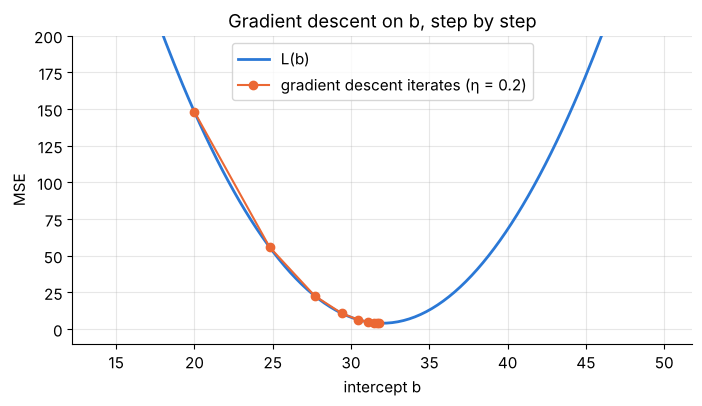

In [17]:
eta, b_t = 0.2, 20.0
rows, path_b = [], [b_t]
for t in range(8):
    grad = 2 * (b_t - 32)
    rows.append({"t": t, "b_t": b_t, "L(b_t)": loss_b(b_t), "L'(b_t)": grad, "step −η·L'": -eta * grad})
    b_t = b_t - eta * grad
    path_b.append(b_t)
display(pd.DataFrame(rows).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(b_line, [loss_b(b_) for b_ in b_line], color=BLUE, lw=2, label="L(b)")
ax.plot(path_b, [loss_b(b_) for b_ in path_b], "o-", color=ORANGE, ms=6, lw=1.5,
        label="gradient descent iterates (η = 0.2)")
ax.set(xlabel="intercept b", ylabel="MSE", ylim=(-10, 200), title="Gradient descent on b, step by step")
ax.legend()
plt.show()

The steps shrink geometrically (4.8, 2.88, 1.73, ...) because the derivative shrinks as we
approach the bottom: there is no need to "brake" by hand.

### 4.3 Per-sample gradients with the chain rule

Now back to two parameters. We start with the loss of a **single** student $i$,

$$
\ell_i(w, b) = (\hat y_i - y_i)^2, \qquad \hat y_i = w x_i + b ,
$$

because the training procedure in Section 5 updates the line one student at a time. The
loss is a chain of simple operations. Here is its **computational graph**:

```text
  w ──┐
      (×)── w·x ──┐
  x ──┘           (+)── ŷ ──(− y)── e = ŷ − y ──(square)── ℓ = e²
  b ──────────────┘
```

Each node has a simple *local* derivative:

| node | output | local derivative |
|---|---|---|
| square | $\ell = e^2$ | $\partial \ell / \partial e = 2e$ |
| subtract $y$ | $e = \hat y - y$ | $\partial e / \partial \hat y = 1$ |
| add $b$ | $\hat y = wx + b$ | $\partial \hat y / \partial b = 1$ |
| multiply | $wx$ (feeds into $\hat y$) | $\partial \hat y / \partial w = x$ |

The **chain rule** says: to get the derivative of $\ell$ with respect to a parameter, multiply
the local derivatives along the path from $\ell$ back to that parameter:

$$
\frac{\partial \ell}{\partial w}
= \frac{\partial \ell}{\partial e}\cdot\frac{\partial e}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial w}
= 2e \cdot 1 \cdot x = 2x(\hat y - y),
\qquad
\frac{\partial \ell}{\partial b}
= \frac{\partial \ell}{\partial e}\cdot\frac{\partial e}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial b}
= 2e \cdot 1 \cdot 1 = 2(\hat y - y).
$$

Double-check without the chain rule by expanding
$\ell = (wx + b - y)^2 = w^2x^2 + 2wx(b - y) + (b - y)^2$: then
$\partial \ell/\partial w = 2wx^2 + 2x(b - y) = 2x(wx + b - y)$ and
$\partial \ell/\partial b = 2wx + 2(b - y) = 2(wx + b - y)$. Same answers, so the derivation holds.

**Reading the formulas.**

* **Sign.** If the prediction is too low ($e < 0$), both gradients are negative (for $x > 0$),
  so the update $\theta \leftarrow \theta - \eta \cdot \text{gradient}$ *increases* $w$ and $b$,
  which raises the prediction. Exactly what we want.
* **Size.** Both gradients are proportional to the error: big mistakes cause big corrections,
  a perfect prediction ($e = 0$) causes none.
* **The lever arm $x$.** Changing $w$ by $\Delta$ moves this student's prediction by
  $x\Delta$, so the student's "complaint" about $w$ is scaled by $x$. Dana ($x = 8$) pushes on
  the slope eight times harder than on the intercept, and a student with $x = 0$ says nothing about
  the slope at all.
* **Direction.** $\nabla \ell_i = \big(\partial \ell_i/\partial w,\ \partial \ell_i/\partial b\big)
  = 2e_i\,(x_i,\ 1)$: one student can only push the parameters along their own direction
  $(x_i, 1)$. We will use this geometric fact in Sections 5 and 6.

> **Olympiad tip.** In hand-calculation problems, compute the error $e = \hat y - y$ once, then
> $\partial \ell/\partial b = 2e$ and $\partial \ell/\partial w = x \cdot \partial \ell/\partial b$.
> Writing $e$ with its sign first prevents most mistakes.

### 4.4 The gradient of the full training loss

The training loss is the average of the per-student losses, $\mathcal{L} = \frac{1}{n}\sum_i \ell_i$,
and the derivative of an average is the average of the derivatives:

$$
\frac{\partial \mathcal{L}}{\partial w} = \frac{2}{n}\sum_{i=1}^{n} x_i(\hat y_i - y_i),
\qquad
\frac{\partial \mathcal{L}}{\partial b} = \frac{2}{n}\sum_{i=1}^{n} (\hat y_i - y_i).
$$

The pair $\nabla\mathcal{L} = (\partial\mathcal{L}/\partial w,\ \partial\mathcal{L}/\partial b)$
is the **gradient**. It points in the direction of steepest *ascent* and is perpendicular to
the contour line through the current point, while $-\nabla\mathcal{L}$ points straight downhill. In
matrix form, with the design matrix $X = [\mathbf{x}\ \ \mathbf{1}] \in \mathbb{R}^{n\times 2}$
(a column of hours and a column of ones) and $\boldsymbol\theta = (w, b)^\top$,

$$
\nabla_{\boldsymbol\theta}\mathcal{L} = \frac{2}{n} X^\top \big(X\boldsymbol\theta - \mathbf{y}\big) \in \mathbb{R}^{2},
$$

the form that generalizes to many features in later notebooks. Let us evaluate everything at
the coach's guess $(w, b) = (2, 20)$.

In [18]:
w0, b0 = 2.0, 20.0
e0 = predict(x, w0, b0) - y                     # errors e_i = y_hat_i - y_i
per_sample = students.copy()
per_sample["y_hat"] = predict(x, w0, b0)
per_sample["e = y_hat - y"] = e0
per_sample["dl/dw = 2x·e"] = 2 * x * e0
per_sample["dl/db = 2e"] = 2 * e0
display(per_sample)

grad_avg = np.array([np.mean(2 * x * e0), np.mean(2 * e0)])
X = np.column_stack([x, np.ones(n)])            # design matrix, shape (6, 2)
grad_matrix = 2 / n * X.T @ (X @ np.array([w0, b0]) - y)
print("average of per-sample gradients :", grad_avg.round(4))
print("matrix formula (2/n) Xᵀ(Xθ − y) :", grad_matrix.round(4))

,student,hours,score,y_hat,e = y_hat - y,dl/dw = 2x·e,dl/db = 2e
0,Ava,3,49,26.0,-23.0,-138.0,-46.0
1,Ben,6,65,32.0,-33.0,-396.0,-66.0
2,Chen,1,37,22.0,-15.0,-30.0,-30.0
3,Dana,8,82,36.0,-46.0,-736.0,-92.0
4,Eli,4,56,28.0,-28.0,-224.0,-56.0
5,Fay,2,47,24.0,-23.0,-92.0,-46.0


average of per-sample gradients : [-269.3333  -56.    ]
matrix formula (2/n) Xᵀ(Xθ − y) : [-269.3333  -56.    ]


Every student is under-predicted by the coach's line (all errors are negative), so every
per-sample gradient is negative in both components. Dana, with the largest lever arm and the
largest error, contributes $-736$ to the slope component on her own. The full gradient
$(-269.33, -56)$ says: increase both parameters, and the slope much more urgently.

### 4.5 Gradient checking

Hand-derived gradients are a classic source of bugs, so professionals verify them against
finite differences: nudge one parameter by a tiny $h$ in each direction and measure the
change in loss,

$$
\frac{\partial \mathcal{L}}{\partial w} \approx \frac{\mathcal{L}(w + h, b) - \mathcal{L}(w - h, b)}{2h}.
$$

In [19]:
def grad_mse(w, b, xx=None, yy=None):
    """Analytic gradient (dL/dw, dL/db) of the training MSE."""
    xx = x if xx is None else xx
    yy = y if yy is None else yy
    e = w * xx + b - yy
    return np.array([np.mean(2 * xx * e), np.mean(2 * e)])


def grad_numeric(f, w, b, h=1e-5):
    """Central finite-difference gradient of a function f(w, b)."""
    return np.array([(f(w + h, b) - f(w - h, b)) / (2 * h), (f(w, b + h) - f(w, b - h)) / (2 * h)])


for w_, b_ in [(2.0, 20.0), (7.3, 18.6)]:
    print(f"at (w, b) = ({w_}, {b_}):  analytic {grad_mse(w_, b_).round(6)}   numeric {grad_numeric(mse, w_, b_).round(6)}")

ava_loss = lambda w_, b_: (w_ * 3 + b_ - 49) ** 2   # the loss of Ava alone
print("Ava alone at (2, 20): analytic", np.array([2 * 3 * (26 - 49), 2 * (26 - 49)]),
      "  numeric", grad_numeric(ava_loss, 2.0, 20.0).round(6))

at (w, b) = (2.0, 20.0):  analytic [-269.333333  -56.      ]   numeric [-269.333333  -56.      ]
at (w, b) = (7.3, 18.6):  analytic [-50.866667 -16.4     ]   numeric [-50.866667 -16.4     ]
Ava alone at (2, 20): analytic [-138  -46]   numeric [-138.  -46.]


Analytic and numerical gradients agree to many decimal places. If they did not, the analytic
code would be wrong (or $h$ badly chosen: too large and the approximation is crude, too small,
say $10^{-12}$, and floating-point rounding takes over).

**Quick check.** A student with $x_i = 0$ hours and error $e_i = -5$ is processed. Which
parameters change, and in which direction?

<details>
<summary>Answer</summary>

$\partial\ell/\partial w = 2 \cdot 0 \cdot (-5) = 0$, so $w$ does not move: a student at
$x = 0$ carries no information about the slope. $\partial\ell/\partial b = 2(-5) = -10$, so
$b \leftarrow b + 10\eta$ increases, lifting the whole line toward the under-predicted student.
</details>

### ✏️ Exercise 4: per-sample gradients

Implement `grad_sample(xi, yi, w, b)` returning the tuple
$\big(\partial\ell/\partial w,\ \partial\ell/\partial b\big)$ for the single-sample loss
$\ell = (w x_i + b - y_i)^2$.

In [20]:
# ✏️ Exercise 4: per-sample gradients
def grad_sample(xi, yi, w, b):
    """Return (dl/dw, dl/db) for l = (w*xi + b - yi)**2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.allclose(grad_sample(3.0, 49.0, 2.0, 20.0), (-138.0, -46.0)), "Ava at (2, 20) should give (-138, -46)"
    assert np.allclose(grad_sample(0.0, 5.0, 1.0, 2.0), (0.0, -6.0)), "with x = 0 the w-gradient must be 0"
    assert np.allclose(grad_sample(-2.0, 1.0, 0.5, 0.0), (8.0, -4.0)), "negative x: check your signs"
    f = lambda w_, b_: (w_ * 6.0 + b_ - 65.0) ** 2
    assert np.allclose(grad_sample(6.0, 65.0, 1.3, -2.0), grad_numeric(f, 1.3, -2.0), atol=1e-4), \
        "does not match the finite-difference gradient"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def grad_sample(xi, yi, w, b):
    e = w * xi + b - yi          # error = prediction - truth
    return 2 * xi * e, 2 * e
```
Compute the error once. The intercept gradient is $2e$ and the slope gradient is the same
quantity times the lever arm $x_i$.
</details>

### ✏️ Exercise 5: one SGD step

Implement `sgd_step(xi, yi, w, b, lr)`: compute the per-sample gradients and return the
updated pair `(w_new, b_new)` using $w \leftarrow w - \eta\,\partial\ell/\partial w$ and
$b \leftarrow b - \eta\,\partial\ell/\partial b$ (use the *old* $w$ and $b$ for both gradients).

In [21]:
# ✏️ Exercise 5: one stochastic gradient descent step
def sgd_step(xi, yi, w, b, lr):
    """Return (w_new, b_new) after one gradient step on the loss of the single sample (xi, yi)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    w1, b1 = sgd_step(3.0, 49.0, 2.0, 20.0, 0.005)
    assert np.allclose((w1, b1), (2.69, 20.23)), f"expected (2.69, 20.23), got {(w1, b1)}"
    w2, b2 = sgd_step(6.0, 65.0, w1, b1, 0.005)
    assert np.allclose((w2, b2), (4.4078, 20.5163)), f"expected (4.4078, 20.5163), got {(w2, b2)}"
    assert np.allclose(sgd_step(5.0, 40.0, 6.0, 10.0, 0.1), (6.0, 10.0)), "a perfect prediction must not move"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sgd_step(xi, yi, w, b, lr):
    e = w * xi + b - yi
    dw, db = 2 * xi * e, 2 * e     # both gradients use the OLD w and b
    return w - lr * dw, b - lr * db
```
A classic bug is to update `w` first and then compute the `b`-gradient with the *new* `w`.
computing both gradients before changing anything avoids it.
</details>

## 5. The training loop, by hand

We now have every ingredient: a model, a loss, and the gradient formulas. Training means
running them in a loop. In this section we update the line after **every single student**,
an algorithm called **stochastic gradient descent (SGD)**. "Stochastic" (random) refers to the
usual practice of visiting the samples in a random order. To keep the hand calculation
reproducible we visit them in the fixed order of the coach's table (Section 6 shuffles them).

### 5.1 The recipe

```text
  initialize w, b                      (here: the coach's guess w = 2, b = 20)
        |
        v
  +---> for each student i, in order   (one full pass over the data = one EPOCH)
  |        1. predict     y_hat_i = w * x_i + b
  |        2. loss        l_i = (y_hat_i - y_i)^2
  |        3. gradients   dl/dw = 2 * x_i * (y_hat_i - y_i)     dl/db = 2 * (y_hat_i - y_i)
  |        4. update      w <- w - eta * dl/dw                  b <- b - eta * dl/db
  +---- repeat for more epochs, until the training loss stops improving
```

Two **hyperparameters** must be chosen before we start: the starting point
$(w_0, b_0) = (2, 20)$, which is the coach's rough guess (line A), and the learning rate
$\eta = 0.005$. Why such a small learning rate? Let us work out how big a step may be.

### 5.2 How big may one step be?

One update on student $i$ changes the parameters by $\Delta w = -\eta \cdot 2x_i e_i$ and
$\Delta b = -\eta \cdot 2e_i$, where $e_i = \hat y_i - y_i$ is that student's error. So the
prediction *for the same student* changes by

$$
\Delta \hat y_i = x_i\,\Delta w + \Delta b = -2\eta\,(x_i^2 + 1)\, e_i ,
$$

and the student's new error is

$$
e_i^{\text{new}} = e_i + \Delta \hat y_i = \rho_i\, e_i, \qquad \rho_i = 1 - 2\eta\,(x_i^2 + 1).
$$

Call $\rho_i$ the **self-correction factor** of the step:

* $0 < \rho_i < 1$: the step shrinks this student's error without overshooting the point.
* $\rho_i = 0$: the step makes the line pass exactly through the point.
* $-1 < \rho_i < 0$: the line overshoots to the other side of the point (but the error still shrinks).
* $\rho_i < -1$: the step *increases* the error of the very student it was meant to help.

Students with large $|x_i|$ have the most dangerous steps, because $x_i^2$ appears in $\rho_i$.
For Dana ($x = 8$, so $x^2 + 1 = 65$), the line overshoots her point once
$\eta > \frac{1}{130} \approx 0.0077$, and her error grows once $\eta > \frac{1}{65} \approx 0.0154$.
Our choice $\eta = 0.005$ is safely below both limits for every student.

In [22]:
ETA = 0.005           # learning rate for the hand-worked example
W0, B0 = 2.0, 20.0    # starting parameters: the coach's guess (line A)

safety = students[["student", "hours"]].copy()
safety["x² + 1"] = x ** 2 + 1
safety["ρ = 1 − 2η(x² + 1)"] = 1 - 2 * ETA * (x ** 2 + 1)
safety["no overshoot if η <"] = 1 / (2 * (x ** 2 + 1))
safety["error grows if η >"] = 1 / (x ** 2 + 1)
display(safety.round(4))

,student,hours,x² + 1,ρ = 1 − 2η(x² + 1),no overshoot if η <,error grows if η >
0,Ava,3,10.0,0.90,0.0500,0.1000
1,Ben,6,37.0,0.63,0.0135,0.0270
2,Chen,1,2.0,0.98,0.2500,0.5000
3,Dana,8,65.0,0.35,0.0077,0.0154
4,Eli,4,17.0,0.83,0.0294,0.0588
5,Fay,2,5.0,0.95,0.1000,0.2000


With $\eta = 0.005$ every step shrinks the current student's error: Dana's to 35% of its
value, Chen's (with the tiny lever arm $x = 1$) only to 98%. Note that this guarantee is about
the student being processed, and a step that helps Dana can still hurt Chen. The real progress
measure is the training MSE over **all** students, which we will track after every step.

> **Key idea.** Large feature values force small learning rates: the safe step size scales like
> $1/x^2$. Section 7 turns this observation into a precise rule and shows how rescaling the
> feature removes the problem.

### 5.3 Before training

How good is the coach's guess? We evaluate it in two ways: the training loss over all six
students, and the prediction for the new student Gus ($x = 7$ hours).

In [23]:
GUS_HOURS = 7.0
print(f"start: w = {W0}, b = {B0}")
print(f"training MSE = {mse(W0, B0):.2f}   (RMSE = {np.sqrt(mse(W0, B0)):.2f} points)")
print(f"prediction for Gus (7 h/week): {predict(GUS_HOURS, W0, B0):.2f} points")

start: w = 2.0, b = 20.0
training MSE = 878.67   (RMSE = 29.64 points)
prediction for Gus (7 h/week): 34.00 points


A typical mistake of about 30 points, and a prediction of 34 for Gus, lower than every student
in the club, even Chen, who practices 1 hour and scored 37. The coach's line is clearly bad.
Let us improve it, one student at a time.

### 5.4 Step 1 by hand: Ava

Current parameters $w = 2$, $b = 20$. The first student is Ava, $(x_1, y_1) = (3, 49)$.

$$
\begin{aligned}
\text{(a) predict:}\quad & \hat y_1 = w x_1 + b = 2 \cdot 3 + 20 = 26 \\
\text{(b) loss:}\quad & e_1 = \hat y_1 - y_1 = 26 - 49 = -23, \qquad \ell_1 = e_1^2 = (-23)^2 = 529 \\
\text{(c) gradients:}\quad & \frac{\partial \ell_1}{\partial w} = 2 x_1 e_1 = 2 \cdot 3 \cdot (-23) = -138,
\qquad \frac{\partial \ell_1}{\partial b} = 2 e_1 = 2 \cdot (-23) = -46 \\
\text{(d) update:}\quad & w \leftarrow w - \eta\,\frac{\partial \ell_1}{\partial w} = 2 - 0.005 \cdot (-138) = 2 + 0.69 = 2.69 \\
& b \leftarrow b - \eta\,\frac{\partial \ell_1}{\partial b} = 20 - 0.005 \cdot (-46) = 20 + 0.23 = 20.23
\end{aligned}
$$

Read it line by line:

* (a) The line predicts 26 points for Ava, but she actually scored 49.
* (b) The error is negative: the line is 23 points **too low** for her. Squaring gives her
  loss, 529.
* (c) Both gradients are negative. A negative derivative means "increasing this parameter
  decreases the loss", so the update will increase both. The slope gradient is exactly
  $x_1 = 3$ times the intercept gradient: Ava's lever arm.
* (d) Subtracting $\eta$ times a negative number adds: $w$ rises by $0.69$ and $b$ by $0.23$.

**Check.** The new line predicts $2.69 \cdot 3 + 20.23 = 28.30$ for Ava, so her error is now
$28.30 - 49 = -20.70$, which is exactly $\rho_1 \cdot (-23) = 0.9 \cdot (-23)$, as promised by
Section 5.2 with $\rho_1 = 1 - 0.01 \cdot (3^2 + 1) = 0.9$.

### 5.5 Step 2 by hand: Ben, with the *updated* parameters

The second step must use the parameters produced by the first: $w = 2.69$, $b = 20.23$.
Ben is $(x_2, y_2) = (6, 65)$.

$$
\begin{aligned}
\text{(a)}\quad & \hat y_2 = 2.69 \cdot 6 + 20.23 = 16.14 + 20.23 = 36.37 \\
\text{(b)}\quad & e_2 = 36.37 - 65 = -28.63, \qquad \ell_2 = (-28.63)^2 = 819.6769 \\
\text{(c)}\quad & \frac{\partial \ell_2}{\partial w} = 2 \cdot 6 \cdot (-28.63) = -343.56,
\qquad \frac{\partial \ell_2}{\partial b} = 2 \cdot (-28.63) = -57.26 \\
\text{(d)}\quad & w \leftarrow 2.69 + 0.005 \cdot 343.56 = 2.69 + 1.7178 = 4.4078,
\qquad b \leftarrow 20.23 + 0.005 \cdot 57.26 = 20.23 + 0.2863 = 20.5163
\end{aligned}
$$

Notice that Ben's loss (819.68) is **larger** than Ava's (529), even though step 1 improved the
line. There is no contradiction: the two numbers measure different students. The per-sample
loss is the input of each step, not a progress report. Progress is measured by the training MSE
over all students, which we now compute after every step for the whole epoch.

In [24]:
def sgd_epoch_table(w, b, lr, order=None):
    """Run one SGD epoch over the students and return (table with one row per step, w, b)."""
    order = range(n) if order is None else order
    rows = []
    for step, i in enumerate(order, start=1):
        y_hat = w * x[i] + b                       # 1. predict
        e = y_hat - y[i]                           #    error = prediction - truth
        dw, db = 2 * x[i] * e, 2 * e               # 3. gradients at the CURRENT (w, b)
        w_new, b_new = w - lr * dw, b - lr * db    # 4. update
        rows.append({"step": step, "student": students["student"][i], "x": x[i], "y": y[i],
                     "w": w, "b": b, "ŷ": y_hat, "e = ŷ − y": e, "ℓ = e²": e ** 2,   # 2. loss
                     "∂ℓ/∂w": dw, "∂ℓ/∂b": db, "w new": w_new, "b new": b_new,
                     "train MSE after": mse(w_new, b_new)})
        w, b = w_new, b_new
    return pd.DataFrame(rows).set_index("step"), w, b


epoch1, w1, b1 = sgd_epoch_table(W0, B0, ETA)
display(epoch1.round(4))
print(f"after one epoch: w = {w1:.4f}, b = {b1:.4f}")

,student,x,y,w,b,ŷ,e = ŷ − y,ℓ = e²,∂ℓ/∂w,∂ℓ/∂b,w new,b new,train MSE after
step,,,,,,,,,,,,,
1,Ava,3.0,49.0,2.0000,20.0000,26.0000,-23.0000,529.0000,-138.0000,-46.0000,2.6900,20.2300,691.5847
2,Ben,6.0,65.0,2.6900,20.2300,36.3700,-28.6300,819.6769,-343.5600,-57.2600,4.4078,20.5163,337.0773
3,Chen,1.0,37.0,4.4078,20.5163,24.9241,-12.0759,145.8274,-24.1518,-24.1518,4.5286,20.6371,313.7869
4,Dana,8.0,82.0,4.5286,20.6371,56.8655,-25.1345,631.7415,-402.1515,-50.2689,6.5393,20.8884,85.8282
5,Eli,4.0,56.0,6.5393,20.8884,47.0457,-8.9543,80.1800,-71.6346,-17.9087,6.8975,20.9779,63.8005
6,Fay,2.0,47.0,6.8975,20.9779,34.7729,-12.2271,149.5013,-48.9083,-24.4541,7.1420,21.1002,51.4806


after one epoch: w = 7.1420, b = 21.1002


The first two rows reproduce our hand calculations. A few things to notice in the rest:

* **Chen** ($x = 1$) has a tiny lever arm, so both of her gradients equal $-24.15$ and each
  parameter moves by only about 0.12. Her self-correction factor is 0.98: her error barely
  changes.
* **Dana** ($x = 8$) delivers the biggest push of the epoch: $\partial\ell/\partial w = -402.15$
  lifts the slope from 4.53 to 6.54 in a single step, and her error shrinks from $-25.13$ to
  $-8.80$ (factor 0.35).
* The last column shows the training MSE after each step:
  878.67 → 691.58 → 337.08 → 313.79 → 85.83 → 63.80 → 51.48. In this epoch every step
  helped the group as a whole. That is not guaranteed in general (a step that fixes one
  student can hurt the others), but it is typical early in training, when all the students
  agree on the direction: here every one of them was under-predicted.

### 5.6 Before and after one epoch

In [25]:
before_after = pd.DataFrame({
    "before (coach's guess)": [W0, B0, mse(W0, B0), np.sqrt(mse(W0, B0)), predict(GUS_HOURS, W0, B0)],
    "after 1 epoch of SGD": [w1, b1, mse(w1, b1), np.sqrt(mse(w1, b1)), predict(GUS_HOURS, w1, b1)],
}, index=["w", "b", "training MSE", "training RMSE", "prediction for Gus (x = 7)"])
display(before_after.round(4))

,before (coach's guess),after 1 epoch of SGD
w,2.0000,7.1420
b,20.0000,21.1002
training MSE,878.6667,51.4806
training RMSE,29.6423,7.1750
prediction for Gus (x = 7),34.0000,71.0944


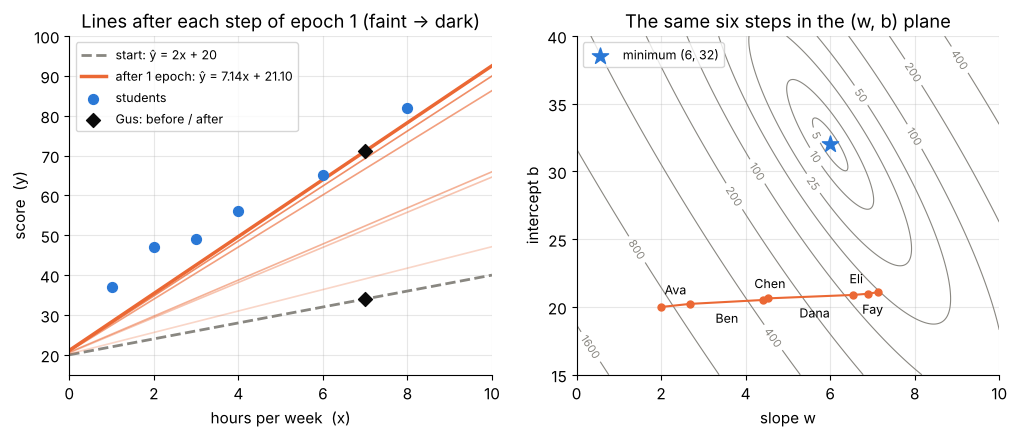

In [26]:
step_w = np.concatenate([[W0], epoch1["w new"].to_numpy()])   # parameters after 0, 1, ..., 6 steps
step_b = np.concatenate([[B0], epoch1["b new"].to_numpy()])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.plot(xs, predict(xs, W0, B0), color=MUTED, lw=2, ls="--", label="start: ŷ = 2x + 20")
for k in range(1, n):
    ax.plot(xs, predict(xs, step_w[k], step_b[k]), color=ORANGE, lw=1.2, alpha=0.15 + 0.12 * k)
ax.plot(xs, predict(xs, w1, b1), color=ORANGE, lw=2.5, label=f"after 1 epoch: ŷ = {w1:.2f}x + {b1:.2f}")
ax.scatter(x, y, s=50, color=BLUE, zorder=3, label="students")
ax.scatter([GUS_HOURS] * 2, [predict(GUS_HOURS, W0, B0), predict(GUS_HOURS, w1, b1)],
           marker="D", s=50, color=INK, zorder=4, label="Gus: before / after")
ax.set(xlabel="hours per week  (x)", ylabel="score  (y)", title="Lines after each step of epoch 1 (faint → dark)",
       xlim=(0, 10), ylim=(15, 100))
ax.legend(fontsize=9, loc="upper left")

ax = axes[1]
draw_contours(ax, wlim=(0, 10), blim=(15, 40), levels=[5, 10, 25, 50, 100, 200, 400, 800, 1600])
ax.plot(step_w, step_b, "o-", color=ORANGE, ms=5, lw=1.5)
for k in range(n):                      # label each step at its midpoint, alternating above/below
    ax.annotate(students["student"][k], ((step_w[k] + step_w[k + 1]) / 2, (step_b[k] + step_b[k + 1]) / 2),
                textcoords="offset points", xytext=(-8, 8 if k % 2 == 0 else -15), fontsize=9)
ax.scatter([6], [32], marker="*", s=150, color=BLUE, zorder=4, label="minimum (6, 32)")
ax.set_title("The same six steps in the (w, b) plane")
ax.legend(loc="upper left", fontsize=9)
plt.show()

After one pass over six students the training MSE dropped from 878.67 to 51.48 (94% lower),
and Gus's predicted score went from an absurd 34 to a plausible 71.09, between Ben's 65
(6 hours) and Dana's 82 (8 hours).

The right panel shows the six steps as a path in the parameter plane. Each step moves along its
own student's direction $(x_i, 1)$ (Section 4.3): Dana's step points almost straight along the
$w$ axis, while Chen's step, along her direction $(1, 1)$, is the shortest of all (about 0.12
in each parameter). Every student was under-predicted, so all six steps point up and to the
right and the path is nearly straight. It bends slightly at each step because every student
pulls in a slightly different direction. (Real zig-zagging across the valley appears later,
in Sections 6.2 and 7.3.)

The line is not finished, though. With $w = 7.14$ it is now **steeper** than the best line
($w = 6$) and with $b = 21.10$ it is far too **low** (best: $b = 32$). The steep walls of the
bowl have been descended, but the bottom of the narrow valley has not been reached.

### 5.7 Many epochs

Let us keep going. The function below is the same loop without the bookkeeping. It records the
parameters at the end of every epoch, and it accepts an optional rule for the visiting order,
which Section 6 will use.

In [27]:
def train_sgd(w, b, lr, epochs, order_fn=None, rng=None, xx=None, yy=None):
    """Per-sample SGD for `epochs` passes, returning an array of rows (w, b, MSE) after each epoch.

    order_fn(epoch, rng) -> sequence of sample indices for that epoch (default: table order).
    Row 0 holds the starting point, row k the parameters after k epochs.
    """
    xx = x if xx is None else xx
    yy = y if yy is None else yy
    history = [(w, b, mse(w, b, xx, yy))]
    for epoch in range(epochs):
        order = range(len(xx)) if order_fn is None else order_fn(epoch, rng)
        for i in order:
            e = w * xx[i] + b - yy[i]
            w, b = w - lr * 2 * xx[i] * e, b - lr * 2 * e
        history.append((w, b, mse(w, b, xx, yy)))
    return np.array(history)


hist = train_sgd(W0, B0, ETA, epochs=2000)
show_epochs = [0, 1, 2, 5, 10, 50, 100, 300, 1000, 2000]
progress = pd.DataFrame(hist[show_epochs], index=pd.Index(show_epochs, name="epoch"),
                        columns=["w", "b", "training MSE"])
progress["prediction for Gus"] = progress["w"] * GUS_HOURS + progress["b"]
display(progress.round(4))

,w,b,training MSE,prediction for Gus
epoch,,,,
0,2.0000,20.0000,878.6667,34.0000
1,7.1420,21.1002,51.4806,71.0944
2,7.9182,21.4118,33.3498,76.8393
5,7.9792,21.9221,30.8682,77.7767
10,7.8435,22.6774,27.0550,77.5817
50,7.0743,26.9384,11.1245,76.4587
100,6.6079,29.5226,6.0960,75.7777
300,6.2514,31.4975,4.6112,75.2572
1000,6.2371,31.5765,4.5943,75.2364


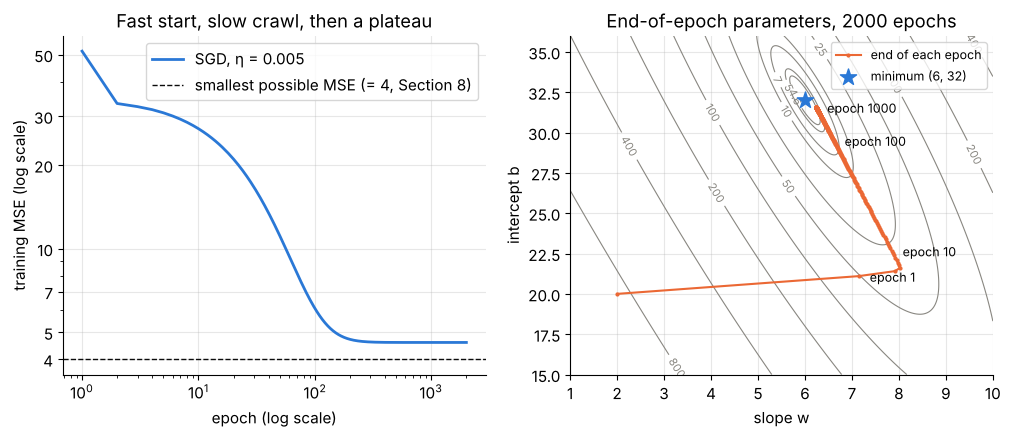

first epoch at which b exceeds 30: 117


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
epochs_axis = np.arange(1, len(hist))
ax.plot(epochs_axis, hist[1:, 2], color=BLUE, lw=2, label="SGD, η = 0.005")
ax.axhline(4.0, color=INK, lw=1, ls="--", label="smallest possible MSE (= 4, Section 8)")
ax.set(xscale="log", yscale="log", xlabel="epoch (log scale)", ylabel="training MSE (log scale)",
       title="Fast start, slow crawl, then a plateau")
ax.set_yticks([4, 5, 7, 10, 20, 30, 50])
ax.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())   # plain numbers instead of 4×10⁰
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.legend()

ax = axes[1]
draw_contours(ax, wlim=(1, 10), blim=(15, 36), levels=[4.6, 5, 7, 10, 25, 50, 100, 200, 400, 800])
ax.plot(hist[:, 0], hist[:, 1], color=ORANGE, lw=1.5, marker="o", ms=2, label="end of each epoch")
for ep in [1, 10, 100, 1000]:
    ax.annotate(f"epoch {ep}", (hist[ep, 0], hist[ep, 1]), textcoords="offset points", xytext=(8, -4), fontsize=9)
ax.scatter([6], [32], marker="*", s=150, color=BLUE, zorder=4, label="minimum (6, 32)")
ax.set_title("End-of-epoch parameters, 2000 epochs")
ax.legend(loc="upper right", fontsize=9)
plt.show()
print("first epoch at which b exceeds 30:", int(np.argmax(hist[:, 1] > 30)))

Training has three phases:

1. **Fast start.** The first epoch removes 94% of the loss, mostly by fixing the slope: the
   parameters slide down the steep walls of the valley.
2. **Slow crawl.** Then the parameters creep along the flat valley floor: $b$ needs 117 epochs
   to climb past 30 and about 300 epochs to reach 31.5, while $w$ drifts back from about 8 to 6.25.
   Hundreds of epochs for two parameters and six students is embarrassingly slow. Section 7
   explains the cause (the valley is long and thin) and fixes it.
3. **Plateau.** From roughly epoch 460 on, the end-of-epoch parameters change by less than
   $10^{-4}$ per epoch, and from about epoch 800 on they are frozen (to four decimals) at
   $w = 6.2371$, $b = 31.5765$, MSE $4.5943$, close to but **not** the true minimum
   $(6, 32)$ with MSE 4. Gus is predicted 75.24 points. Section 6 explains why constant-step
   SGD stalls slightly off the minimum, and how to fix that too.

> **Common pitfall.** "The loss stopped decreasing, so we found the minimum" is not a safe
> conclusion. A plateau can also mean the step size is too small to make progress in a flat
> direction, or (as here) that the algorithm is circling the minimum without reaching it. When
> you can, compare with a known answer (here the closed form of Section 8) or try a different
> learning rate.

### ✏️ Exercise 6: one full epoch

Implement `sgd_epoch(x, y, w, b, lr)`: visit the samples in the given order, apply one SGD step
per sample, and return `(w, b, losses)`, where `losses` is the list of per-sample losses
$\ell_i = (\hat y_i - y_i)^2$ computed **before** each update (the `ℓ = e²` column of the table).

In [29]:
# ✏️ Exercise 6: one epoch of per-sample SGD
def sgd_epoch(x, y, w, b, lr):
    """Return (w, b, losses) after one pass of per-sample SGD over (x, y) in the given order."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    w_, b_, losses = sgd_epoch(np.array([1.0, 2.0]), np.array([3.0, 5.0]), 0.0, 0.0, 0.1)
    assert np.allclose((w_, b_), (1.88, 1.24)), f"tiny example: expected (1.88, 1.24), got {(w_, b_)}"
    assert np.allclose(losses, [9.0, 10.24]), f"tiny example: expected losses [9, 10.24], got {losses}"
    w_, b_, losses = sgd_epoch(x, y, 2.0, 20.0, 0.005)
    assert np.allclose((w_, b_), (7.14203, 21.10022), atol=1e-4), f"students: expected about (7.1420, 21.1002), got {(w_, b_)}"
    assert len(losses) == 6 and np.isclose(losses[1], 819.6769), "the second loss should be Ben's 819.6769"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def sgd_epoch(x, y, w, b, lr):
    losses = []
    for xi, yi in zip(x, y):
        e = w * xi + b - yi
        losses.append(e ** 2)
        w, b = w - lr * 2 * xi * e, b - lr * 2 * e
    return w, b, losses
```
The tuple assignment on the last line evaluates both right-hand sides with the old `w` and `b`
before assigning, so no temporary variables are needed. Tiny example by hand: the first step
has $e = -3$, so $w = b = 0.6$. The second has $e = 1.8 - 5 = -3.2$, so
$w = 0.6 + 0.1 \cdot 12.8 = 1.88$ and $b = 0.6 + 0.1 \cdot 6.4 = 1.24$.
</details>

## 6. Per-sample SGD vs full-batch GD vs mini-batch

### 6.1 Three ways to spend an epoch

Per-sample SGD is one of three closely related algorithms. All of them follow the update rule
$\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf{g}$, and they differ only in which
gradient $\mathbf{g}$ they use:

| algorithm | gradient used in one update | updates per epoch | each update is... |
|---|---|---|---|
| full-batch gradient descent (GD) | $\nabla\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}\nabla\ell_i$ (all samples) | $1$ | exact but expensive |
| stochastic gradient descent (SGD) | $\nabla\ell_i$ (one sample) | $n$ | cheap but noisy |
| mini-batch gradient descent | $\frac{1}{B}\sum_{i \in \text{batch}}\nabla\ell_i$ ($B$ samples) | $\lceil n/B \rceil$ | in between |

Mini-batch with $B = 1$ is SGD and with $B = n$ is full-batch GD, so one function covers all
three. Why does a single student's gradient make sense at all? If the student is picked
uniformly at random, the *average* of the per-sample gradient is exactly the full gradient:

$$
\mathbb{E}_i\big[\nabla \ell_i(\boldsymbol\theta)\big] = \frac{1}{n}\sum_{i=1}^{n} \nabla\ell_i(\boldsymbol\theta) = \nabla\mathcal{L}(\boldsymbol\theta).
$$

So SGD moves in the right direction *on average*, but any single step contains an error (the
**gradient noise**). Averaging over a mini-batch of $B$ samples keeps the same average and
shrinks the noise (its variance falls roughly like $1/B$).

In [30]:
def train_minibatch(w, b, lr, epochs, batch_size, order_fn=None, lr_fn=None, rng=None):
    """Mini-batch gradient descent on the students.

    Returns (history, path): history[k] = (w, b, MSE) after k epochs, and path = (w, b) after every update.
    order_fn(epoch, rng) gives the visiting order, and lr_fn(epoch) gives the learning rate of that epoch.
    """
    history, path = [(w, b, mse(w, b))], [(w, b)]
    for epoch in range(epochs):
        order = np.arange(n) if order_fn is None else np.asarray(order_fn(epoch, rng))
        eta = lr if lr_fn is None else lr_fn(epoch)
        for start in range(0, n, batch_size):
            j = order[start:start + batch_size]          # indices of this batch
            e = w * x[j] + b - y[j]
            w, b = w - eta * np.mean(2 * x[j] * e), b - eta * np.mean(2 * e)
            path.append((w, b))
        history.append((w, b, mse(w, b)))
    return np.array(history), np.array(path)


# sanity check: batch_size=1 reproduces Section 5 exactly
h_check, _ = train_minibatch(W0, B0, ETA, 1, batch_size=1)
print("batch_size = 1, one epoch:", h_check[1, :2].round(4), "(Section 5 got", np.round([w1, b1], 4), ")")

batch_size = 1, one epoch: [ 7.142  21.1002] (Section 5 got [ 7.142  21.1002] )


### 6.2 A race: same start, same learning rate, same number of epochs

All four runs below start at the coach's guess, use $\eta = 0.005$ and see the data the same
number of times. Only the batch size differs.

training MSE after a given number of epochs (η = 0.005):


,SGD (B = 1),mini-batch B = 2,mini-batch B = 3,full-batch GD (B = 6)
epoch,,,,
1,51.481,206.232,335.354,542.672
10,27.055,30.767,31.907,38.678
30,16.646,23.749,26.801,30.575
100,6.096,10.901,15.276,22.645
300,4.611,4.484,5.579,10.774


same number of UPDATES (180): full-batch GD after 180 epochs has MSE 16.44. SGD after 30 epochs has MSE 16.65


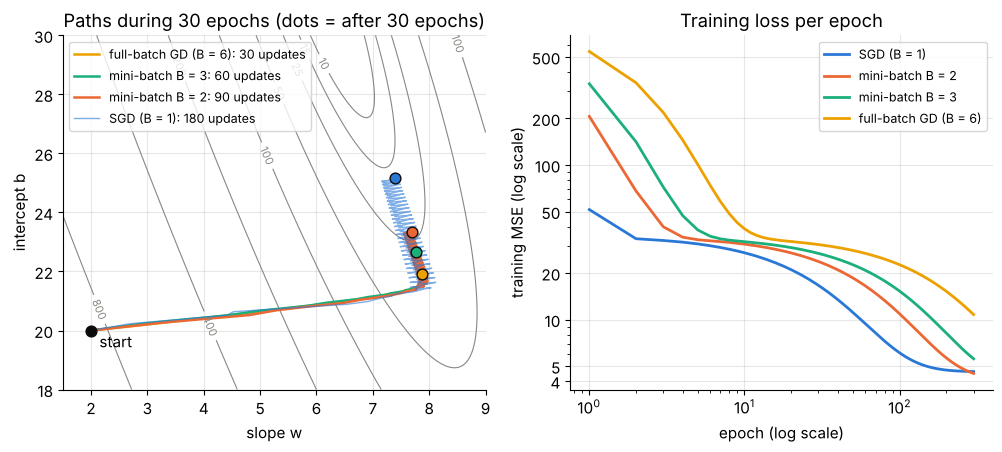

In [31]:
race = {}
for B in [1, 2, 3, 6]:
    h, p = train_minibatch(W0, B0, ETA, 300, batch_size=B)
    race[B] = (h, p)
labels = {1: "SGD (B = 1)", 2: "mini-batch B = 2", 3: "mini-batch B = 3", 6: "full-batch GD (B = 6)"}
table = pd.DataFrame({labels[B]: race[B][0][[1, 10, 30, 100, 300], 2] for B in race},
                     index=pd.Index([1, 10, 30, 100, 300], name="epoch"))
print("training MSE after a given number of epochs (η = 0.005):")
display(table.round(3))
print(f"same number of UPDATES (180): full-batch GD after 180 epochs has MSE {race[6][0][180, 2]:.2f}. "
      f"SGD after 30 epochs has MSE {race[1][0][30, 2]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
draw_contours(ax, wlim=(1.5, 9), blim=(18, 30), levels=[10, 15, 25, 50, 100, 200, 400, 800], labels=True)
for k, B in reversed(list(enumerate([1, 2, 3, 6]))):   # draw SGD first so the smoother paths stay visible
    p = race[B][1][: 30 * int(np.ceil(n / B)) + 1]      # the first 30 epochs
    ax.plot(p[:, 0], p[:, 1], "-", lw=1.0 if B == 1 else 1.8, alpha=0.6 if B == 1 else 1.0,
            color=PALETTE[k], label=f"{labels[B]}: {len(p) - 1} updates")
    ax.scatter(p[-1, 0], p[-1, 1], s=60, color=PALETTE[k], edgecolor=INK, zorder=4)
ax.scatter([W0], [B0], s=60, color=INK, zorder=4)
ax.annotate("start", (W0, B0), textcoords="offset points", xytext=(6, -12))
ax.set_title("Paths during 30 epochs (dots = after 30 epochs)")
ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
for k, B in enumerate([1, 2, 3, 6]):
    ax.plot(np.arange(1, 301), race[B][0][1:, 2], color=PALETTE[k], lw=2, label=labels[B])
ax.set(xscale="log", yscale="log", xlabel="epoch (log scale)", ylabel="training MSE (log scale)",
       title="Training loss per epoch")
ax.set_yticks([4, 5, 10, 20, 50, 100, 200, 500])
ax.yaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.legend(fontsize=9)
plt.show()

Per epoch, smaller batches win clearly: after 100 epochs SGD has reached MSE 6.10 while
full-batch GD is still at 22.65. The reason is simply the **number of updates**: in 30 epochs
SGD moves 180 times, full-batch GD only 30 times. Per update, the two are nearly equally good
on this problem: full-batch GD after 180 updates (180 epochs) reaches MSE 16.44, essentially
the same as SGD after its first 180 updates (16.65 after 30 epochs). The noisy gradients cost
SGD very little, and it gets six times as many of them for the same amount of computation.
(By epoch 300 SGD has reached its noisy plateau from Section 5.7, and the less noisy $B = 2$
run edges ahead of it: noise is the price of cheap steps.)

On real datasets with millions of samples the argument becomes overwhelming: full-batch GD must
read the whole dataset before it may take one step, while SGD has taken a million steps by then.
In practice everyone uses **mini-batches** of 32 to a few thousand samples: a GPU processes a
batch of 256 samples in about the time it needs for one, so a mini-batch step costs almost
nothing extra and averages away much of the noise.

> **Going deeper.** If you multiply the batch size by $k$, you make $k$ times fewer updates per
> epoch, and multiplying the learning rate by $k$ roughly compensates (the "linear scaling rule"),
> as long as the larger step stays below the stability limit of Section 7. The cell below checks
> it on our data.

In [32]:
for B, lr in [(1, 0.005), (2, 0.010), (3, 0.015), (6, 0.030)]:
    h, _ = train_minibatch(W0, B0, lr, 100, batch_size=B)
    print(f"B = {B}, η = {lr:.3f}:  MSE after 10 epochs = {h[10, 2]:6.3f},  after 100 epochs = {h[100, 2]:6.3f}")

B = 1, η = 0.005:  MSE after 10 epochs = 27.055,  after 100 epochs =  6.096
B = 2, η = 0.010:  MSE after 10 epochs = 27.515,  after 100 epochs =  6.204
B = 3, η = 0.015:  MSE after 10 epochs = 26.780,  after 100 epochs =  6.335
B = 6, η = 0.030:  MSE after 10 epochs = 26.786,  after 100 epochs =  5.455


With the learning rate scaled together with the batch size, all four runs make similar progress
per epoch (MSE between 5.5 and 6.4 after 100 epochs).

### 6.3 Why constant-step SGD never settles: gradient noise at the minimum

At the best line $(w, b) = (6, 32)$ the **full** gradient is zero, by definition of a minimum.
The **per-sample** gradients are not:

In [33]:
e_opt = predict(x, 6.0, 32.0) - y
at_min = students.copy()
at_min["e = ŷ − y"] = e_opt
at_min["∂ℓ/∂w"] = 2 * x * e_opt
at_min["∂ℓ/∂b"] = 2 * e_opt
at_min["SGD step Δw"] = -ETA * 2 * x * e_opt + 0.0     # "+ 0.0" turns -0.0 into 0.0 for display
at_min["SGD step Δb"] = -ETA * 2 * e_opt + 0.0
display(at_min.round(3))
print("sums of the per-sample gradients:", at_min["∂ℓ/∂w"].sum(), at_min["∂ℓ/∂b"].sum())

,student,hours,score,e = ŷ − y,∂ℓ/∂w,∂ℓ/∂b,SGD step Δw,SGD step Δb
0,Ava,3,49,1.0,6.0,2.0,-0.03,-0.01
1,Ben,6,65,3.0,36.0,6.0,-0.18,-0.03
2,Chen,1,37,1.0,2.0,2.0,-0.01,-0.01
3,Dana,8,82,-2.0,-32.0,-4.0,0.16,0.02
4,Eli,4,56,0.0,0.0,0.0,0.00,0.00
5,Fay,2,47,-3.0,-12.0,-6.0,0.06,0.03


sums of the per-sample gradients: 0.0 0.0


The six students' gradients cancel exactly (their sums are 0), yet each one on its own is
non-zero. Standing exactly at the minimum, an SGD step on Ben would still move the line by
$\Delta w = -0.18$: away from the minimum. With a constant learning rate, SGD therefore keeps
jiggling around the bottom forever. With the fixed table order the jiggle becomes a loop that
repeats every epoch, a **limit cycle** of six points, one per student, and this is why the
end-of-epoch parameters of Section 5.7 froze at $(6.2371, 31.5765)$.

### 6.4 Does the order of the students matter?

Let us run 3000 epochs with four visiting orders: the table order, sorted by hours (ascending
and descending), and a fresh random shuffle every epoch.

In [34]:
shuffle_rng = np.random.default_rng(SEED)
orders = {
    "table order": lambda ep, r: np.arange(n),
    "ascending hours": lambda ep, r: np.argsort(x),
    "descending hours": lambda ep, r: np.argsort(-x),
    "reshuffled every epoch": lambda ep, r: r.permutation(n),
}
order_runs, rows = {}, []
for name, fn in orders.items():
    h, p = train_minibatch(W0, B0, ETA, 3000, batch_size=1, order_fn=fn, rng=shuffle_rng)
    order_runs[name] = p
    last = p[-600:]                      # every update of the last 100 epochs
    rows.append({"order": name, "w at end": h[-1, 0], "b at end": h[-1, 1], "MSE at end": h[-1, 2],
                 "mean w (last 100 epochs)": last[:, 0].mean(), "mean b (last 100 epochs)": last[:, 1].mean(),
                 "mean MSE (last 100 epochs)": np.mean([mse(*q) for q in last])})
display(pd.DataFrame(rows).set_index("order").round(4))

,w at end,b at end,MSE at end,mean w (last 100 epochs),mean b (last 100 epochs),mean MSE (last 100 epochs)
order,,,,,,
table order,6.2371,31.5765,4.5943,6.1232,31.5468,4.3632
ascending hours,6.2066,31.4085,4.2970,6.1842,31.4113,4.3946
descending hours,5.9214,32.1726,4.0551,5.9370,32.1709,4.1901
reshuffled every epoch,6.1396,31.8810,4.3037,6.0313,31.8847,4.3429


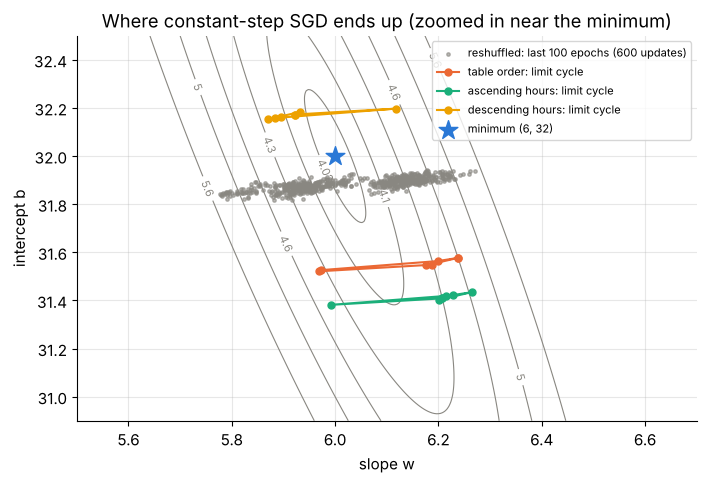

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
draw_contours(ax, wlim=(5.5, 6.7), blim=(30.9, 32.5), levels=[4.02, 4.1, 4.3, 4.6, 5.0, 5.6], labels=True)
cloud = order_runs["reshuffled every epoch"][-600:]
ax.scatter(cloud[:, 0], cloud[:, 1], s=6, color=MUTED, alpha=0.6, label="reshuffled: last 100 epochs (600 updates)")
for k, name in enumerate(["table order", "ascending hours", "descending hours"]):
    loop = order_runs[name][-7:]         # the last 6 updates, closed into a loop
    ax.plot(loop[:, 0], loop[:, 1], "-o", ms=5, lw=1.5, color=PALETTE[k + 1], label=f"{name}: limit cycle")
ax.scatter([6], [32], marker="*", s=200, color=BLUE, zorder=5, label="minimum (6, 32)")
ax.set_title("Where constant-step SGD ends up (zoomed in near the minimum)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

Each fixed order settles into its *own* loop with its *own* systematic offset from the minimum
(ascending hours ends near $(6.21, 31.41)$, descending near $(5.92, 32.17)$). Which order happens
to be best is an accident of the data, and none of them reaches $(6, 32)$. With reshuffling there
is no fixed loop: the parameters wander randomly around the bottom (gray cloud), and the
center of the cloud, $(6.03, 31.88)$, is closer to the minimum than the center of any
fixed-order loop. Shuffling turns a systematic error into random noise that averages out.
It does not promise a lower loss at every moment (on this tiny dataset the descending order
happens to have a slightly lower average MSE). What it removes is the hidden, order-dependent bias.

> **Common pitfall.** Real datasets are often stored sorted: by date, by customer, by class
> label. Running SGD in storage order then makes the end of every epoch over-represent one
> stretch of the data. Shuffle every epoch (in PyTorch: `DataLoader(..., shuffle=True)`).

### 6.5 Making SGD converge: shrink the learning rate

The noise of an SGD step is proportional to $\eta$, so the cure is to let $\eta$ shrink over
time. A classic schedule is

$$
\eta_t = \frac{\eta_0}{1 + t/\tau},
$$

where $t$ is the epoch number and $\tau$ sets how quickly the steps shrink (here $\tau = 200$
epochs). Robbins and Monro showed in 1951 that SGD converges to the minimum (of a convex loss
such as ours) when the step sizes satisfy
$\sum_t \eta_t = \infty$ (the steps add up to an unlimited distance, so the minimum can be
reached from anywhere) and $\sum_t \eta_t^2 < \infty$ (the accumulated noise stays bounded).
Our schedule decays like $1/t$ and satisfies both.

constant η = 0.005               distance to (6, 32) after 300 / 1000 / 3000 epochs: 0.562 / 0.485 / 0.485
decaying η = 0.005 / (1 + t/200) distance to (6, 32) after 300 / 1000 / 3000 epochs: 0.810 / 0.134 / 0.037


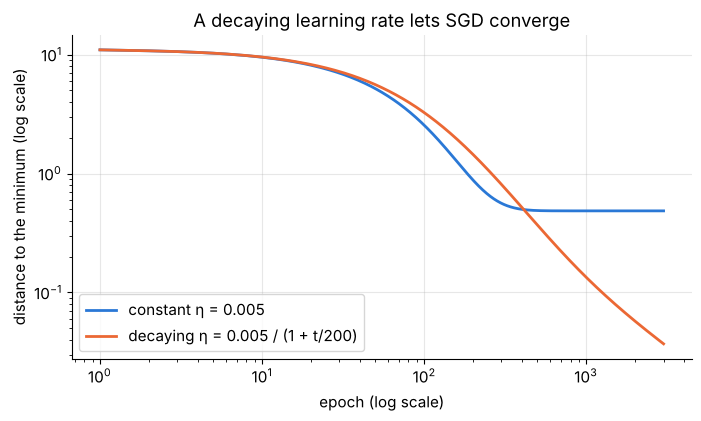

In [36]:
TAU = 200
runs = {
    "constant η = 0.005": train_minibatch(W0, B0, ETA, 3000, batch_size=1)[0],
    f"decaying η = 0.005 / (1 + t/{TAU})": train_minibatch(W0, B0, ETA, 3000, batch_size=1,
                                                            lr_fn=lambda ep: ETA / (1 + ep / TAU))[0],
}
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (name, h) in enumerate(runs.items()):
    dist = np.hypot(h[:, 0] - 6, h[:, 1] - 32)
    ax.plot(np.arange(1, len(h)), dist[1:], color=PALETTE[k], lw=2, label=name)
    print(f"{name:<32} distance to (6, 32) after 300 / 1000 / 3000 epochs: "
          f"{dist[300]:.3f} / {dist[1000]:.3f} / {dist[3000]:.3f}")
ax.set(xscale="log", yscale="log", xlabel="epoch (log scale)", ylabel="distance to the minimum (log scale)",
       title="A decaying learning rate lets SGD converge")
ax.legend()
plt.show()

With a constant step the distance to the minimum stalls at 0.485. The decaying schedule starts
a little slower (smaller steps also mean slower travel) but keeps improving: 0.134 after 1000
epochs and 0.037 after 3000. Deep-learning practice uses the same idea with other shapes of
schedule (step decay, cosine decay), often combined with averaging the most recent iterates.

**Quick check.** You train with full-batch gradient descent and a learning rate that converges.
Do you need a decaying learning rate to land exactly on the minimum?

<details>
<summary>Answer</summary>

No. The full gradient is exactly zero at the minimum, so the steps $\eta\nabla\mathcal{L}$
shrink to zero automatically as you approach it, just as in the one-dimensional example of
Section 4.2. The decay is needed only for stochastic gradients, whose noise does not vanish at
the minimum.
</details>

### ✏️ Exercise 7: one epoch of mini-batch gradient descent

Implement `minibatch_epoch(x, y, w, b, lr, batch_size)`. Split the samples, **in the given
order**, into consecutive batches of `batch_size` (the last batch may be smaller). For each
batch compute the *average* gradient over the batch and take one step. Return the final
`(w, b)`.

In [37]:
# ✏️ Exercise 7: mini-batch gradient descent
def minibatch_epoch(x, y, w, b, lr, batch_size):
    """Return (w, b) after one epoch of mini-batch gradient descent with consecutive batches."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.allclose(minibatch_epoch(x, y, 2.0, 20.0, 0.005, 1), (7.14203, 21.10022), atol=1e-4), \
        "batch_size=1 must reproduce the SGD epoch of Section 5"
    assert np.allclose(minibatch_epoch(x, y, 2.0, 20.0, 0.005, 6), (3.34667, 20.28), atol=1e-4), \
        "batch_size=6 must be one full-batch step: gradient (-269.33, -56)"
    assert np.allclose(minibatch_epoch(x, y, 2.0, 20.0, 0.005, 2), (5.29751, 20.68780), atol=1e-4), \
        "batch_size=2: three steps on (Ava, Ben), (Chen, Dana), (Eli, Fay)"
    assert np.allclose(minibatch_epoch(x, y, 2.0, 20.0, 0.005, 4), (4.24372, 20.49582), atol=1e-4), \
        "batch_size=4: a batch of 4, then the remaining 2 samples"
    reference = train_minibatch(2.0, 20.0, 0.005, 1, batch_size=3)[0][1, :2]
    assert np.allclose(minibatch_epoch(x, y, 2.0, 20.0, 0.005, 3), reference), \
        "batch_size=3 disagrees with train_minibatch from Section 6.1"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def minibatch_epoch(x, y, w, b, lr, batch_size):
    for start in range(0, len(x), batch_size):
        xb, yb = x[start:start + batch_size], y[start:start + batch_size]
        e = w * xb + b - yb
        w, b = w - lr * np.mean(2 * xb * e), b - lr * np.mean(2 * e)
    return w, b
```
Slicing past the end of an array is allowed in NumPy and simply returns the remaining
elements, so the smaller last batch needs no special case. Using the *mean* (not the sum) of
the batch gradients keeps the step size comparable across batch sizes.
</details>

## 7. Choosing the learning rate (and why centering helps)

Sections 5 and 6 left two puzzles: why did gradient descent need hundreds of epochs for a
two-parameter problem, and how large may the learning rate be? Both have the same answer:
**curvature**.

### 7.1 One dimension: everything depends on $1 - \eta a$

Go back to the parabola of Section 4.2, $\mathcal{L}(b) = (b - 32)^2 + 4$ (slope frozen at
$w = 6$). Its gradient-descent iterates satisfy $b_{t+1} - 32 = (1 - 2\eta)(b_t - 32)$: each
step multiplies the distance to the minimum by $1 - 2\eta$. More generally, for any parabola
$\mathcal{L}(b) = \frac{a}{2}(b - b^*)^2 + \text{const}$ with **curvature** (second derivative)
$a > 0$, the factor is $1 - \eta a$. Here $a = 2$, and the size of the factor decides everything:

| learning rate | factor $1 - 2\eta$ | what happens |
|---|---|---|
| $0 < \eta < 0.5$ | between 0 and 1 | creeps toward the minimum from one side |
| $\eta = 0.5$ (that is, $1/a$) | $0$ | lands exactly on the minimum in one step |
| $0.5 < \eta < 1$ | between $-1$ and 0 | overshoots and oscillates, but converges |
| $\eta = 1$ (that is, $2/a$) | $-1$ | bounces forever between 20 and 44 |
| $\eta > 1$ | below $-1$ | every bounce is bigger: **diverges** |

So gradient descent on a parabola is stable exactly when $0 < \eta < 2/a$, and the ideal
step is $\eta = 1/a$. A strongly curved loss (large $a$) demands small steps.

η = 0.1 : b_0..b_6 = [20.   22.4  24.32 25.86 27.08 28.07 28.85]
η = 0.5 : b_0..b_6 = [20. 32. 32. 32. 32. 32. 32.]
η = 0.9 : b_0..b_6 = [20.   41.6  24.32 38.14 27.08 35.93 28.85]
η = 1.05: b_0..b_6 = [20.   45.2  17.48 47.97 14.43 51.33 10.74]


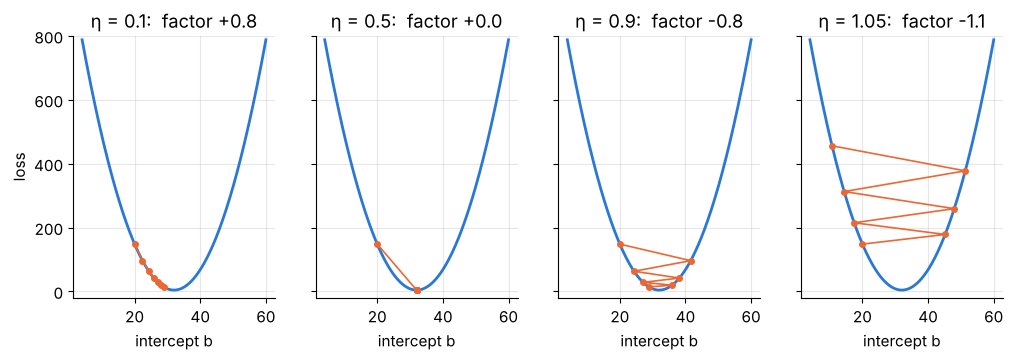

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
b_wide = np.linspace(4, 60, 300)
for ax, eta in zip(axes, [0.1, 0.5, 0.9, 1.05]):
    b_t, seq = 20.0, [20.0]
    for _ in range(6):
        b_t = b_t - eta * 2 * (b_t - 32)
        seq.append(b_t)
    seq = np.array(seq)
    ax.plot(b_wide, (b_wide - 32) ** 2 + 4, color=BLUE, lw=2)
    ax.plot(seq, (seq - 32) ** 2 + 4, "o-", color=ORANGE, ms=4, lw=1.2)
    ax.set(title=f"η = {eta}:  factor {1 - 2 * eta:+.1f}", xlabel="intercept b", ylim=(-20, 800))
    print(f"η = {eta:<4}: b_0..b_6 = {np.round(seq, 2)}")
axes[0].set_ylabel("loss")
plt.show()

### 7.2 Two dimensions: one curvature per direction

With two parameters the curvature depends on the direction you move in. All second derivatives
together form the **Hessian matrix**. For our loss (Section 3.2) it is constant:

$$
H = \begin{pmatrix} \dfrac{\partial^2\mathcal{L}}{\partial w^2} & \dfrac{\partial^2\mathcal{L}}{\partial w\,\partial b} \\[2mm]
                    \dfrac{\partial^2\mathcal{L}}{\partial b\,\partial w} & \dfrac{\partial^2\mathcal{L}}{\partial b^2} \end{pmatrix}
  = 2\begin{pmatrix} \overline{x^2} & \bar x \\ \bar x & 1 \end{pmatrix}
  = \frac{2}{n} X^\top X \in \mathbb{R}^{2 \times 2}.
$$

Because $\mathcal{L}$ is exactly quadratic, its gradient is exactly linear: from Section 4.4,
$\nabla\mathcal{L}(\boldsymbol\theta) = \frac{2}{n}X^\top X\boldsymbol\theta - \frac{2}{n}X^\top\mathbf{y} = H\boldsymbol\theta - \frac{2}{n}X^\top\mathbf{y}$,
and since the gradient vanishes at the minimum $\boldsymbol\theta^*$, we get
$\frac{2}{n}X^\top\mathbf{y} = H\boldsymbol\theta^*$ and therefore

$$
\nabla\mathcal{L}(\boldsymbol\theta) = H(\boldsymbol\theta - \boldsymbol\theta^*),
\qquad
\boldsymbol\theta_{t+1} - \boldsymbol\theta^* = (I - \eta H)(\boldsymbol\theta_t - \boldsymbol\theta^*).
$$

$H$ is symmetric, so it has two perpendicular eigenvectors $\mathbf{q}_1, \mathbf{q}_2$ (the
axes of the elliptical contours) with eigenvalues $\lambda_{\min} \le \lambda_{\max}$ (the
curvatures along those axes). Measured along $\mathbf{q}_k$, the distance to the minimum is
multiplied by $1 - \eta\lambda_k$ at every step: the 2-D problem splits into two independent
copies of Section 7.1. Consequences:

* **Stability:** both factors must lie in $(-1, 1)$, so $0 < \eta < 2/\lambda_{\max}$. The
  *steepest* direction sets the speed limit.
* **Speed:** the *flattest* direction sets the pace. With the best choice
  $\eta^* = 2/(\lambda_{\min} + \lambda_{\max})$, both factors have the same size,
  $\frac{\kappa - 1}{\kappa + 1}$, where $\kappa = \lambda_{\max}/\lambda_{\min}$ is the
  **condition number**. When $\kappa$ is large, even the best learning rate is slow.

In [39]:
H = 2 * np.array([[np.mean(x ** 2), x.mean()], [x.mean(), 1.0]])
lam, Q = np.linalg.eigh(H)                    # eigenvalues in ascending order, eigenvectors in columns
kappa = lam[1] / lam[0]
print("Hessian H =\n", H.round(4))
print(f"eigenvalues: λ_min = {lam[0]:.4f}, λ_max = {lam[1]:.4f}.  Condition number κ = {kappa:.2f}")
print(f"steep direction q_max = {Q[:, 1].round(3)},  flat direction q_min = {Q[:, 0].round(3)}")
print(f"largest stable learning rate 2/λ_max = {2 / lam[1]:.5f}")
print(f"best learning rate η* = 2/(λ_min + λ_max) = {2 / lam.sum():.5f},  "
      f"error factor per step (κ−1)/(κ+1) = {(kappa - 1) / (kappa + 1):.4f}")

Hessian H =
 [[43.3333  8.    ]
 [ 8.      2.    ]]
eigenvalues: λ_min = 0.5056, λ_max = 44.8277.  Condition number κ = 88.66
steep direction q_max = [-0.983 -0.184],  flat direction q_min = [ 0.184 -0.983]
largest stable learning rate 2/λ_max = 0.04462
best learning rate η* = 2/(λ_min + λ_max) = 0.04412,  error factor per step (κ−1)/(κ+1) = 0.9777


The steep direction $\mathbf{q}_{\max} \approx \pm(0.98, 0.18)$ is mostly "change the slope":
a small change in $w$ moves every prediction by $x_i\,\Delta w$, and with $x$ up to 8 the loss
shoots up (curvature 44.8). The flat direction $\mathbf{q}_{\min} \approx \pm(-0.18, 0.98)$ is
mostly "raise $b$ while lowering $w$ a little", the valley floor of Section 3.3 (curvature
0.51). With $\kappa \approx 89$, even the best learning rate removes only about 2% of the
remaining error in the flat direction per step. That is the slow crawl we saw in Section 5.

### 7.3 A learning-rate experiment

Let us run full-batch gradient descent from the coach's guess with four learning rates: tiny,
moderate, close to the best, and just **above** the stability limit $2/\lambda_{\max} \approx 0.0446$.

In [40]:
def gd_path(w, b, lr, steps, feature=None):
    """Full-batch gradient descent on the MSE of y ≈ w*feature + b, returning all iterates, shape (steps+1, 2)."""
    f = x if feature is None else feature
    path = [(w, b)]
    for _ in range(steps):
        e = w * f + b - y
        w, b = w - lr * 2 * np.mean(e * f), b - lr * 2 * np.mean(e)
        path.append((w, b))
    return np.array(path)


lr_runs = {}
for lr in [0.002, 0.02, 0.044, 0.046]:
    with np.errstate(over="ignore", invalid="ignore"):   # the divergent run overflows on purpose
        p = gd_path(W0, B0, lr, 300)
        losses = np.mean((p[:, :1] * x + p[:, 1:] - y) ** 2, axis=1)
    lr_runs[lr] = (p, losses)
    f_min, f_max = 1 - lr * lam
    print(f"η = {lr:<6}: factors (flat, steep) = ({f_min:+.3f}, {f_max:+.3f}).  MSE after 300 steps = {losses[300]:.4g}")

η = 0.002 : factors (flat, steep) = (+0.999, +0.910).  MSE after 300 steps = 20.86
η = 0.02  : factors (flat, steep) = (+0.990, +0.103).  MSE after 300 steps = 4.069
η = 0.044 : factors (flat, steep) = (+0.978, -0.972).  MSE after 300 steps = 4
η = 0.046 : factors (flat, steep) = (+0.977, -1.062).  MSE after 300 steps = 4.16e+18


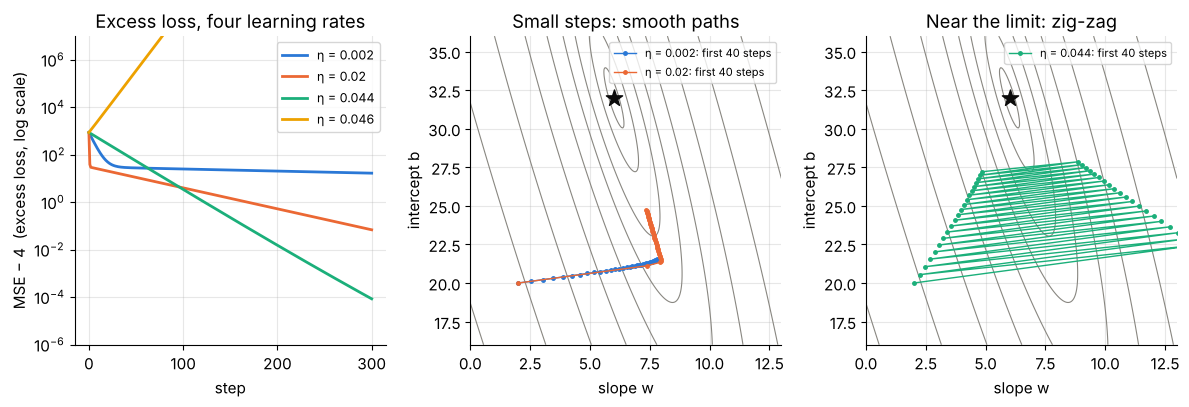

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
ax = axes[0]
for k, (lr, (p, losses)) in enumerate(lr_runs.items()):
    ax.plot(losses - 4.0, color=PALETTE[k], lw=2, label=f"η = {lr}")
ax.set(yscale="log", ylim=(1e-6, 1e7), xlabel="step", ylabel="MSE − 4  (excess loss, log scale)",
       title="Excess loss, four learning rates")
ax.legend(fontsize=9)

for ax, group, title in [(axes[1], [0.002, 0.02], "Small steps: smooth paths"),
                         (axes[2], [0.044], "Near the limit: zig-zag")]:
    draw_contours(ax, wlim=(0, 13), blim=(16, 36), levels=[5, 10, 25, 50, 100, 200, 400, 800, 1600], labels=False)
    for lr in group:
        p = lr_runs[lr][0][:41]
        k = list(lr_runs).index(lr)
        ax.plot(p[:, 0], p[:, 1], "-o", ms=2.5, lw=1, color=PALETTE[k], label=f"η = {lr}: first 40 steps")
    ax.scatter([6], [32], marker="*", s=150, color=INK, zorder=4)
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

* **$\eta = 0.002$, too small.** The steep-direction factor is $0.910$, so the first few steps go
  well, but the flat-direction factor $0.999$ means almost no movement along the valley: after
  300 steps the MSE is still 20.86.
* **$\eta = 0.02$, good.** Smooth progress, MSE 4.069 after 300 steps.
* **$\eta = 0.044$, near the best.** The steep-direction factor is $-0.972$: the path zig-zags
  across the valley (right panel), but the flat direction moves as fast as it can, and the
  excess loss falls below $10^{-4}$.
* **$\eta = 0.046$, too large.** Only 3% above the limit, yet the steep-direction factor is
  $-1.062$: every step overshoots a bit more than the last, and after 300 steps the MSE is
  about $4 \times 10^{18}$. In practice this shows up as a loss that suddenly explodes to
  `inf` or `nan`.

> **Key idea.** The largest stable learning rate is set by the **largest** curvature, and the
> speed of convergence is set by the **smallest** curvature. Their ratio, the condition number,
> measures how hard the problem is for gradient descent.

> **Olympiad tip.** For simple linear regression with MSE you can compute everything by hand:
> $\lambda_{\min} + \lambda_{\max} = \operatorname{tr} H = 2(\overline{x^2} + 1)$ and
> $\lambda_{\min}\lambda_{\max} = \det H = 4\operatorname{Var}(x)$. So the best learning rate is
> simply $\eta^* = 1/(\overline{x^2} + 1)$ (here $1/22.67 \approx 0.0441$).

### 7.4 Centering the feature removes the tilt

The valley is tilted because of the cross term $2\bar x\,wb$ in the loss: $w$ and $b$ are
entangled. Changing $w$ rotates the line about the point $(0, b)$, which is far to the left of
the data, so it also shifts the predictions of *all* students up or down, and $b$ must
compensate. The cure is to measure hours relative to the average student:

$$
\hat y = w\,(x - \bar x) + c, \qquad \text{where } c = b + w\bar x .
$$

This is the **same family of lines** (for any $(w, c)$ you can recover $b = c - w\bar x$), so
the best line does not change, and only the coordinates we use to describe it do. Now $w$ rotates
the line about the center of the data and $c$ is the predicted score of an average student.
The new feature $\tilde x = x - \bar x$ has mean zero, so the cross term vanishes and

$$
H_{\text{centered}} = 2\begin{pmatrix} \operatorname{Var}(x) & 0 \\ 0 & 1 \end{pmatrix}
= \begin{pmatrix} 11.33 & 0 \\ 0 & 2 \end{pmatrix}.
$$

The contours become **axis-aligned** ellipses, $\kappa$ drops from 88.7 to 5.67, and the best
learning rate $2/(11.33 + 2) = 0.15$ shrinks the error by a factor $0.7$ per step instead of
$0.978$.

### 7.5 Standardizing makes the bowl round

Go one step further and also divide by the standard deviation
$s_x = \sqrt{\operatorname{Var}(x)} \approx 2.38$:

$$
z = \frac{x - \bar x}{s_x}, \qquad \hat y = w_z\, z + c, \qquad w = \frac{w_z}{s_x}, \quad b = c - w\,\bar x .
$$

Now $\overline{z^2} = 1$ and $\bar z = 0$, so $H = 2I$: both curvatures equal 2, $\kappa = 1$,
the contours are **circles**, and the gradient points straight at the minimum from everywhere.
With $\eta = 1/2$ gradient descent lands on the minimum in **one** step.

The cell below runs gradient descent at the best learning rate of each parameterization,
starting from the same line (the coach's $\hat y = 2x + 20$, expressed in each coordinate
system), and measures progress by the excess loss $\mathcal{L} - 4$, which does not depend on
the coordinates.

In [42]:
x_bar, s_x = x.mean(), x.std()
setups = {   # name: (feature, starting (slope, intercept) of the line y = 2x + 20 in these coordinates)
    "raw x": (x, (W0, B0)),
    "centered x − x̄": (x - x_bar, (W0, B0 + W0 * x_bar)),
    "standardized z": ((x - x_bar) / s_x, (W0 * s_x, B0 + W0 * x_bar)),
}
results = {}
for name, (f, start) in setups.items():
    Hf = 2 * np.array([[np.mean(f ** 2), f.mean()], [f.mean(), 1.0]])
    lam_f = np.linalg.eigvalsh(Hf)
    eta_best = 2 / lam_f.sum()
    p = gd_path(*start, eta_best, 600, feature=f)
    excess = np.mean((p[:, :1] * f + p[:, 1:] - y) ** 2, axis=1) - 4.0
    results[name] = (f, p, excess)
    steps_needed = int(np.argmax(excess < 1e-6))
    print(f"{name:<16} κ = {lam_f[1] / lam_f[0]:6.2f}   η* = {eta_best:.4f}   steps until excess loss < 1e-6: {steps_needed}")
p_std = results["standardized z"][1]
print(f"standardized, after one step: w_z = {p_std[1, 0]:.4f}, c = {p_std[1, 1]:.4f}  ->  "
      f"w = {p_std[1, 0] / s_x:.4f}, b = {p_std[1, 1] - p_std[1, 0] / s_x * x_bar:.4f}")

raw x            κ =  88.66   η* = 0.0441   steps until excess loss < 1e-6: 457
centered x − x̄  κ =   5.67   η* = 0.1500   steps until excess loss < 1e-6: 29
standardized z   κ =   1.00   η* = 0.5000   steps until excess loss < 1e-6: 1
standardized, after one step: w_z = 14.2829, c = 56.0000  ->  w = 6.0000, b = 32.0000


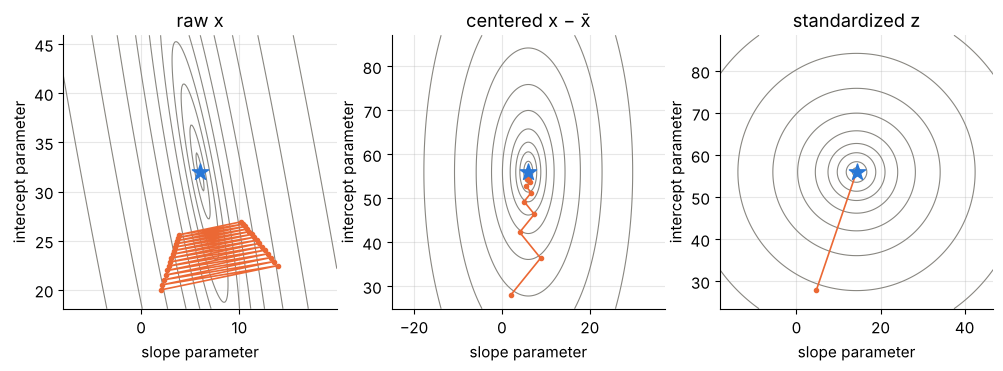

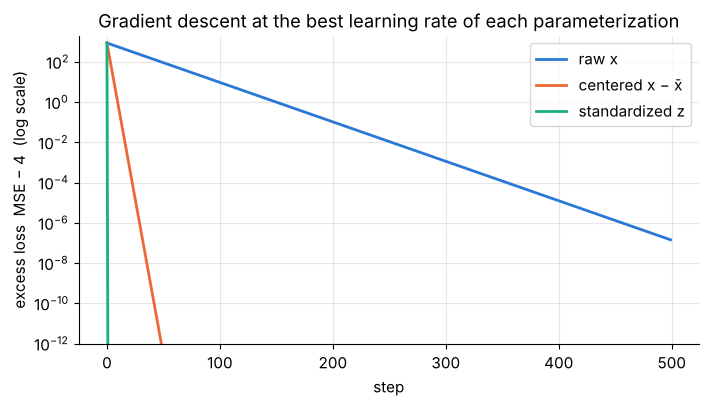

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, (name, (f, p, excess)) in zip(axes, results.items()):
    center = p[-1]                                   # (essentially) the minimum in these coordinates
    R = 1.1 * np.hypot(*(p[0] - center))             # window that contains the starting point
    W_, C_ = np.meshgrid(np.linspace(center[0] - R, center[0] + R, 241), np.linspace(center[1] - R, center[1] + R, 241))
    Z = np.mean((W_[..., None] * f + C_[..., None] - y) ** 2, axis=-1)
    ax.contour(W_, C_, Z, levels=[5, 10, 25, 50, 100, 200, 400, 800, 1600, 3200], colors=MUTED, linewidths=0.8)
    ax.plot(p[:30, 0], p[:30, 1], "-o", ms=3, lw=1.2, color=ORANGE)
    ax.scatter(*center, marker="*", s=150, color=BLUE, zorder=4)
    ax.set_aspect("equal")
    ax.set(xlim=(center[0] - R, center[0] + R), ylim=(center[1] - R, center[1] + R),
           title=name, xlabel="slope parameter", ylabel="intercept parameter")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for k, (name, (f, p, excess)) in enumerate(results.items()):
    ax.plot(np.maximum(excess[:500], 1e-16), color=PALETTE[k], lw=2, label=name)
ax.set(yscale="log", ylim=(1e-12, 2e3), xlabel="step", ylabel="excess loss  MSE − 4  (log scale)",
       title="Gradient descent at the best learning rate of each parameterization")
ax.legend()
plt.show()

Plotted with equal scales on both axes (so that circles look like circles), the three
landscapes tell the whole story. Raw: a long, thin, tilted valley. At its best learning rate,
gradient descent bounces back and forth across the valley (factor $-0.978$ in the steep
direction) while it inches along it (factor $0.978$), and it needs 457 steps to get the excess
loss below $10^{-6}$. Centered: an axis-aligned ellipse, 29 steps.
Standardized: a round bowl, **1 step**, after which $w = 6$ and $b = 32$ exactly. The best
line is the same in all three, and only the landscape that gradient descent has to walk through
changed.

> **Key idea.** Feature scaling is not cosmetic. Centering removes the coupling between slope
> and intercept. Dividing by the standard deviation equalizes the curvatures. Together they make
> gradient descent faster and let it use a larger, safer learning rate. This is why later
> notebooks standardize features before training.

> **Common pitfall.** Store $\bar x$ and $s_x$ and apply *the same* transformation to every new
> input at prediction time (Gus: $z = (7 - 4)/2.38$). With a train/test split, compute them
> from the training data only, then reuse them on the test data.

**Practical recipe for picking a learning rate** when you cannot compute the Hessian: try
values on a logarithmic grid ($0.001, 0.003, 0.01, 0.03, 0.1, \dots$), watch the training loss
for a few hundred steps, and keep the largest value whose loss decreases steadily. A loss that
jumps to `inf`/`nan` means "too large", and a loss that decreases smoothly but painfully slowly
means "try larger" (or rescale the features).

### ✏️ Exercise 8: the largest stable learning rate

Write `max_stable_lr(x)` that returns the largest learning rate for which **full-batch**
gradient descent on the MSE of $\hat y = wx + b$ is stable, namely $2/\lambda_{\max}$ where
$\lambda_{\max}$ is the largest eigenvalue of $H = 2\begin{pmatrix}\overline{x^2} & \bar x\\ \bar x & 1\end{pmatrix}$.
(Use `np.linalg.eigvalsh`, or the trace/determinant trick from the Olympiad tip.)

In [44]:
# ✏️ Exercise 8: maximum stable learning rate
def max_stable_lr(x):
    """Return 2 / (largest eigenvalue of the Hessian of the MSE of y = w*x + b)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(max_stable_lr(x), 0.0446153, atol=1e-6), f"students: expected about 0.044615, got {max_stable_lr(x)}"
    assert np.isclose(max_stable_lr(x - 4.0), 2 / 11.3333333, atol=1e-6), "centered hours: λ_max = 2·Var(x) = 11.33"
    assert np.isclose(max_stable_lr((x - 4.0) / x.std()), 1.0), "standardized hours: H = 2I, so the limit is 1"
    assert np.isclose(max_stable_lr(np.array([100.0, 200.0, 300.0])), 2.14282e-05, rtol=1e-4), \
        "large raw feature values must give a tiny learning-rate limit"
    lr_ = 0.99 * max_stable_lr(x)          # behavior check: just below the limit, GD must converge
    w_, b_ = 0.0, 0.0
    with np.errstate(all="ignore"):        # a wrong (too large) limit would overflow, so let the assert report it
        for _ in range(3000):
            e = w_ * x + b_ - y
            w_, b_ = w_ - lr_ * 2 * np.mean(e * x), b_ - lr_ * 2 * np.mean(e)
    assert np.allclose((w_, b_), (6, 32), atol=1e-3), "GD at 0.99 × your limit should converge"


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def max_stable_lr(x):
    x = np.asarray(x, dtype=float)
    H = 2 * np.array([[np.mean(x ** 2), np.mean(x)], [np.mean(x), 1.0]])
    return 2 / np.linalg.eigvalsh(H).max()
```
Without eigenvalue routines: $\lambda_{\max} = \frac{T + \sqrt{T^2 - 4D}}{2}$ with
$T = 2(\overline{x^2} + 1)$ and $D = 4\operatorname{Var}(x)$. For the raw feature
$x = (100, 200, 300)$ the limit is about $2 \times 10^{-5}$, a vivid reminder of why
features are scaled.
</details>

## 8. The exact answer: least squares in closed form

For this particular model and loss we do not need to walk downhill at all. At the bottom of a
smooth bowl the gradient is zero, and here that condition can be solved exactly with algebra.

### 8.1 Setting the gradient to zero: the normal equations

The two components of the gradient (Section 4.4) must vanish:

$$
\frac{\partial\mathcal{L}}{\partial b} = \frac{2}{n}\sum_{i=1}^{n} (w x_i + b - y_i) = 0
\quad\Longleftrightarrow\quad w\bar x + b = \bar y
\quad\Longleftrightarrow\quad b = \bar y - w\bar x, \tag{1}
$$

$$
\frac{\partial\mathcal{L}}{\partial w} = \frac{2}{n}\sum_{i=1}^{n} x_i\,(w x_i + b - y_i) = 0. \tag{2}
$$

These are the **normal equations**. Substitute (1) into (2). Since
$w x_i + b - y_i = w(x_i - \bar x) - (y_i - \bar y)$, equation (2) becomes

$$
w \sum_i x_i (x_i - \bar x) = \sum_i x_i (y_i - \bar y).
$$

Now a small trick: deviations from the mean always sum to zero,
$\sum_i (x_i - \bar x) = 0$ and $\sum_i (y_i - \bar y) = 0$. So we may subtract
$\bar x \sum_i (x_i - \bar x) = 0$ from the left sum and $\bar x \sum_i (y_i - \bar y) = 0$ from
the right sum without changing them, which replaces each $x_i$ by $x_i - \bar x$:

$$
\sum_i x_i (x_i - \bar x) = \sum_i (x_i - \bar x)^2 =: S_{xx},
\qquad
\sum_i x_i (y_i - \bar y) = \sum_i (x_i - \bar x)(y_i - \bar y) =: S_{xy}.
$$

Therefore the unique solution (whenever $S_{xx} > 0$, i.e. not all $x_i$ are equal) is

$$
\boxed{\; w^* = \frac{S_{xy}}{S_{xx}} = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2},
\qquad b^* = \bar y - w^*\bar x \;}
$$

Is this point a minimum rather than a maximum or a saddle? Yes: Section 3 showed that the loss
is a convex bowl (its Hessian is positive definite when $\operatorname{Var}(x) > 0$), and the only
place where a convex bowl is flat is its lowest point. This completes the derivation.

### 8.2 By hand for our students

In [45]:
dev = students.copy()
dev["x − x̄"] = x - x.mean()
dev["y − ȳ"] = y - y.mean()
dev["(x − x̄)(y − ȳ)"] = dev["x − x̄"] * dev["y − ȳ"]
dev["(x − x̄)²"] = dev["x − x̄"] ** 2
display(dev)
S_xy, S_xx = dev["(x − x̄)(y − ȳ)"].sum(), dev["(x − x̄)²"].sum()
w_star = S_xy / S_xx
b_star = y.mean() - w_star * x.mean()
print(f"S_xy = {S_xy:g},  S_xx = {S_xx:g}   ->   w* = {S_xy:g}/{S_xx:g} = {w_star:g},   "
      f"b* = {y.mean():g} − {w_star:g}·{x.mean():g} = {b_star:g}")
print(f"minimum training MSE = {mse(w_star, b_star):g}   (SSE = {n * mse(w_star, b_star):g})")
print(f"prediction for Gus: {predict(GUS_HOURS, w_star, b_star):g} points")

,student,hours,score,x − x̄,y − ȳ,(x − x̄)(y − ȳ),(x − x̄)²
0,Ava,3,49,-1.0,-7.0,7.0,1.0
1,Ben,6,65,2.0,9.0,18.0,4.0
2,Chen,1,37,-3.0,-19.0,57.0,9.0
3,Dana,8,82,4.0,26.0,104.0,16.0
4,Eli,4,56,0.0,0.0,0.0,0.0
5,Fay,2,47,-2.0,-9.0,18.0,4.0


S_xy = 204,  S_xx = 34   ->   w* = 204/34 = 6,   b* = 56 − 6·4 = 32
minimum training MSE = 4   (SSE = 24)
prediction for Gus: 74 points


So the best line is exactly $\hat y = 6x + 32$, line D from Section 2, with training MSE 4
(SSE 24, RMSE 2), and it predicts **74 points** for Gus. Look at the products column: Dana
(+104) and Chen (+57) contribute most to $S_{xy}$, because they are far from average in *both*
hours and score, in the same direction. Eli sits exactly at the average and contributes nothing.

### 8.3 What the formula means

Divide numerator and denominator by $n$:

$$
w^* = \frac{\frac{1}{n}\sum_i (x_i - \bar x)(y_i - \bar y)}{\frac{1}{n}\sum_i (x_i - \bar x)^2}
    = \frac{\operatorname{Cov}(x, y)}{\operatorname{Var}(x)} .
$$

The **covariance** is the average product of deviations: positive when above-average hours tend
to come with above-average scores. The slope is "how much $y$ moves together with $x$, per unit of
$x$'s own variability". Writing $s_x, s_y$ for the standard deviations and
$r = \operatorname{Cov}(x, y)/(s_x s_y) \in [-1, 1]$ for the **correlation coefficient**,

$$
w^* = r\,\frac{s_y}{s_x}
\qquad\Longleftrightarrow\qquad
\frac{\hat y - \bar y}{s_y} = r \cdot \frac{x - \bar x}{s_x}.
$$

The right-hand form says: measured in standard deviations, a student who is $k$ SDs above
average in practice is predicted to be only $r \cdot k$ SDs above average in score. Since
$|r| \le 1$, predictions are pulled toward the mean. This **regression toward the mean** (first
described by Francis Galton for the heights of parents and children) gave the method its name.

Three useful properties follow directly from the normal equations:

1. The best line passes through the **center of the data** $(\bar x, \bar y)$: that is equation (1).
2. The residuals **sum to zero**: equation (1) says $\sum_i (y_i - \hat y_i) = 0$.
3. The residuals are **uncorrelated with $x$**: equation (2) says $\sum_i x_i (y_i - \hat y_i) = 0$.
   The best line leaves nothing in the residuals that a straight line in $x$ could still explain.

In [46]:
r_xy = np.corrcoef(x, y)[0, 1]
cov_xy = np.mean((x - x.mean()) * (y - y.mean()))
print(f"Cov(x, y) = {cov_xy:.4f},  Var(x) = {np.var(x):.4f}   ->  Cov/Var = {cov_xy / np.var(x):.4f}")
print(f"r = {r_xy:.4f},  s_x = {x.std():.4f},  s_y = {y.std():.4f}   ->  r·s_y/s_x = {r_xy * y.std() / x.std():.4f}")
resid_star = y - predict(x, w_star, b_star)
print(f"line at x̄: {predict(x.mean(), w_star, b_star):g} (= ȳ = {y.mean():g}).   "
      f"Σ residuals = {resid_star.sum():g}.   Σ x·residuals = {np.sum(x * resid_star):g}")

Cov(x, y) = 34.0000,  Var(x) = 5.6667   ->  Cov/Var = 6.0000
r = 0.9903,  s_x = 2.3805,  s_y = 14.4222   ->  r·s_y/s_x = 6.0000
line at x̄: 56 (= ȳ = 56).   Σ residuals = 0.   Σ x·residuals = 0


> **Common pitfall.** Statistics libraries differ on whether variances and covariances divide by
> $n$ or by $n - 1$. For the slope it does not matter, as long as numerator and denominator use
> the same convention: the factor cancels. (It does matter for standard errors, Section 10.)

### 8.4 The matrix form

Equations (1) and (2) are two linear equations in two unknowns. Multiplying both by $n/2$ and
using the design matrix $X = [\mathbf{x}\ \ \mathbf{1}] \in \mathbb{R}^{n \times 2}$:

$$
\underbrace{\begin{pmatrix} \sum_i x_i^2 & \sum_i x_i \\ \sum_i x_i & n \end{pmatrix}}_{X^\top X}
\begin{pmatrix} w \\ b \end{pmatrix}
=
\underbrace{\begin{pmatrix} \sum_i x_i y_i \\ \sum_i y_i \end{pmatrix}}_{X^\top \mathbf{y}}
\qquad\Longrightarrow\qquad
\boldsymbol\theta^* = (X^\top X)^{-1} X^\top \mathbf{y}.
$$

This version carries over unchanged to many features (a later notebook). In code, never form
the inverse explicitly: solve the linear system with `np.linalg.solve`, or better, use
`np.linalg.lstsq`, which works directly with $X$ and is more robust numerically.

In [47]:
X = np.column_stack([x, np.ones(n)])
XtX, Xty = X.T @ X, X.T @ y
print("XᵀX =", XtX.tolist(), "  Xᵀy =", Xty.tolist(), "  det(XᵀX) =", round(np.linalg.det(XtX), 6))
print("solve(XᵀX, Xᵀy)   :", np.linalg.solve(XtX, Xty).round(10))
print("lstsq(X, y)       :", np.linalg.lstsq(X, y, rcond=None)[0].round(10))

XᵀX = [[130.0, 24.0], [24.0, 6.0]]   Xᵀy = [1548.0, 336.0]   det(XᵀX) = 204.0
solve(XᵀX, Xᵀy)   : [ 6. 32.]
lstsq(X, y)       : [ 6. 32.]


By Cramer's rule you can even do it with pencil and paper:
$w = \frac{6 \cdot 1548 - 24 \cdot 336}{204} = \frac{1224}{204} = 6$ and
$b = \frac{130 \cdot 336 - 24 \cdot 1548}{204} = \frac{6528}{204} = 32$.

### 8.5 Everybody agrees

Let us line up every method we have met, plus three standard library routines.

In [48]:
fit_lr = stats.linregress(x, y)
sk_model = LinearRegression().fit(x.reshape(-1, 1), y)     # scikit-learn expects a 2-D feature matrix
one_step = results["standardized z"][1][1]                   # (w_z, c) after one GD step on standardized x
h_decay = runs[f"decaying η = 0.005 / (1 + t/{TAU})"][-1]
comparison = pd.DataFrame({
    "w": [w_star, np.polyfit(x, y, 1)[0], fit_lr.slope, sk_model.coef_[0], one_step[0] / s_x, hist[-1, 0], h_decay[0]],
    "b": [b_star, np.polyfit(x, y, 1)[1], fit_lr.intercept, sk_model.intercept_, one_step[1] - one_step[0] / s_x * x_bar,
          hist[-1, 1], h_decay[1]],
}, index=["closed form S_xy/S_xx", "np.polyfit(x, y, 1)", "scipy.stats.linregress", "sklearn LinearRegression",
          "GD on standardized x (1 step)", "SGD, constant η (2000 epochs)", "SGD, decaying η (3000 epochs)"])
comparison["training MSE"] = [mse(w_, b_) for w_, b_ in zip(comparison["w"], comparison["b"])]
display(comparison.round(6))

,w,b,training MSE
closed form S_xy/S_xx,6.0000,32.0000,4.0000
"np.polyfit(x, y, 1)",6.0000,32.0000,4.0000
scipy.stats.linregress,6.0000,32.0000,4.0000
sklearn LinearRegression,6.0000,32.0000,4.0000
GD on standardized x (1 step),6.0000,32.0000,4.0000
"SGD, constant η (2000 epochs)",6.2371,31.5765,4.5943
"SGD, decaying η (3000 epochs)",6.0147,31.9661,4.0018


The exact methods all return $(6, 32)$ up to floating-point rounding. The SGD runs are close
but not exact, for the reasons of Section 6: the constant-step run is stuck in its limit cycle,
while the decaying-step run is still slowly approaching.

### 8.6 Then why bother with gradient descent?

* The closed form exists only because the loss is a **quadratic** function of the parameters.
  Change the loss (absolute error, Huber loss) or the model (logistic regression, neural
  networks) and the equation $\nabla\mathcal{L} = \mathbf{0}$ has no formula for its solution.
  Gradient descent does not care: it only needs the gradient.
* Cost: with $d$ features, solving the normal equations takes roughly $nd^2 + d^3$ operations,
  hopeless when $d$ is in the millions, and one gradient step takes about $nd$.
* SGD can learn from data that arrives one sample at a time (streams) or does not fit in memory.

So: closed forms for small linear least-squares problems (and as a trusted reference answer, as
in the table above), gradient descent for almost everything else in machine learning.

### 8.7 A numerical trap: the "shortcut" formula

Many textbooks also give the algebraically equivalent formula

$$
w^* = \frac{n\sum_i x_i y_i - \sum_i x_i \sum_i y_i}{n\sum_i x_i^2 - \left(\sum_i x_i\right)^2}.
$$

It is fine with pencil and paper, but dangerous on a computer when the $x$ values are large
compared to their spread. Numerator and denominator are then small differences between huge,
nearly equal numbers, and floating-point rounding destroys them (**catastrophic cancellation**).
To see it, shift all hours by a constant offset, as if $x$ were a large timestamp. A shift does not
change the slope, so every method should still return 6.

In [49]:
def slope_shortcut(xx, yy):
    """Textbook shortcut formula (algebraically equal to S_xy / S_xx, numerically fragile)."""
    k = len(xx)
    return (k * np.sum(xx * yy) - xx.sum() * yy.sum()) / (k * np.sum(xx ** 2) - xx.sum() ** 2)


def slope_centered(xx, yy):
    """Deviation formula S_xy / S_xx: subtract the means first."""
    dx = xx - xx.mean()
    return np.sum(dx * (yy - yy.mean())) / np.sum(dx ** 2)


rows = []
for offset in [0.0, 1e6, 1e8, 1e9]:
    xs_off = x + offset
    with np.errstate(divide="ignore"):      # the shortcut divides by zero at the largest offset
        rows.append({"offset added to x": f"{offset:g}", "shortcut formula": slope_shortcut(xs_off, y),
                     "centered formula S_xy/S_xx": slope_centered(xs_off, y),
                     "np.polyfit": np.polyfit(xs_off, y, 1)[0]})
display(pd.DataFrame(rows).set_index("offset added to x"))

,shortcut formula,centered formula S_xy/S_xx,np.polyfit
offset added to x,,,
0,6.000,6.0,6.0
1e+06,6.000,6.0,6.0
1e+08,6.375,6.0,6.0
1e+09,inf,6.0,6.0


With an offset of $10^8$ the shortcut formula returns 6.375, and with $10^9$ it divides by
zero, while the centered formula stays exact. The reason: with $x \approx 10^8$, the term
$n\sum_i x_i^2 \approx 3.6 \times 10^{17}$, and 64-bit floats near that size are spaced 64
apart, but the difference we need, $n S_{xx} = 204$, is only about three such spacings. Subtracting the
means *first* keeps the numbers small, which is the same move that helped gradient descent
in Section 7.

> **Olympiad tip.** For hand calculations, the shortcut formula is often fastest with small
> integers, and for code, always center first (or call a library).

### ✏️ Exercise 9: closed-form fit

Implement `fit_ols(x, y)` returning `(w, b)` for the least-squares line, using the centered
formula. If all $x$ values are equal the slope is undefined: raise a `ValueError` in that case.

In [50]:
# ✏️ Exercise 9: closed-form least squares
def fit_ols(x, y):
    """Return (w, b) minimizing sum((w*x + b - y)**2), and raise ValueError if all x are equal."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.allclose(fit_ols(x, y), (6.0, 32.0)), f"students: expected (6, 32), got {fit_ols(x, y)}"
    test_rng = np.random.default_rng(0)
    xr = test_rng.normal(size=50)
    yr = 3 - 2 * xr + test_rng.normal(size=50)
    assert np.allclose(fit_ols(xr, yr), np.polyfit(xr, yr, 1)), "random data: disagrees with np.polyfit"
    assert np.isclose(fit_ols(x + 1e9, y)[0], 6.0), "x shifted by 1e9: the slope must stay 6 (subtract the means first)"
    for bad_x in (np.array([2.0, 2.0, 2.0]), np.array([0.1, 0.1, 0.1])):
        try:
            fit_ols(bad_x, np.array([1.0, 2.0, 3.0]))
        except ValueError:
            pass
        else:
            raise AssertionError(f"all x equal ({bad_x}): the slope is undefined, so raise ValueError "
                                 "(hint: test the x values themselves, as an exact S_xx == 0 test can miss this case)")


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def fit_ols(x, y):
    if np.all(x == x[0]):
        raise ValueError("all x values are equal: the slope is undefined")
    dx, dy = x - x.mean(), y - y.mean()
    w = np.sum(dx * dy) / np.sum(dx ** 2)
    return w, y.mean() - w * x.mean()
```
The solution checks the inputs themselves for equality instead of testing `s_xx == 0`,
because the mean of identical floats is not always exactly that float. For `np.full(3, 0.1)`
the mean comes out as `0.10000000000000002`, so every deviation is about $-1.4 \times 10^{-17}$
instead of 0 and $S_{xx} \approx 6 \times 10^{-34}$: an exact `s_xx == 0` test misses this
case and returns a meaningless slope, built from rounding errors, instead of raising. With
$x$ near $10^9$, the deviations are small integers computed exactly, so the slope is
unaffected by the offset.
</details>

## 9. How good is the fit? $R^2$, residuals, outliers

The training MSE of the best line is 4 (RMSE 2 points). Is that good? A number like that only
means something next to a **baseline**.

### 9.1 A baseline, and the $R^2$ score

The laziest sensible predictor ignores the feature and always predicts the average score
$\bar y = 56$ (the flat line of Section 2). Its SSE is the **total sum of squares**
$\text{SST} = \sum_i (y_i - \bar y)^2 = 1248$. Our line has $\text{SSE} = 24$. The
**coefficient of determination** compares the two:

$$
R^2 = 1 - \frac{\text{SSE}}{\text{SST}} = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}
    = 1 - \frac{24}{1248} \approx 0.981 .
$$

$R^2$ is the fraction of the baseline's squared error that the model removes: 1 for a perfect
fit, 0 for a model no better than predicting the mean.

**Where the name "variance explained" comes from.** For the least-squares line (fitted with an
intercept, evaluated on its own training data), split each deviation from the mean into an
explained and an unexplained part, $y_i - \bar y = (\hat y_i - \bar y) + (y_i - \hat y_i)$, and
square and sum:

$$
\underbrace{\sum_i (y_i - \bar y)^2}_{\text{SST}}
= \underbrace{\sum_i (\hat y_i - \bar y)^2}_{\text{SSR (explained)}}
+ \underbrace{\sum_i (y_i - \hat y_i)^2}_{\text{SSE (unexplained)}}
+ 2\sum_i (\hat y_i - \bar y)(y_i - \hat y_i).
$$

The cross term is zero: $\hat y_i - \bar y = w^*(x_i - \bar x)$, so it equals
$2w^*\big(\sum_i x_i r_i - \bar x \sum_i r_i\big)$, and both sums vanish by properties 2 and 3 of
Section 8.3. Hence $\text{SST} = \text{SSR} + \text{SSE}$ and $R^2 = \text{SSR}/\text{SST} \in [0, 1]$.
Moreover $\text{SSR} = w^{*2} S_{xx} = S_{xy}^2 / S_{xx}$, so
$R^2 = S_{xy}^2/(S_{xx} S_{yy}) = r^2$: in simple linear regression, $R^2$ is the squared
correlation.

In [51]:
y_hat_star = predict(x, w_star, b_star)
SST = np.sum((y - y.mean()) ** 2)
SSE = np.sum((y - y_hat_star) ** 2)
SSR = np.sum((y_hat_star - y.mean()) ** 2)
print(f"SST = {SST:g},  SSR = {SSR:g},  SSE = {SSE:g}   (SSR + SSE = {SSR + SSE:g})")
print(f"R² = 1 − SSE/SST = {1 - SSE / SST:.4f},   SSR/SST = {SSR / SST:.4f},   r² = {r_xy ** 2:.4f},   "
      f"sklearn r2_score = {r2_score(y, y_hat_star):.4f}")

SST = 1248,  SSR = 1224,  SSE = 24   (SSR + SSE = 1248)
R² = 1 − SSE/SST = 0.9808,   SSR/SST = 0.9808,   r² = 0.9808,   sklearn r2_score = 0.9808


> **Common pitfall.** "$R^2 = 0.98$" means that 98% of the *variation in scores among these six
> students* lines up with the linear trend in practice hours. It does **not** mean that 98% of
> predictions are correct, and it says nothing about **causation**: perhaps motivated students
> both practice more and score higher. $R^2$ also grows easily with tiny datasets like ours.

### 9.2 $R^2$ can be negative

The decomposition above holds only for the least-squares line on its own training data. In
every other situation $R^2$ compares the model with the mean of the data *being evaluated*, and
nothing stops a model from doing worse than that mean:

* Any non-optimal line on the training data: the coach's guess A has
  $R^2 = 1 - 5272/1248 \approx -3.22$.
* Any line on **new data**. Below, the coach tries the line on two new groups: four students
  whose practice hours lie *inside* the range of the training data (1 to 8 hours), and four
  advanced students who practice 9 to 14 hours.

In [52]:
new_inside = pd.DataFrame({"hours": [2.5, 5.0, 7.0, 3.5], "score": [45.0, 63.0, 72.0, 55.0]})
new_outside = pd.DataFrame({"hours": [9.0, 10.0, 12.0, 14.0], "score": [85.0, 88.0, 90.0, 91.0]})
print(f"coach's guess A on the training data: R² = {r2_score(y, predict(x, W0, B0)):.3f}")
for name, df in [("inside the training range", new_inside), ("advanced students (9-14 h)", new_outside)]:
    pred = predict(df["hours"].to_numpy(), w_star, b_star)
    df["prediction"] = pred
    df["residual"] = df["score"] - pred
    print(f"\n{name}:  R² = {r2_score(df['score'], pred):.3f},  RMSE = {np.sqrt(np.mean(df['residual'] ** 2)):.2f}")
    print(df.to_string(index=False))

coach's guess A on the training data: R² = -3.224



inside the training range:  R² = 0.967,  RMSE = 1.80
 hours  score  prediction  residual
   2.5   45.0        47.0      -2.0
   5.0   63.0        62.0       1.0
   7.0   72.0        74.0      -2.0
   3.5   55.0        53.0       2.0

advanced students (9-14 h):  R² = -38.905,  RMSE = 14.47
 hours  score  prediction  residual
   9.0   85.0        86.0      -1.0
  10.0   88.0        92.0      -4.0
  12.0   90.0       104.0     -14.0
  14.0   91.0       116.0     -25.0


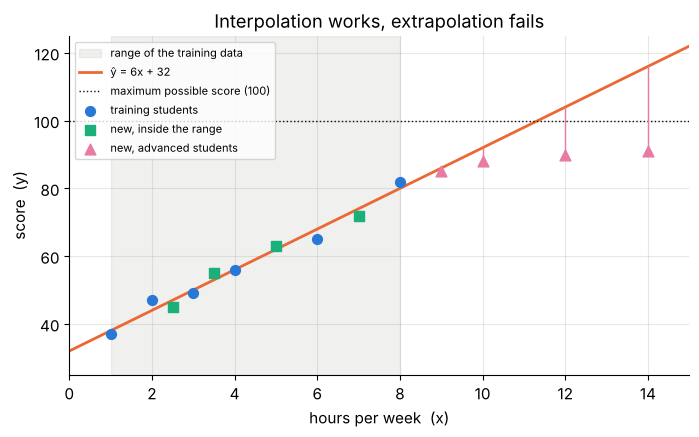

In [53]:
fig, ax = plt.subplots(figsize=(8, 4.4))
x_ext = np.linspace(0, 15, 100)
ax.axvspan(x.min(), x.max(), color=MUTED, alpha=0.12, label="range of the training data")
ax.plot(x_ext, predict(x_ext, w_star, b_star), color=ORANGE, lw=2, label="ŷ = 6x + 32")
ax.axhline(100, color=INK, lw=1, ls=":", label="maximum possible score (100)")
ax.scatter(x, y, s=50, color=BLUE, zorder=3, label="training students")
ax.scatter(new_inside["hours"], new_inside["score"], s=60, marker="s", color=AQUA, zorder=3, label="new, inside the range")
ax.scatter(new_outside["hours"], new_outside["score"], s=60, marker="^", color=MAGENTA, zorder=3,
           label="new, advanced students")
ax.vlines(new_outside["hours"], new_outside["score"], new_outside["prediction"], color=MAGENTA, lw=1)
ax.set(xlabel="hours per week  (x)", ylabel="score  (y)", title="Interpolation works, extrapolation fails",
       xlim=(0, 15), ylim=(25, 125))
ax.legend(fontsize=8, loc="upper left")
plt.show()

Inside the training range the line works well ($R^2 = 0.967$, RMSE 1.80 points). For the
advanced students it is a disaster: $R^2 = -38.9$. Their scores level off near 90 (the test
has a maximum of 100 and extra hours bring diminishing returns), while the straight line keeps
climbing and predicts an impossible 116 points for 14 hours. Their scores also vary very little
(SST = 21), so even moderate mistakes look terrible compared with "always predict 88.5".

> **Key idea.** Judge a model on data it has not seen, and do not trust it far outside the
> range of the data it was trained on (extrapolation). A negative $R^2$ simply means "worse
> than predicting the average of the evaluation data".

### ✏️ Exercise 10: the $R^2$ score

Implement `r_squared(y, y_hat)` $= 1 - \text{SSE}/\text{SST}$, where SST uses the mean of `y`
(the data being evaluated).

In [54]:
# ✏️ Exercise 10: R²
def r_squared(y, y_hat):
    """Return the coefficient of determination 1 - SSE/SST of predictions y_hat for targets y."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(r_squared(y, predict(x, 6.0, 32.0)), 1 - 24 / 1248), "best line on the students: 1 − 24/1248"
    assert np.isclose(r_squared(y, np.full(n, y.mean())), 0.0), "predicting the mean must give exactly 0"
    assert np.isclose(r_squared(y, predict(x, 2.0, 20.0)), 1 - 5272 / 1248), "line A should be negative: 1 − 5272/1248"
    test_rng = np.random.default_rng(1)
    yt, yp = test_rng.normal(size=20), test_rng.normal(size=20)
    assert np.isclose(r_squared(yt, yp), r2_score(yt, yp)), "disagrees with sklearn.metrics.r2_score"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def r_squared(y, y_hat):
    sse = np.sum((y - y_hat) ** 2)
    sst = np.sum((y - np.mean(y)) ** 2)
    return 1 - sse / sst
```
Note that $R^2$ is not symmetric in its arguments: the mean in SST comes from the true values.
(It is undefined when all true values are equal, because then SST = 0.)
</details>

### 9.3 Residual plots: let the leftovers talk

A single number cannot tell you *how* a model fails. The **residual plot**, residuals
$r_i = y_i - \hat y_i$ against $x_i$ (or against $\hat y_i$), can. If a straight line is the
right model, the residuals should look like a structureless horizontal band around zero.

To see why this matters, the cell below builds four synthetic clubs of ten students each.
Each dataset is constructed so that its least-squares line is **exactly** $\hat y = 6x + 32$
and its SSE is exactly 40, so all four have the same $R^2$. (Construction: take a pattern,
subtract its own least-squares line so that it cannot change the fitted line, rescale it to
SSE 40, and add it to $6x + 32$.)

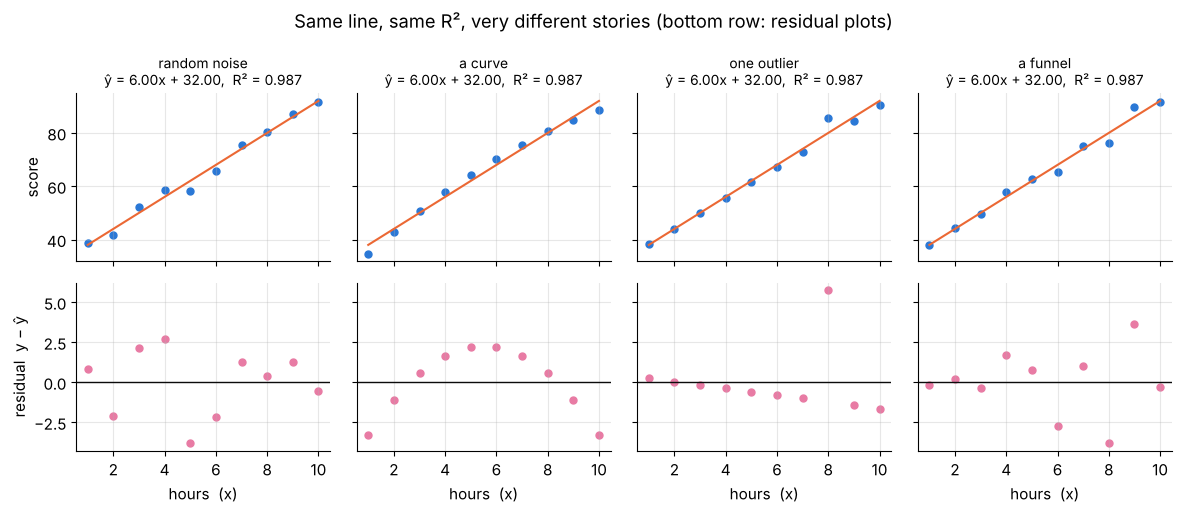

In [55]:
x_q = np.arange(1, 11, dtype=float)                      # 10 students practicing 1..10 hours
A_q = np.column_stack([np.ones_like(x_q), x_q])
P_q = A_q @ np.linalg.solve(A_q.T @ A_q, A_q.T)          # projection onto "lines in x"
quartet_rng = np.random.default_rng(SEED)
patterns = {
    "random noise": quartet_rng.normal(size=10),
    "a curve": -(x_q - 5.5) ** 2,
    "one outlier": np.where(x_q == 8, 1.0, 0.0),
    "a funnel": quartet_rng.normal(size=10) * x_q,
}
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True, sharey="row")
for k, (name, pattern) in enumerate(patterns.items()):
    r_part = pattern - P_q @ pattern                     # remove the pattern's own line
    r_part *= np.sqrt(40.0 / np.sum(r_part ** 2))        # rescale to SSE = 40
    y_q = 32 + 6 * x_q + r_part
    w_q, b_q = np.polyfit(x_q, y_q, 1)
    resid_q = y_q - (w_q * x_q + b_q)
    axes[0, k].scatter(x_q, y_q, s=25, color=BLUE)
    axes[0, k].plot(x_q, w_q * x_q + b_q, color=ORANGE, lw=1.5)
    axes[0, k].set_title(f"{name}\nŷ = {w_q:.2f}x + {b_q:.2f},  R² = {r2_score(y_q, w_q * x_q + b_q):.3f}", fontsize=10)
    axes[1, k].axhline(0, color=INK, lw=1)
    axes[1, k].scatter(x_q, resid_q, s=25, color=MAGENTA)
    axes[1, k].set_xlabel("hours  (x)")
axes[0, 0].set_ylabel("score")
axes[1, 0].set_ylabel("residual  y − ŷ")
fig.suptitle("Same line, same R², very different stories (bottom row: residual plots)")
fig.tight_layout()
plt.show()

Reading the residual plots (bottom row):

1. **Random noise:** no pattern. This is what a healthy fit looks like.
2. **A curve:** residuals are negative at both ends and positive in the middle. The true
   relationship bends, and a straight line is the wrong model (a later notebook adds features
   such as $x^2$ to fix this).
3. **One outlier:** one residual is far from the rest. Check that data point (Section 9.4).
4. **A funnel:** the spread grows with $x$. The line itself is fine, but the uncertainty
   statements of Section 10 assume constant spread and become unreliable.

> **Going deeper.** The statistician Francis Anscombe made the same point in 1973 with four
> famous hand-made datasets (Anscombe's quartet) that share means, variances, correlation and
> regression line, yet look nothing alike. Always plot your data and your residuals.

For our six students the residuals are $-1, -3, -1, 2, 0, 3$ (from Section 8). With six points
no pattern can be detected reliably, an honest limitation of tiny datasets.

### 9.4 Outliers, leverage and influence

Suppose a seventh student joins the club. Consider three alternative scenarios:

1. **Average hours, terrible score:** 4 hours, 26 points (misread the start time and lost half
   the contest).
2. **Lots of practice, on trend:** 11 hours, 98 points (exactly what the line predicts:
   $6 \cdot 11 + 32 = 98$).
3. **Lots of practice, terrible score:** 11 hours, 40 points (fell ill on contest day).

How much does each one move the least-squares line?

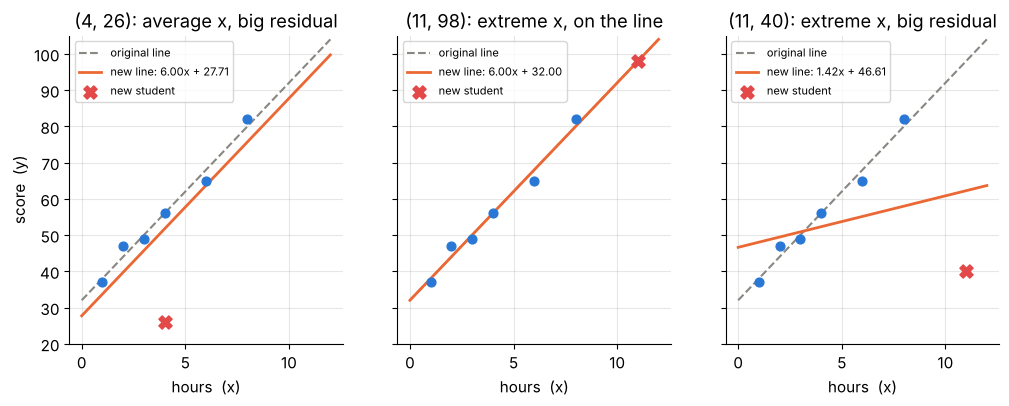

,w,b,leverage h,Cook's distance,prediction for Gus
scenario,,,,,
"(4, 26): average x, big residual",6.000,27.714,0.143,0.404,69.714
"(11, 98): extreme x, on the line",6.000,32.000,0.617,0.000,74.000
"(11, 40): extreme x, big residual",1.421,46.609,0.617,3.946,56.556


In [56]:
scenarios = {"(4, 26): average x, big residual": (4.0, 26.0),
             "(11, 98): extreme x, on the line": (11.0, 98.0),
             "(11, 40): extreme x, big residual": (11.0, 40.0)}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, (name, (x_new, y_new)) in zip(axes, scenarios.items()):
    x7, y7 = np.append(x, x_new), np.append(y, y_new)
    ols7 = sm.OLS(y7, sm.add_constant(x7)).fit()
    b7, w7 = ols7.params
    influence = ols7.get_influence()
    rows.append({"scenario": name, "w": w7, "b": b7, "leverage h": influence.hat_matrix_diag[-1],
                 "Cook's distance": influence.cooks_distance[0][-1], "prediction for Gus": w7 * GUS_HOURS + b7})
    x_line = np.linspace(0, 12, 50)
    ax.plot(x_line, predict(x_line, w_star, b_star), color=MUTED, lw=1.5, ls="--", label="original line")
    ax.plot(x_line, predict(x_line, w7, b7), color=ORANGE, lw=2, label=f"new line: {w7:.2f}x + {b7:.2f}")
    ax.scatter(x, y, s=40, color=BLUE, zorder=3)
    ax.scatter([x_new], [y_new], s=90, marker="X", color=RED, zorder=4, label="new student")
    ax.set(title=name, xlabel="hours  (x)", ylim=(20, 105))
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("score  (y)")
plt.show()
display(pd.DataFrame(rows).set_index("scenario").round(3))

Three very different outcomes:

1. The student at the **average** $x$ drags the whole line down by $30/7 \approx 4.29$ points
   ($b$: 32 → 27.71) but leaves the slope at exactly 6. A point at $\bar x$ has no lever arm.
2. The far-away student **on the trend** changes nothing at all: Cook's distance 0.
3. The far-away student **off the trend** tilts the line from slope 6 to 1.42 and drops Gus's
   prediction from 74 to 56.56. One student out of seven ruins the fit.

Two quantities explain this. The **leverage** measures how far a point's $x$ is from the
others. Since $w^* = \sum_j (x_j - \bar x)\,y_j / S_{xx}$ (the $\bar y$ term drops out because
deviations sum to zero), each fitted value is a weighted sum of all the labels,

$$
\hat y_i = \bar y + w^*(x_i - \bar x) = \sum_j h_{ij}\, y_j,
\qquad h_{ij} = \frac{1}{n} + \frac{(x_i - \bar x)(x_j - \bar x)}{S_{xx}},
$$

and the leverage of point $i$ is $h_{ii} = \frac{1}{n} + \frac{(x_i - \bar x)^2}{S_{xx}}$: how much
its own label pulls on its own fitted value. It is smallest at $\bar x$ (here $1/7 \approx 0.143$),
grows quadratically with the distance from $\bar x$ (0.617 at 11 hours), and the leverages of
all points always add up to 2, the number of parameters. **Influence** needs both leverage and
surprise: **Cook's distance** combines the residual and the leverage into one number that
measures how much all fitted values would move if the point were deleted. A common rule of
thumb flags $D_i > 1$, and scenario 3 has $D = 3.95$.

> **Common pitfall.** Do not delete outliers just because they are inconvenient. First find out
> *why* the point is unusual (a typo? a different population? a real but rare event?). If you
> cannot decide, report the fit with and without the point, or use a robust loss.

In [57]:
leverage = 1 / n + (x - x.mean()) ** 2 / S_xx
print("leverages of the six students:", dict(zip(students["student"], leverage.round(3).tolist())))
print("sum of leverages:", leverage.sum().round(6))

leverages of the six students: {'Ava': 0.196, 'Ben': 0.284, 'Chen': 0.431, 'Dana': 0.637, 'Eli': 0.167, 'Fay': 0.284}
sum of leverages: 2.0


Among our six students, Dana ($x = 8$, farthest from $\bar x = 4$) has the largest leverage,
0.637, and Eli (exactly average) the smallest, $1/6 \approx 0.167$.

### 9.5 Robust losses: absolute error and Huber

Section 2.5 showed that absolute error is far less sensitive to outliers than squared error. The
**Huber loss** combines the best of both: quadratic for small errors (smooth, efficient),
linear for large ones (robust). With a threshold $\delta > 0$,

$$
\rho_\delta(e) = \begin{cases} \tfrac{1}{2} e^2 & \text{if } |e| \le \delta, \\[1mm]
                 \delta\left(|e| - \tfrac{1}{2}\delta\right) & \text{if } |e| > \delta, \end{cases}
\qquad
\rho_\delta'(e) = \operatorname{clip}(e, -\delta, \delta).
$$

The derivative tells the story: under squared loss a student's pull on the line grows without
limit as the error grows, under absolute loss every student pulls with the same strength, and
under Huber loss the pull grows like squared loss but is **capped** at $\delta$.

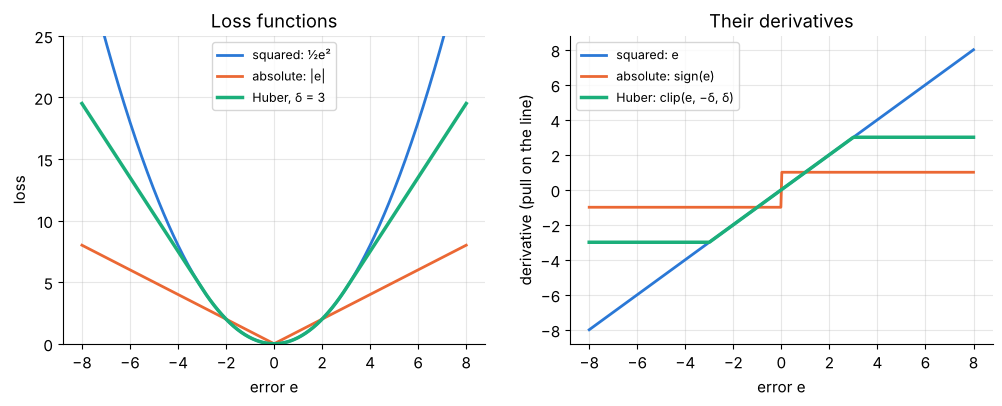

In [58]:
e_grid = np.linspace(-8, 8, 400)
DELTA = 3.0
huber = np.where(np.abs(e_grid) <= DELTA, 0.5 * e_grid ** 2, DELTA * (np.abs(e_grid) - 0.5 * DELTA))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(e_grid, 0.5 * e_grid ** 2, color=BLUE, lw=2, label="squared: ½e²")
axes[0].plot(e_grid, np.abs(e_grid), color=ORANGE, lw=2, label="absolute: |e|")
axes[0].plot(e_grid, huber, color=AQUA, lw=2.5, label=f"Huber, δ = {DELTA:g}")
axes[0].set(xlabel="error e", ylabel="loss", title="Loss functions", ylim=(0, 25))
axes[1].plot(e_grid, e_grid, color=BLUE, lw=2, label="squared: e")
axes[1].plot(e_grid, np.sign(e_grid), color=ORANGE, lw=2, label="absolute: sign(e)")
axes[1].plot(e_grid, np.clip(e_grid, -DELTA, DELTA), color=AQUA, lw=2.5, label="Huber: clip(e, −δ, δ)")
axes[1].set(xlabel="error e", ylabel="derivative (pull on the line)", title="Their derivatives")
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

Gradient descent handles the Huber loss with no new ideas: in the gradient formulas of
Section 4, replace the error $e_i$ by $\operatorname{clip}(e_i, -\delta, \delta)$. The function
below does this on the standardized feature (Section 7, so a learning rate of 1 is safe) and
converts the result back. For the absolute loss (LAD, "least absolute deviations") we use
`statsmodels`' median regression. We take $\delta = 3$ points, a little above the typical
error of the clean fit (a common choice is $\delta \approx 1.35\,\sigma$, where $\sigma$ is
the noise scale).

In [59]:
def fit_huber(xx, yy, delta, steps=2000, lr=1.0):
    """Fit y ≈ w*x + b with the mean Huber loss by gradient descent on the standardized feature."""
    mu, sd = xx.mean(), xx.std()
    z = (xx - mu) / sd
    w_z, c = 0.0, yy.mean()
    for _ in range(steps):
        psi = np.clip(w_z * z + c - yy, -delta, delta)     # clipped errors = derivative of the Huber loss
        w_z, c = w_z - lr * np.mean(psi * z), c - lr * np.mean(psi)
    return w_z / sd, c - w_z / sd * mu


def fit_lad(xx, yy):
    """Least-absolute-deviations line (median regression), returning (w, b)."""
    params = sm.QuantReg(yy, sm.add_constant(xx)).fit(q=0.5).params
    return params[1], params[0]


def fit_least_squares(xx, yy):
    """Ordinary least-squares line, returning (w, b)."""
    w_fit, b_fit = np.polyfit(xx, yy, 1)
    return w_fit, b_fit


methods = {"least squares": fit_least_squares,
           f"Huber (δ = {DELTA:g})": lambda xx, yy: fit_huber(xx, yy, DELTA),
           "least absolute deviations": fit_lad}
rows = []
for name, (x_new, y_new) in [("original six students", (None, None)), *scenarios.items()]:
    x7 = x if x_new is None else np.append(x, x_new)
    y7 = y if y_new is None else np.append(y, y_new)
    for method, fit in methods.items():
        w_fit, b_fit = fit(x7, y7)
        rows.append({"data": name, "method": method, "w": w_fit, "b": b_fit,
                     "prediction for Gus": w_fit * GUS_HOURS + b_fit})
robust = pd.DataFrame(rows).set_index(["data", "method"])
display(robust.round(3))

w       b  prediction for Gus
data                              method                                                      
original six students             least squares              6.000  32.000              74.000
                                  Huber (δ = 3)              6.000  32.000              74.000
                                  least absolute deviations  6.333  30.667              75.000
(4, 26): average x, big residual  least squares              6.000  27.714              69.714
                                  Huber (δ = 3)              6.041  31.219              73.507
                                  least absolute deviations  6.333  30.667              75.000
(11, 98): extreme x, on the line  least squares              6.000  32.000              74.000
                                  Huber (δ = 3)              6.000  32.000              74.000
                                  least absolute deviations  6.100  30.900              73.600
(11, 40): extreme x, big residual least squares              1.421  46.609              56.556
                                  Huber (δ = 3)              4.629  36.143              68.543
                                  least absolute deviations  4.500  38.000              69.500

* **Clean data:** the Huber fit is *identical* to least squares, because no residual exceeds
  $\delta = 3$ (the largest is exactly 3), so the Huber loss never leaves its quadratic zone.
  Least absolute deviations gives a slightly different line: it is a different estimator, not
  a better or worse one.
* **Scenario 1** (outlier at an ordinary $x$): least squares lowers the whole line by 4.29 points.
  The Huber line barely moves ($b = 31.22$, Gus's prediction 73.51), and the least-absolute-
  deviations line does not move at all.
* **Scenario 3** (outlier with high leverage): the robust fits do much better than least
  squares (slopes 4.63 and 4.50 instead of 1.42) but are **not immune**. A point far out on the
  $x$ axis has a long lever arm, and even a capped pull, multiplied by that lever arm, still
  tilts the line. No loss function replaces looking at the data.

## 10. The statistics view: uncertainty and assumptions

Machine learning asks "which line fits best?". Statistics asks one more question: *if the
coach repeated the whole experiment with six different students, how different would the line
be?* Answering it turns $w^*$ and $b^*$ from "the answer" into **estimates** with error bars.

### 10.1 A model for the noise, and the sampling distribution of the slope

Assume (as in Section 2.4) that scores come from a true line plus independent Gaussian noise:

$$
y_i = \beta_1 x_i + \beta_0 + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2)\ \text{independently}.
$$

The true slope $\beta_1$, intercept $\beta_0$ and noise level $\sigma$ are unknown. From now on
we write $\hat w$ and $\hat b$ (hats for *estimates*) for the least-squares line computed from
one particular sample. A different sample of students would give different estimates, so
$\hat w$ is a random variable. To see its distribution, let us *pretend* we know the truth,
$\beta_1 = 6$, $\beta_0 = 32$, $\sigma^2 = 6$, and simulate 4000 clubs with the same practice
hours but fresh noise.

simulated slopes: mean = 6.0154,  standard deviation = 0.4207
theory: mean = 6,  standard deviation σ/√S_xx = 0.4201


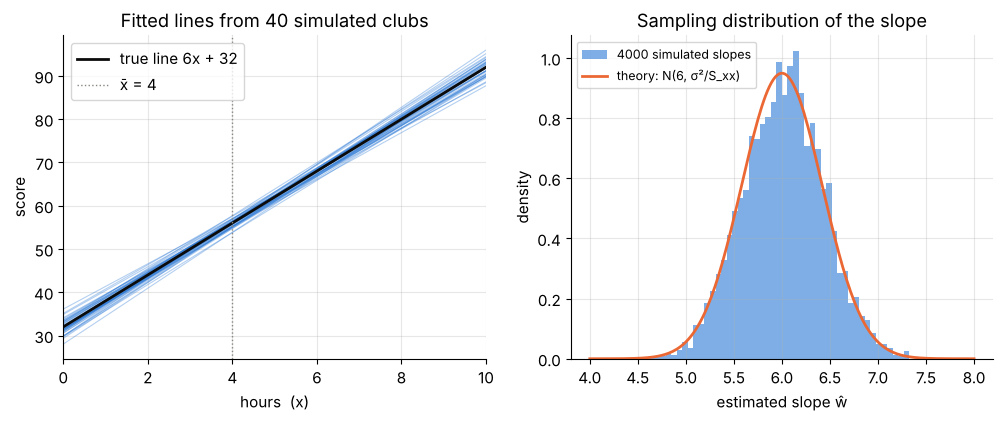

In [60]:
sim_rng = np.random.default_rng(SEED)
R_SIM, SIGMA_TRUE = 4000, np.sqrt(6.0)
Y_sim = 32 + 6 * x + sim_rng.normal(0, SIGMA_TRUE, size=(R_SIM, n))       # shape (4000, 6): one club per row
dx = x - x.mean()
w_sim = (Y_sim - Y_sim.mean(axis=1, keepdims=True)) @ dx / S_xx           # 4000 least-squares slopes at once
b_sim = Y_sim.mean(axis=1) - w_sim * x.mean()
print(f"simulated slopes: mean = {w_sim.mean():.4f},  standard deviation = {w_sim.std():.4f}")
print(f"theory: mean = 6,  standard deviation σ/√S_xx = {SIGMA_TRUE / np.sqrt(S_xx):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for k in range(40):
    axes[0].plot(xs, w_sim[k] * xs + b_sim[k], color=BLUE, lw=0.8, alpha=0.35)
axes[0].plot(xs, 6 * xs + 32, color=INK, lw=2, label="true line 6x + 32")
axes[0].axvline(x.mean(), color=MUTED, lw=1, ls=":", label="x̄ = 4")
axes[0].set(xlabel="hours  (x)", ylabel="score", title="Fitted lines from 40 simulated clubs", xlim=(0, 10))
axes[0].legend(loc="upper left")
axes[1].hist(w_sim, bins=50, density=True, color=BLUE, alpha=0.6, label="4000 simulated slopes")
w_axis = np.linspace(4, 8, 200)
axes[1].plot(w_axis, stats.norm.pdf(w_axis, 6, SIGMA_TRUE / np.sqrt(S_xx)), color=ORANGE, lw=2,
             label="theory: N(6, σ²/S_xx)")
axes[1].set(xlabel="estimated slope ŵ", ylabel="density", title="Sampling distribution of the slope")
axes[1].legend(loc="upper left", fontsize=9)
plt.show()

The fitted lines wobble, and they wobble least near the center of the data, $\bar x = 4$, and
most at the edges, like a bow tie. The histogram matches the theory, which is short enough to
derive. Since $\sum_j (x_j - \bar x) = 0$, the slope is a weighted sum of the labels,

$$
\hat w = \sum_j c_j\, y_j, \qquad c_j = \frac{x_j - \bar x}{S_{xx}},
\qquad \sum_j c_j = 0, \qquad \sum_j c_j x_j = 1 .
$$

* **Mean:** $\mathbb{E}[\hat w] = \sum_j c_j(\beta_1 x_j + \beta_0) = \beta_1 \cdot 1 + \beta_0 \cdot 0 = \beta_1$.
  The estimate is **unbiased**.
* **Variance:** the $y_j$ are independent with variance $\sigma^2$, so
  $\operatorname{Var}(\hat w) = \sigma^2\sum_j c_j^2 = \sigma^2 S_{xx}/S_{xx}^2 = \sigma^2/S_{xx}$.

So the **standard error** of the slope is $\sigma/\sqrt{S_{xx}}$. To measure a slope precisely,
collect more data *and* spread the $x$ values out, both of which increase $S_{xx}$. A similar
computation gives $\operatorname{Var}(\hat b) = \sigma^2\left(\frac{1}{n} + \frac{\bar x^2}{S_{xx}}\right)$.

### 10.2 Estimating the noise level: why divide by $n - 2$?

In reality $\sigma$ is unknown, so we estimate it from the residuals:

$$
s^2 = \frac{\text{SSE}}{n - 2} = \frac{24}{4} = 6, \qquad s \approx 2.449 .
$$

Why $n - 2$ and not $n$? The residuals are not free: they satisfy the two constraints
$\sum_i r_i = 0$ and $\sum_i x_i r_i = 0$ (Section 8.3), so only $n - 2$ of them can vary
independently (**degrees of freedom**). Put differently, the line was chosen to make SSE as
small as possible for *this* sample, so SSE systematically underestimates the noise, and one can
show $\mathbb{E}[\text{SSE}] = (n - 2)\sigma^2$. The simulated clubs confirm it:

In [61]:
SSE_sim = np.sum((Y_sim - (w_sim[:, None] * x + b_sim[:, None])) ** 2, axis=1)
print(f"true σ² = 6.   Average of SSE/(n−2) = {np.mean(SSE_sim / (n - 2)):.3f}.   "
      f"Average of SSE/n = {np.mean(SSE_sim / n):.3f}  (biased low: about 6·4/6 = 4)")
s_hat = np.sqrt(SSE / (n - 2))
se_w = s_hat / np.sqrt(S_xx)
se_b = s_hat * np.sqrt(1 / n + x.mean() ** 2 / S_xx)
print(f"our data: s = {s_hat:.4f},  SE(ŵ) = s/√S_xx = {se_w:.4f},  SE(b̂) = {se_b:.4f}")

true σ² = 6.   Average of SSE/(n−2) = 5.978.   Average of SSE/n = 3.985  (biased low: about 6·4/6 = 4)
our data: s = 2.4495,  SE(ŵ) = s/√S_xx = 0.4201,  SE(b̂) = 1.9554


### 10.3 Is the slope real? $t$-statistic, $p$-value and confidence interval

When $\sigma$ is replaced by its estimate $s$, the standardized slope

$$
T = \frac{\hat w - \beta_1}{\operatorname{SE}(\hat w)}
$$

follows a **Student $t$-distribution with $n - 2$ degrees of freedom**: a bell curve with heavier
tails than the normal, because $s$ itself is uncertain when it comes from only six points.

* **Test.** Could the true slope be zero (practice unrelated to score), with our slope a fluke?
  Under that hypothesis $T = \hat w/\operatorname{SE}(\hat w) = 6/0.4201 = 14.28$. The
  $p$-value is the probability, *if the true slope were zero*, of getting a $|T|$ at least that
  large: about 0.00014. Such data would be extremely unusual without a real slope.
* **Confidence interval.** $\hat w \pm t_{0.975,\,4}\cdot\operatorname{SE}(\hat w)
  = 6 \pm 2.776 \cdot 0.4201 = [4.83,\ 7.17]$ points per weekly hour.

In [62]:
t_crit = stats.t.ppf(0.975, df=n - 2)
t_stat = w_star / se_w
p_value = 2 * stats.t.sf(abs(t_stat), df=n - 2)
print(f"t_crit(0.975, 4) = {t_crit:.4f}.  t = {t_stat:.2f}.  p = {p_value:.2e}.  "
      f"95% CI for the slope = [{w_star - t_crit * se_w:.3f}, {w_star + t_crit * se_w:.3f}]")

ols_fit = sm.OLS(y, sm.add_constant(x)).fit()          # the same analysis with statsmodels
ci = ols_fit.conf_int(alpha=0.05)
coef_table = pd.DataFrame({"estimate": ols_fit.params, "std error": ols_fit.bse, "t": ols_fit.tvalues,
                           "p-value": ols_fit.pvalues, "95% CI low": ci[:, 0], "95% CI high": ci[:, 1]},
                          index=["intercept b", "slope w"])
display(coef_table.round({"estimate": 4, "std error": 4, "t": 3, "95% CI low": 3, "95% CI high": 3}))

t_crit(0.975, 4) = 2.7764.  t = 14.28.  p = 1.40e-04.  95% CI for the slope = [4.834, 7.166]


,estimate,std error,t,p-value,95% CI low,95% CI high
intercept b,32.0,1.9554,16.365,8.1610e-05,26.571,37.429
slope w,6.0,0.4201,14.283,1.3958e-04,4.834,7.166


`statsmodels` agrees with our hand calculation. What does "95% confidence" mean? Not that the
true slope has a 95% probability of lying in *this* interval (it either does or it does not),
but that the **procedure** captures the true slope in 95% of repeated experiments. Our
simulation can check this, and also show why the $t$ quantile 2.776 (instead of the familiar
normal quantile 1.96) matters for small samples:

In [63]:
s_sim = np.sqrt(SSE_sim / (n - 2))
se_sim = s_sim / np.sqrt(S_xx)
cover_t = np.mean(np.abs(w_sim - 6) <= t_crit * se_sim)
cover_z = np.mean(np.abs(w_sim - 6) <= 1.96 * se_sim)
print(f"share of 95% intervals that contain the true slope 6:  with t = {t_crit:.3f}: {cover_t:.3f}.  "
      f"With 1.96: {cover_z:.3f}")

share of 95% intervals that contain the true slope 6:  with t = 2.776: 0.946.  With 1.96: 0.875


With the $t$ quantile the intervals contain the truth 94.6% of the time, as advertised, and with
1.96 only 87.5% of the time, because they ignore the uncertainty in $s$.

> **Common pitfall.** A $p$-value is **not** the probability that the null hypothesis is true,
> and a tiny $p$-value does not mean the effect is large or important. It only says that data
> like ours would be surprising if the true slope were zero.

### 10.4 Confidence interval vs prediction interval: the case of Gus

At $x_0 = 7$ hours the line predicts $\hat y_0 = 74$. Two different questions have two
different answers:

1. **Where is the average score of *all* students who practice 7 hours?** This is the
   uncertainty of the line itself. Since $\hat y_0 = \bar y + \hat w(x_0 - \bar x)$ and
   $\bar y$ and $\hat w$ are uncorrelated (because $\sum_j c_j = 0$),
   $\operatorname{Var}(\hat y_0) = \sigma^2\left(\frac{1}{n} + \frac{(x_0 - \bar x)^2}{S_{xx}}\right)$, giving the
   **confidence interval** $\hat y_0 \pm t\, s\sqrt{\frac{1}{n} + \frac{(x_0 - \bar x)^2}{S_{xx}}}$.
2. **Where will *Gus's* score fall?** Gus has his own noise $\varepsilon_0$ on top, independent
   of the data, so the variance gains an extra $\sigma^2$: the **prediction interval** is
   $\hat y_0 \pm t\, s\sqrt{1 + \frac{1}{n} + \frac{(x_0 - \bar x)^2}{S_{xx}}}$.

The extra "1" never goes away: with infinitely many students the confidence interval shrinks to
a point, but the prediction interval approaches $\pm 1.96\,\sigma$, because individual students
remain unpredictable.

Gus (x = 7): prediction 74.  95% CI for the mean = [69.53, 78.47].  95% prediction interval = [65.86, 82.14]
statsmodels: {'mean': 74.0, 'mean_ci_lower': 69.53, 'mean_ci_upper': 78.47, 'obs_ci_lower': 65.86, 'obs_ci_upper': 82.14}


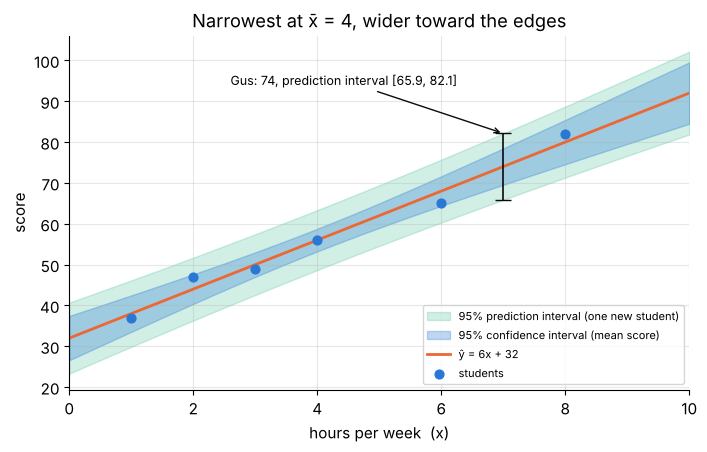

at x = 4 (x̄): CI ±2.78, PI ±7.35.   At x = 10: CI ±7.53, PI ±10.15


In [64]:
def interval_halfwidths(x0, level=0.95):
    """Half-widths (confidence, prediction) of the intervals at x0 for the students' fit."""
    t_q = stats.t.ppf(0.5 + level / 2, df=n - 2)
    lever = 1 / n + (x0 - x.mean()) ** 2 / S_xx
    return t_q * s_hat * np.sqrt(lever), t_q * s_hat * np.sqrt(1 + lever)


ci_half, pi_half = interval_halfwidths(GUS_HOURS)
y0 = predict(GUS_HOURS, w_star, b_star)
print(f"Gus (x = 7): prediction {y0:g}.  95% CI for the mean = [{y0 - ci_half:.2f}, {y0 + ci_half:.2f}].  "
      f"95% prediction interval = [{y0 - pi_half:.2f}, {y0 + pi_half:.2f}]")
frame = ols_fit.get_prediction(np.array([[1.0, GUS_HOURS]])).summary_frame(alpha=0.05)
print("statsmodels:", frame[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]].round(2).to_dict("records")[0])

x_band = np.linspace(0, 10, 101)
halfs = np.array([interval_halfwidths(v) for v in x_band])
center_band = predict(x_band, w_star, b_star)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.fill_between(x_band, center_band - halfs[:, 1], center_band + halfs[:, 1], color=AQUA, alpha=0.2,
                label="95% prediction interval (one new student)")
ax.fill_between(x_band, center_band - halfs[:, 0], center_band + halfs[:, 0], color=BLUE, alpha=0.3,
                label="95% confidence interval (mean score)")
ax.plot(x_band, center_band, color=ORANGE, lw=2, label="ŷ = 6x + 32")
ax.scatter(x, y, s=40, color=BLUE, zorder=3, label="students")
ax.errorbar([GUS_HOURS], [y0], yerr=[[pi_half], [pi_half]], fmt="none", ecolor=INK, capsize=6, lw=1.2)
ax.annotate(f"Gus: 74, prediction interval [{y0 - pi_half:.1f}, {y0 + pi_half:.1f}]",
            xy=(GUS_HOURS, y0 + pi_half), xytext=(2.6, 94), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=INK, lw=1))
ax.set(xlabel="hours per week  (x)", ylabel="score", title="Narrowest at x̄ = 4, wider toward the edges", xlim=(0, 10))
ax.legend(loc="lower right", fontsize=8)
plt.show()
print(f"at x = 4 (x̄): CI ±{interval_halfwidths(4.0)[0]:.2f}, PI ±{interval_halfwidths(4.0)[1]:.2f}.   "
      f"At x = 10: CI ±{interval_halfwidths(10.0)[0]:.2f}, PI ±{interval_halfwidths(10.0)[1]:.2f}")

For Gus: the average 7-hour student is expected to score between 69.53 and 78.47, while Gus
himself will most likely (95%) score between 65.86 and 82.14. Both intervals are narrowest at
$\bar x = 4$ (CI $\pm 2.78$) and widen toward the edges (at 10 hours, CI $\pm 7.53$ and PI
$\pm 10.15$). At 10 hours the prediction interval even reaches above 100: the model does not
know that scores are capped, a reminder that these intervals are only as good as the
assumptions behind them.

### ✏️ Exercise 11: a prediction interval

Implement `prediction_interval(x, y, x0, level=0.95)` that fits the least-squares line to
`(x, y)` and returns the pair `(low, high)` of the prediction interval for a new observation at
`x0`, using $s^2 = \text{SSE}/(n - 2)$ and the $t$ quantile `stats.t.ppf(0.5 + level/2, n - 2)`.

In [65]:
# ✏️ Exercise 11: prediction interval
def prediction_interval(x, y, x0, level=0.95):
    """Return (low, high) of the prediction interval at x0 for simple linear regression on (x, y)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.allclose(prediction_interval(x, y, 7.0), (65.8634, 82.1366), atol=1e-3), \
        f"Gus: expected about (65.86, 82.14), got {prediction_interval(x, y, 7.0)}"
    assert np.allclose(prediction_interval(x, y, 4.0), (48.6542, 63.3458), atol=1e-3), "at x̄ = 4: (48.65, 63.35)"
    test_rng = np.random.default_rng(3)
    xr = test_rng.uniform(0, 10, 25)
    yr = 1.5 * xr - 4 + test_rng.normal(0, 2, 25)
    ref = sm.OLS(yr, sm.add_constant(xr)).fit().get_prediction(np.array([[1.0, 8.5]])).summary_frame(alpha=0.10)
    lo, hi = prediction_interval(xr, yr, 8.5, level=0.90)
    assert np.allclose((lo, hi), (ref["obs_ci_lower"].iloc[0], ref["obs_ci_upper"].iloc[0])), \
        "90% interval on random data disagrees with statsmodels"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def prediction_interval(x, y, x0, level=0.95):
    n_ = len(x)
    dx = x - x.mean()
    s_xx = np.sum(dx ** 2)
    w = np.sum(dx * (y - y.mean())) / s_xx
    b = y.mean() - w * x.mean()
    s = np.sqrt(np.sum((y - (w * x + b)) ** 2) / (n_ - 2))
    half = stats.t.ppf(0.5 + level / 2, n_ - 2) * s * np.sqrt(1 + 1 / n_ + (x0 - x.mean()) ** 2 / s_xx)
    y0 = w * x0 + b
    return y0 - half, y0 + half
```
Dropping the `1 +` inside the square root turns this into the confidence interval for the mean
response.
</details>

### 10.5 The assumptions, and what breaks when they fail

Everything in this section rests on the noise model of 10.1. Its four parts are often
remembered as **LINE**:

| assumption | meaning | if it fails | how to check | typical remedy |
|---|---|---|---|---|
| **L**inearity | the average of $y$ is a straight-line function of $x$ | predictions are systematically off | residual plot shows a curve | transform variables, add features such as $x^2$ |
| **I**ndependence | errors of different samples are unrelated | standard errors too small (overconfident) | think about how the data were collected: repeated measurements, time order | models for grouped or time-series data |
| **N**ormality | the errors are normally distributed | small-sample intervals and $p$-values are off (matters less for large $n$) | Q-Q plot, Shapiro-Wilk test | more data, robust methods, transform $y$ |
| **E**qual variance | error spread is the same for all $x$ (homoscedasticity) | standard errors and intervals wrong | funnel in the residual plot, Breusch-Pagan test | robust (HC) standard errors, transform $y$, weighted least squares |

Notice what is *not* in the "if it fails" column: the least-squares line itself stays a
sensible, unbiased estimate when normality or equal variance fail, as long as linearity holds
and the errors average to zero. Those two assumptions matter for the *uncertainty statements*.
(Under linearity, independence and equal variance, the **Gauss-Markov theorem** even says least
squares has the smallest variance among all linear unbiased estimators, with no normality needed.)

### 10.6 A real dataset: TV advertising and sales

Six students are perfect for learning but too few to check assumptions. A classic real dataset
records, for 200 markets, the TV advertising budget (thousands of dollars) and the product's
sales (thousands of units). The cell downloads it once and caches it. Without internet access it
falls back to a clearly labeled synthetic stand-in (the numbers quoted below are for the real data).

In [66]:
ADV_URL = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
ADV_PATH = DATA_DIR / "Advertising.csv"


def load_advertising():
    """Return (DataFrame with columns TV and Sales, description of the source)."""
    if not ADV_PATH.exists():
        try:
            with urllib.request.urlopen(ADV_URL, timeout=20) as response:
                ADV_PATH.write_bytes(response.read())
        except Exception as err:                       # offline: build a stand-in with a similar structure
            print(f"Download failed ({type(err).__name__}). Using a SYNTHETIC stand-in dataset.")
            fake_rng = np.random.default_rng(SEED)
            tv = np.round(fake_rng.uniform(0.7, 296.4, 200), 1)
            sales = np.round(7.0 + 0.0475 * tv + fake_rng.normal(0.0, 1.0 + 0.013 * tv), 1)
            return pd.DataFrame({"TV": tv, "Sales": sales}), "synthetic stand-in"
    return pd.read_csv(ADV_PATH, index_col=0)[["TV", "Sales"]], f"{ADV_PATH.name} (real data)"


adv, adv_source = load_advertising()
print(f"source: {adv_source}.  Shape: {adv.shape}")
display(adv.describe().round(2).T)

source: Advertising.csv (real data).  Shape: (200, 2)


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4
Sales,200.0,14.02,5.22,1.6,10.38,12.90,17.40,27.0


In [67]:
tv, sales = adv["TV"].to_numpy(dtype=float), adv["Sales"].to_numpy(dtype=float)
adv_fit = sm.OLS(sales, sm.add_constant(tv)).fit()
adv_ci = adv_fit.conf_int(alpha=0.05)
display(pd.DataFrame({"estimate": adv_fit.params, "std error": adv_fit.bse, "t": adv_fit.tvalues,
                      "95% CI low": adv_ci[:, 0], "95% CI high": adv_ci[:, 1]},
                     index=["intercept", "TV slope"]).round(5))
print(f"R² = {adv_fit.rsquared:.4f}.  Residual standard deviation s = {np.sqrt(adv_fit.scale):.3f} thousand units")

# Gradient descent on the standardized feature (Section 7) finds the same line in one step.
tv_mu, tv_sd = tv.mean(), tv.std()
z_tv = (tv - tv_mu) / tv_sd
wz_tv, c_tv = 0.0, 0.0
for _ in range(3):
    e_tv = wz_tv * z_tv + c_tv - sales
    wz_tv, c_tv = wz_tv - 0.5 * 2 * np.mean(e_tv * z_tv), c_tv - 0.5 * 2 * np.mean(e_tv)
print(f"GD on standardized TV, η = 0.5:  slope = {wz_tv / tv_sd:.6f},  intercept = {c_tv - wz_tv / tv_sd * tv_mu:.6f}")
H_tv = 2 * np.array([[np.mean(tv ** 2), tv.mean()], [tv.mean(), 1.0]])
lam_tv = np.linalg.eigvalsh(H_tv)
print(f"with the RAW TV feature: condition number κ = {lam_tv[1] / lam_tv[0]:,.0f},  "
      f"largest stable learning rate = {2 / lam_tv[1]:.2e}")

,estimate,std error,t,95% CI low,95% CI high
intercept,7.0326,0.4578,15.3603,6.1297,7.9355
TV slope,0.0475,0.0027,17.6676,0.0422,0.0528


R² = 0.6119.  Residual standard deviation s = 3.259 thousand units
GD on standardized TV, η = 0.5:  slope = 0.047537,  intercept = 7.032594
with the RAW TV feature: condition number κ = 114,325,  largest stable learning rate = 3.45e-05


Interpretation: each extra \$1,000 of TV advertising goes with about 0.0475 thousand, i.e.
**47.5 more units sold** (95% CI roughly 42 to 53 units), and the TV budget accounts for
$R^2 \approx 61\%$ of the variation in sales across markets. (This is an association in
observational data: markets with big TV budgets may differ in other ways too.) Gradient descent
on the standardized budget reproduces the `statsmodels` line, while the raw budget, with values
up to about 300, would give a condition number above 100,000 and a learning-rate limit of about
$3.5 \times 10^{-5}$: Section 7 in action. Now the assumptions:

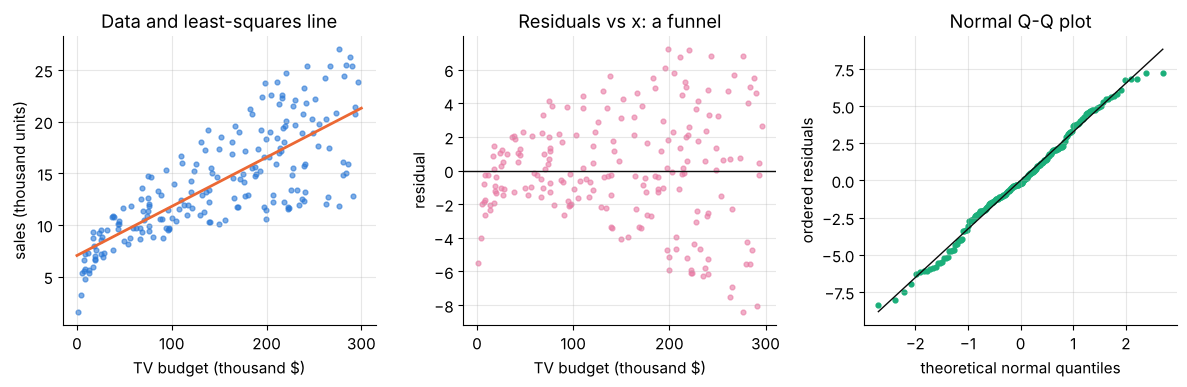

residual standard deviation by TV-budget tercile: {'low TV budget': 1.86, 'middle': 2.98, 'high TV budget': 4.42}
Breusch-Pagan test for equal variance: p = 4.2e-12.   Shapiro-Wilk normality test: p = 0.21
slope standard error: classic 0.00269  vs  robust HC3 0.00289.  Robust 95% CI = [0.0419, 0.0532]


In [68]:
adv_resid = adv_fit.resid
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
tv_line = np.linspace(0, 300, 50)
axes[0].scatter(tv, sales, s=12, color=BLUE, alpha=0.6)
axes[0].plot(tv_line, adv_fit.params[0] + adv_fit.params[1] * tv_line, color=ORANGE, lw=2)
axes[0].set(xlabel="TV budget (thousand $)", ylabel="sales (thousand units)", title="Data and least-squares line")
axes[1].scatter(tv, adv_resid, s=12, color=MAGENTA, alpha=0.6)
axes[1].axhline(0, color=INK, lw=1)
axes[1].set(xlabel="TV budget (thousand $)", ylabel="residual", title="Residuals vs x: a funnel")
(osm, osr), (qq_slope, qq_intercept, _) = stats.probplot(adv_resid, dist="norm")
axes[2].scatter(osm, osr, s=12, color=AQUA)
axes[2].plot(osm, qq_slope * osm + qq_intercept, color=INK, lw=1)
axes[2].set(xlabel="theoretical normal quantiles", ylabel="ordered residuals", title="Normal Q-Q plot")
fig.tight_layout()
plt.show()

terciles = pd.qcut(tv, 3, labels=["low TV budget", "middle", "high TV budget"])
print("residual standard deviation by TV-budget tercile:",
      pd.Series(adv_resid).groupby(terciles, observed=True).std().round(2).to_dict())
bp_pvalue = het_breuschpagan(adv_resid, adv_fit.model.exog)[1]
print(f"Breusch-Pagan test for equal variance: p = {bp_pvalue:.1e}.   Shapiro-Wilk normality test: "
      f"p = {stats.shapiro(adv_resid).pvalue:.2f}")
adv_hc3 = sm.OLS(sales, sm.add_constant(tv)).fit(cov_type="HC3")
print(f"slope standard error: classic {adv_fit.bse[1]:.5f}  vs  robust HC3 {adv_hc3.bse[1]:.5f}.  "
      f"Robust 95% CI = [{adv_hc3.conf_int()[1, 0]:.4f}, {adv_hc3.conf_int()[1, 1]:.4f}]")

* **Equal variance fails.** The residual plot is a funnel: the residual standard deviation grows
  from 1.86 in markets with low TV budgets to 4.42 in markets with high budgets, and the
  Breusch-Pagan test rejects equal variance decisively ($p \approx 4 \times 10^{-12}$). The
  line is still fine, but the classic standard errors are not to be trusted. **Robust (HC3)
  standard errors** do not assume equal variance, and here they are slightly larger (0.00289
  instead of 0.00269), so the honest confidence interval is a bit wider.
* **Normality looks acceptable.** The Q-Q plot is close to a straight line and Shapiro-Wilk
  gives $p = 0.21$ (no evidence against normality), and with 200 points the $t$ intervals would be
  reasonable anyway.
* **Linearity:** look closely at the residual plot and you may also see a slight bend (sales
  grow a little more slowly at high budgets). Diminishing returns are common in advertising, so a
  transformation such as $\sqrt{\text{TV}}$ is a natural next experiment.

**Quick check.** A colleague says: "The residuals of my regression fan out, so my slope
estimate is biased." Right or wrong?

<details>
<summary>Answer</summary>

Wrong. Unequal variance (heteroscedasticity) leaves the least-squares slope unbiased, as long as
the relationship is linear and the errors average to zero. What it breaks are the classic
standard errors, and with them the confidence intervals and $p$-values. Use robust standard
errors, or model the changing variance.
</details>

## 11. The same model in PyTorch

In Section 4 we derived the gradients by hand and in Section 5 we applied them by hand. Deep
learning frameworks automate the first job completely. While you compute the loss (the
**forward pass**), PyTorch quietly records every operation in a computational graph like the one
in Section 4.3. When you call `.backward()`, it walks that graph from the loss back to the
parameters and multiplies the local derivatives together: the chain rule, applied by a machine.
This is called **automatic differentiation** (autograd), and it is how networks with millions of
parameters get their gradients.

Autograd is not magic and not an approximation: it produces exactly the numbers our formulas
produce. Let us check that claim, then learn the five-line training loop that every later
notebook uses.

### 11.1 Autograd reproduces Ava's step

A tensor created with `requires_grad=True` is a **leaf** of the graph: a quantity PyTorch should
compute derivatives for. We use 64-bit floats (`torch.float64`) so that the comparison with NumPy
is exact. PyTorch's default `float32` keeps only about 7 significant digits, which is plenty for
training but would blur a digit-by-digit comparison.

In [69]:
from torch import nn

w_t = torch.tensor(W0, dtype=torch.float64, requires_grad=True)   # leaf tensors: autograd tracks them
b_t = torch.tensor(B0, dtype=torch.float64, requires_grad=True)
x_ava = torch.tensor(3.0, dtype=torch.float64)                      # data: no gradients needed
y_ava = torch.tensor(49.0, dtype=torch.float64)

y_hat_t = w_t * x_ava + b_t          # forward pass: PyTorch records each operation
loss_t = (y_hat_t - y_ava) ** 2
print(f"forward pass:   ŷ = {y_hat_t.item():g},  ℓ = {loss_t.item():g}")

loss_t.backward()                    # backward pass: chain rule from ℓ back to the leaves
print(f"autograd:       ∂ℓ/∂w = {w_t.grad.item():g},  ∂ℓ/∂b = {b_t.grad.item():g}")
e_ava = 2 * 3 + 20 - 49
print(f"hand formulas:  2x(ŷ − y) = {2 * 3 * e_ava},  2(ŷ − y) = {2 * e_ava}")

forward pass:   ŷ = 26,  ℓ = 529
autograd:       ∂ℓ/∂w = -138,  ∂ℓ/∂b = -46
hand formulas:  2x(ŷ − y) = -138,  2(ŷ − y) = -46


The same $-138$ and $-46$ we computed in Section 5.4. Which graph did PyTorch record? Every
result tensor remembers the operation that created it in its `.grad_fn` attribute, and each
`grad_fn` points to the nodes that fed into it. Walking from the loss backward:

In [70]:
def show_graph(fn, leaves, depth=0):
    """Print the backward graph recorded by autograd, starting from a grad_fn node."""
    if fn is None:                                   # an input that needs no gradient (x or y)
        return
    label = type(fn).__name__
    if hasattr(fn, "variable"):                      # AccumulateGrad: the end of a path, at a leaf
        names = [name for leaf, name in leaves if leaf is fn.variable]
        label += f"   (stores the gradient in .grad of leaf {names[0] if names else '?'})"
    print("    " * depth + label)
    for child, _ in fn.next_functions:
        show_graph(child, leaves, depth + 1)


show_graph(loss_t.grad_fn, leaves=[(w_t, "w"), (b_t, "b")])

PowBackward0
    SubBackward0
        AddBackward0
            MulBackward0
                AccumulateGrad   (stores the gradient in .grad of leaf w)
            AccumulateGrad   (stores the gradient in .grad of leaf b)


Read it from the top: `Pow` is the squaring node ($\ell = e^2$), `Sub` subtracts the label
($e = \hat y - y$), `Add` adds the intercept, `Mul` multiplies $w$ by $x$. It is the graph of
Section 4.3, read from right to left. During `.backward()` each node multiplies the incoming
derivative by its local derivative ($2e$, then $1$, then $1$ or $x$) and passes the product on.
The `AccumulateGrad` nodes at the ends store the results in `w_t.grad` and `b_t.grad`.

Now the update. Two details matter, and both are classic sources of bugs:

In [71]:
with torch.no_grad():                # the update itself must NOT be recorded in the graph
    w_t -= ETA * w_t.grad
    b_t -= ETA * b_t.grad
w_t.grad.zero_()                     # clear the stored gradients before the next backward pass
b_t.grad.zero_()
print(f"after one step: w = {w_t.item():.4f}, b = {b_t.item():.4f}   (hand calculation: 2.69, 20.23)")

after one step: w = 2.6900, b = 20.2300   (hand calculation: 2.69, 20.23)


### 11.2 Two autograd pitfalls, demonstrated

**Pitfall 1: gradients accumulate.** `.backward()` does not overwrite `.grad`. It **adds** to it.
Watch what happens if we compute Ava's loss three times and call `.backward()` each time
without clearing:

In [72]:
w_demo = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
for k in range(1, 4):
    loss_demo = (w_demo * 3 + 20 - 49) ** 2
    loss_demo.backward()
    print(f"after backward pass {k}: w.grad = {w_demo.grad.item():g}")

after backward pass 1: w.grad = -138
after backward pass 2: w.grad = -276
after backward pass 3: w.grad = -414


The gradient grows to $-276$ and $-414$: the sum of all backward passes so far. This behavior is
deliberate (it lets you add up gradients from several loss terms or several small batches before
one update), but it means every training step must clear the old gradients first, with
`.grad.zero_()` or, more commonly, `optimizer.zero_grad()`. Forgetting it is one of the most
common PyTorch bugs: each update then uses the sum of all past gradients, and training goes
haywire.

**Pitfall 2: updating a leaf outside `torch.no_grad()`.** If PyTorch recorded the update
$w \leftarrow w - \eta\,\partial\ell/\partial w$ as part of the graph, the next gradient would
include a derivative "through" the previous update, which is not what we want. PyTorch protects
you by refusing in-place changes to a leaf that requires gradients:

In [73]:
try:
    w_demo -= ETA * w_demo.grad      # no torch.no_grad() here, on purpose
except RuntimeError as err:
    print("RuntimeError:", str(err).split(".")[0] + ".")

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.


### 11.3 A whole epoch with autograd equals the hand-made table

Let us rerun the epoch of Section 5, but let autograd compute every gradient, and compare all
twelve gradients (two per student) with the `∂ℓ/∂w` and `∂ℓ/∂b` columns of the table `epoch1`.
Then we compute the gradient of the **average** loss over all students at the coach's guess,
which should match Section 4.4.

In [74]:
x_t = torch.tensor(x)                 # float64 (x is a float64 NumPy array), shape (6,)
y_t = torch.tensor(y)

w_t = torch.tensor(W0, dtype=torch.float64, requires_grad=True)
b_t = torch.tensor(B0, dtype=torch.float64, requires_grad=True)
auto_grads = []
for i in range(n):                    # per-sample SGD, students in table order
    loss_i = (w_t * x_t[i] + b_t - y_t[i]) ** 2
    loss_i.backward()
    auto_grads.append((w_t.grad.item(), b_t.grad.item()))
    with torch.no_grad():
        w_t -= ETA * w_t.grad
        b_t -= ETA * b_t.grad
    w_t.grad.zero_()
    b_t.grad.zero_()

gap = np.abs(np.array(auto_grads) - epoch1[["∂ℓ/∂w", "∂ℓ/∂b"]].to_numpy()).max()
print(f"largest |autograd − hand formula| over the epoch's 12 gradients: {gap:.1e}")
print(f"after one epoch: autograd (w, b) = ({w_t.item():.4f}, {b_t.item():.4f}).  "
      f"Hand table (w, b) = ({w1:.4f}, {b1:.4f})")

w_t = torch.tensor(W0, dtype=torch.float64, requires_grad=True)
b_t = torch.tensor(B0, dtype=torch.float64, requires_grad=True)
torch.mean((w_t * x_t + b_t - y_t) ** 2).backward()          # gradient of the training MSE
print(f"gradient of the MSE at (2, 20): autograd ({w_t.grad.item():.4f}, {b_t.grad.item():.4f}).  "
      f"Formula of Section 4.4 {grad_mse(W0, B0).round(4)}")

largest |autograd − hand formula| over the epoch's 12 gradients: 0.0e+00
after one epoch: autograd (w, b) = (7.1420, 21.1002).  Hand table (w, b) = (7.1420, 21.1002)
gradient of the MSE at (2, 20): autograd (-269.3333, -56.0000).  Formula of Section 4.4 [-269.3333  -56.    ]


Agreement to the last digit: the largest gap is exactly 0, and the final parameters and the
full-batch gradient $(-269.33, -56)$ match too. Autograd and the chain rule by hand are the same
mathematics.

> **Going deeper.** Autograd works backward from **one** scalar output to **many** inputs, and this
> is called *reverse-mode* differentiation. One backward pass costs only a small constant times
> one forward pass, no matter how many parameters there are. Finite differences (Section 4.5)
> would need two extra loss evaluations *per parameter*, which is hopeless for a network with a
> million parameters. That cost difference is why reverse mode (known in neural networks as
> *backpropagation*) powers all of deep learning.

### 11.4 The idiomatic way: a layer, a loss and an optimizer

In real code you rarely touch `.grad` yourself. Three building blocks do the bookkeeping:

| building block | what it holds or does | for us |
|---|---|---|
| `nn.Linear(1, 1)` | a weight of shape $(1, 1)$ and a bias of shape $(1,)$, and it computes `X @ weight.T + bias` | $w$ and $b$ |
| `nn.MSELoss()` | the mean of the squared errors (its default `reduction="mean"`) | $\mathcal{L}$ |
| `torch.optim.SGD(params, lr)` | `.step()` does $\theta \leftarrow \theta - \eta\,\theta.\text{grad}$ for every parameter, and `.zero_grad()` clears the gradients | the update rule |

A layer expects a **matrix** with one row per sample and one column per feature, so the six
hours become a column of shape $(6, 1)$, not a vector of shape $(6,)$. We start the layer at the
coach's guess and run **full-batch** gradient descent with $\eta = 0.02$, exactly the "good"
run of Section 7.3. If PyTorch does what we think it does, it must reproduce that run.

In [75]:
X_col = torch.tensor(x).unsqueeze(1)          # shape (6, 1): one row per student, one feature column
Y_col = torch.tensor(y).unsqueeze(1)          # shape (6, 1)


def make_model(w_init=W0, b_init=B0):
    """A linear layer with one input and one output, in float64, started at (w_init, b_init)."""
    layer = nn.Linear(1, 1).double()
    with torch.no_grad():
        layer.weight.fill_(w_init)
        layer.bias.fill_(b_init)
    return layer


model = make_model()
print("parameters:", [(name, tuple(p.shape)) for name, p in model.named_parameters()])
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)

torch_losses = []
for step in range(3000):
    optimizer.zero_grad()                     # 1. clear the gradients of the previous step
    pred = model(X_col)                       # 2. forward pass: predictions, shape (6, 1)
    loss = loss_fn(pred, Y_col)               # 3. the training MSE (a scalar tensor)
    loss.backward()                           # 4. autograd fills model.weight.grad and model.bias.grad
    optimizer.step()                          # 5. θ ← θ − η ∇L
    torch_losses.append(loss.item())          # the MSE at the parameters BEFORE this step

numpy_losses = lr_runs[0.02][1]               # the NumPy run of Section 7.3 (301 values)
print(f"MSE after 300 steps:  PyTorch {torch_losses[300]:.6f}   NumPy (Section 7.3) {numpy_losses[300]:.6f}")
print(f"after 3000 steps:  w = {model.weight.item():.6f},  b = {model.bias.item():.6f}.  "
      f"Closed form (Section 8): w* = {w_star:g},  b* = {b_star:g}")

parameters: [('weight', (1, 1)), ('bias', (1,))]


MSE after 300 steps:  PyTorch 4.069481   NumPy (Section 7.3) 4.069481
after 3000 steps:  w = 6.000000,  b = 32.000000.  Closed form (Section 8): w* = 6,  b* = 32


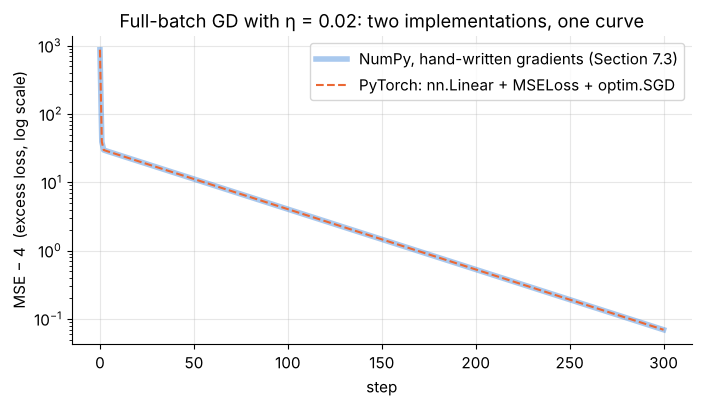

In [76]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(numpy_losses - 4.0, color=BLUE, lw=4, alpha=0.4, label="NumPy, hand-written gradients (Section 7.3)")
ax.plot(np.array(torch_losses[:301]) - 4.0, color=ORANGE, lw=1.5, ls="--", label="PyTorch: nn.Linear + MSELoss + optim.SGD")
ax.set(yscale="log", xlabel="step", ylabel="MSE − 4  (excess loss, log scale)",
       title="Full-batch GD with η = 0.02: two implementations, one curve")
ax.legend()
plt.show()

The two curves lie exactly on top of each other, and after 3000 steps the layer sits on the
least-squares solution $(6, 32)$ to six decimal places. Everything in this notebook (SGD,
mini-batches, learning rates) translates directly: for per-sample SGD feed the rows one at a time
with a `DataLoader`. With a batch of one row, `nn.MSELoss()` is exactly $(\hat y_i - y_i)^2$, so
one epoch must reproduce the hand-made table of Section 5:

In [77]:
from torch.utils.data import DataLoader, TensorDataset

loader = DataLoader(TensorDataset(X_col, Y_col), batch_size=1, shuffle=False)   # table order, one student per step
model_sgd = make_model()
opt_sgd = torch.optim.SGD(model_sgd.parameters(), lr=ETA)
for xb, yb in loader:                          # xb, yb have shape (1, 1)
    opt_sgd.zero_grad()
    loss_fn(model_sgd(xb), yb).backward()
    opt_sgd.step()
print(f"one epoch, batch_size = 1, η = {ETA}:  w = {model_sgd.weight.item():.4f},  b = {model_sgd.bias.item():.4f}   "
      f"(hand table: {w1:.4f}, {b1:.4f})")

one epoch, batch_size = 1, η = 0.005:  w = 7.1420,  b = 21.1002   (hand table: 7.1420, 21.1002)


Identical again. Change `batch_size=1` to `batch_size=2` for mini-batch gradient descent, set
`shuffle=True` for the reshuffled SGD of Section 6.4, or use `batch_size=6` for full-batch
descent: the loop itself never changes.

### 11.5 The scale of the loss is part of the learning rate

Different books and libraries define the loss differently: the SSE (sum), the MSE (mean), or
half the MSE (the $\frac12$ cancels the 2 from differentiating the square, making formulas
prettier). All three have the **same minimizer**, but their gradients differ by a constant
factor, so the same $\eta$ takes steps of different sizes. Autograd makes the factors visible:

In [78]:
loss_variants = {
    "MSE  (nn.MSELoss(), the mean)": lambda p, t: nn.MSELoss()(p, t),
    "SSE  (nn.MSELoss(reduction='sum'))": lambda p, t: nn.MSELoss(reduction="sum")(p, t),
    "half MSE  (0.5 * nn.MSELoss())": lambda p, t: 0.5 * nn.MSELoss()(p, t),
}
rows = {}
for name, fn in loss_variants.items():
    probe = make_model()                       # the coach's guess (2, 20)
    fn(probe(X_col), Y_col).backward()
    rows[name] = {"∂/∂w": probe.weight.grad.item(), "∂/∂b": probe.bias.grad.item()}
display(pd.DataFrame(rows).T.round(4))

,∂/∂w,∂/∂b
"MSE (nn.MSELoss(), the mean)",-269.3333,-56.0
SSE (nn.MSELoss(reduction='sum')),-1616.0000,-336.0
half MSE (0.5 * nn.MSELoss()),-134.6667,-28.0


The SSE gradient is $n = 6$ times the MSE gradient, and the half-MSE gradient is half of it.
So "$\eta = 0.02$ with the MSE" is the same algorithm as "$\eta = 0.02/6$ with the SSE" or
"$\eta = 0.04$ with half the MSE". With the SSE the safe learning rate also shrinks as the
dataset grows, one reason the mean is the usual default.

> **Common pitfall.** When you copy a learning rate from a paper, a tutorial or an old project,
> also copy the exact loss definition (sum or mean, with or without $\frac12$). Otherwise the
> "same" learning rate can be several times too large and diverge, or uselessly small.

**Quick check.**
1. Why do we pass the hours to `nn.Linear(1, 1)` as a tensor of shape $(6, 1)$ and not $(6,)$?
2. You train with `optimizer.zero_grad()` accidentally placed *after* `loss.backward()` and
   before `optimizer.step()`. What does the optimizer do?

<details>
<summary>Answer</summary>

1. A layer treats the **last** dimension as the features. A tensor of shape $(6, 1)$ is six
   samples with one feature each. A tensor of shape $(6,)$ would be read as *one* sample with six
   features, which does not fit a layer that expects one input, so PyTorch raises a shape error.
2. Nothing useful: the gradients are cleared (set to zero, or to `None` in recent PyTorch
   versions) just before the update would use them, so `step()` has nothing to apply, the
   parameters never change, and the loss stays flat. The correct order is `zero_grad()`,
   forward, loss, `backward()`, `step()`.
</details>

### ✏️ Exercise 12: a PyTorch training loop

Implement `torch_fit(xx, yy, lr, steps)`: build an `nn.Linear(1, 1)` layer in `float64` with
weight and bias both initialized to **zero**, train it with full-batch gradient descent on
`nn.MSELoss()` using `torch.optim.SGD` for `steps` steps, and return `(w, b)` as Python floats.
`xx` and `yy` are 1-D NumPy arrays.

In [79]:
# ✏️ Exercise 12: full-batch training with nn.Linear, nn.MSELoss and torch.optim.SGD
def torch_fit(xx, yy, lr, steps):
    """Train y ≈ w*x + b from w = b = 0 with full-batch GD in PyTorch, returning (w, b) as floats."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    w_fit, b_fit = torch_fit(x, y, lr=0.02, steps=3000)
    assert isinstance(w_fit, float) and isinstance(b_fit, float), "return Python floats (use .item())"
    assert np.allclose((w_fit, b_fit), (6.0, 32.0), atol=1e-6), f"students: expected (6, 32), got {(w_fit, b_fit)}"
    z = (x - x.mean()) / x.std()               # standardized hours: the bowl is round (Section 7.5)
    w_z, b_z = torch_fit(z, y, lr=0.25, steps=100)
    assert np.allclose((w_z, b_z), (6.0 * x.std(), 56.0), atol=1e-6), \
        f"standardized feature: expected ({6 * x.std():.4f}, 56), got {(w_z, b_z)}"
    w_one, b_one = torch_fit(x, y, lr=0.02, steps=1)
    assert np.allclose((w_one, b_one), (0.02 * 2 * np.mean(x * y), 0.02 * 2 * np.mean(y))), \
        "one step from (0, 0) is wrong: did you start at zero and use the MEAN squared error?"


run_check("Exercise 12", _test)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def torch_fit(xx, yy, lr, steps):
    X_ = torch.tensor(xx, dtype=torch.float64).unsqueeze(1)    # shape (n, 1)
    Y_ = torch.tensor(yy, dtype=torch.float64).unsqueeze(1)
    layer = nn.Linear(1, 1).double()
    nn.init.zeros_(layer.weight)
    nn.init.zeros_(layer.bias)
    opt = torch.optim.SGD(layer.parameters(), lr=lr)
    mse_loss = nn.MSELoss()
    for _ in range(steps):
        opt.zero_grad()
        mse_loss(layer(X_), Y_).backward()
        opt.step()
    return layer.weight.item(), layer.bias.item()
```
The third check works because one step from $(0, 0)$, where every prediction is 0 and every
error is $-y_i$, gives $w = \eta \cdot \frac{2}{n}\sum_i x_i y_i$ and $b = \eta \cdot \frac{2}{n}\sum_i y_i$.
With the standardized feature, $\eta = 0.25$ shrinks the distance to the minimum by half at every
step, so 100 steps are far more than enough.
</details>

## 12. Quiz

Fifteen exam-style questions. Work each one out on paper before opening the answer. The
explanations say why the right option is right **and** why each wrong option is wrong, because
the wrong options are the mistakes people actually make. Unless a question says otherwise, the
per-sample loss is $\ell = (\hat y - y)^2$ and the update is $\theta \leftarrow \theta - \eta\,\partial\ell/\partial\theta$.

**Q1.** A model $\hat y = wx + b$ currently has $w = 4$, $b = 10$. One SGD step with
$\eta = 0.01$ is taken on the single sample $(x, y) = (5, 26)$. What are the new parameters?

- (a) $w = 3.6$, $b = 9.92$
- (b) $w = 4.4$, $b = 10.08$
- (c) $w = 3.8$, $b = 9.96$
- (d) $w = 3.6$, $b = 9.6$

<details>
<summary>Answer</summary>

**(a).** Predict $\hat y = 4 \cdot 5 + 10 = 30$, with error $e = 30 - 26 = 4$ (too high). Gradients
$\partial\ell/\partial w = 2xe = 40$ and $\partial\ell/\partial b = 2e = 8$. Updates:
$w = 4 - 0.01 \cdot 40 = 3.6$ and $b = 10 - 0.01 \cdot 8 = 9.92$. Sanity check: the new prediction
is $3.6 \cdot 5 + 9.92 = 27.92$, error $1.92 = \rho e$ with $\rho = 1 - 2\eta(x^2 + 1) = 0.48$ (Section 5.2).

- (b) *adds* $\eta$ times the gradient: a step uphill, which makes the over-prediction worse.
- (c) forgets the factor 2 from differentiating the square (it uses $xe = 20$ and $e = 4$).
- (d) uses the slope gradient 40 for the intercept too. The intercept gradient has no factor $x$.
</details>

**Q2.** The feature has been centered, and a student has $x_c = -2$ (two hours below average).
The current line **over**-predicts her score. One SGD step on her loss alone will:

- (a) decrease both $w$ and $b$
- (b) increase $w$ and decrease $b$
- (c) decrease $w$ and increase $b$
- (d) change only $b$, because the slope does not depend on her error

<details>
<summary>Answer</summary>

**(b).** With $e > 0$: $\partial\ell/\partial b = 2e > 0$, so $b$ decreases, and
$\partial\ell/\partial w = 2x_c e = -4e < 0$, so $w$ **increases**. Both moves lower her
prediction $\hat y = -2w + b$: at a negative $x$, a steeper line is *lower*. In total
$\Delta\hat y = x_c\Delta w + \Delta b = -2\eta(x_c^2 + 1)e = -10\eta e$.

- (a) ignores that the negative lever arm $x_c$ flips the sign of the slope gradient.
- (c) is the update for an *under*-prediction.
- (d) would be true only at $x_c = 0$, the one place where the slope has no lever.
</details>

**Q3.** A model's residuals on four samples are $3, -1, -2, 0$. Which statement is correct?

- (a) SSE $= 14$, MSE $= 3.5$, RMSE $\approx 1.87$
- (b) SSE $= 0$, because the residuals cancel out
- (c) MSE $= 1.5$
- (d) RMSE $= 1.5$, the same as the mean absolute error

<details>
<summary>Answer</summary>

**(a).** SSE $= 9 + 1 + 4 + 0 = 14$, MSE $= 14/4 = 3.5$, RMSE $= \sqrt{3.5} \approx 1.87$.

- (b) The *plain* residuals do sum to zero ($3 - 1 - 2 + 0 = 0$), which is exactly why a loss
  squares them (or takes absolute values) before adding: otherwise big mistakes in opposite
  directions would cancel and look like a perfect fit.
- (c) $1.5 = (3 + 1 + 2 + 0)/4$ is the mean **absolute** error, not the mean squared error.
- (d) RMSE is never smaller than MAE (the root-mean-square of numbers is at least their mean),
  with equality only when all $|r_i|$ are equal. Here RMSE $\approx 1.87 >$ MAE $= 1.5$, and the gap
  comes from the large residual 3, which squaring emphasizes.
</details>

**Q4.** Keep the slope $w$ fixed and view the training MSE as a function of the intercept $b$
alone. What does the graph look like?

- (a) a straight line in $b$, so there is no minimum
- (b) an upward parabola with its lowest point at $b = \bar y - w\bar x$
- (c) an upward parabola with its lowest point at $b = \bar y$
- (d) a downward parabola, so gradient descent would climb to its top

<details>
<summary>Answer</summary>

**(b).** $\mathcal{L}(b) = \frac1n\sum_i (wx_i + b - y_i)^2$ is a quadratic in $b$ with
coefficient $+1$ on $b^2$ (second derivative $2 > 0$). Setting
$\mathcal{L}'(b) = 2(w\bar x + b - \bar y) = 0$ gives $b = \bar y - w\bar x$ (Section 3.1).

- (a) The square makes $\mathcal{L}$ quadratic, not linear, in $b$.
- (c) is the special case $w\bar x = 0$, for example after centering the feature. In general
  the best intercept depends on the slope.
- (d) A sum of squares opens upward. It is bounded below by 0 and has a minimum, not a maximum.
</details>

**Q5.** You run full-batch gradient descent on a raw feature whose values are in the
hundreds. After a few steps the printed loss becomes `inf`, then `nan`. What is the most likely
cause and fix?

- (a) Too few epochs: train longer.
- (b) The learning rate exceeds the stability limit $2/\lambda_{\max}$: lower it, or better,
  standardize the feature so that a moderate learning rate is stable.
- (c) Gradient descent got stuck in a bad local minimum: try a different initialization.
- (d) The samples were not shuffled.

<details>
<summary>Answer</summary>

**(b).** The largest curvature is roughly $2\overline{x^2}$, which is huge for features in the
hundreds (Section 10.6 found a limit of about $3.5 \times 10^{-5}$ for the raw TV budgets). Above
$2/\lambda_{\max}$ every step overshoots by more than the last, the loss grows geometrically,
overflows to `inf`, and `inf - inf` produces `nan`.

- (a) More steps of a divergent process only diverge further.
- (c) The MSE of linear regression is a convex bowl with a single minimum, so there are no bad
  local minima, and getting stuck would never produce `inf`.
- (d) Full-batch gradient descent uses all samples in every step, so the order is irrelevant.
</details>

**Q6.** For some dataset, $\bar x = 5$, $\bar y = 20$, $\sum_i (x_i - \bar x)(y_i - \bar y) = 36$
and $\sum_i (x_i - \bar x)^2 = 12$. What is the least-squares line?

- (a) $\hat y = 3x + 5$
- (b) $\hat y = 3x + 20$
- (c) $\hat y = x/3 + 18.33$
- (d) $\hat y = 3x - 5$

<details>
<summary>Answer</summary>

**(a).** $w^* = S_{xy}/S_{xx} = 36/12 = 3$ and $b^* = \bar y - w^*\bar x = 20 - 15 = 5$. Quick
check: the least-squares line always passes through $(\bar x, \bar y)$, and $3 \cdot 5 + 5 = 20$.

- (b) uses $b = \bar y$, which is correct only when $\bar x = 0$, and it predicts 35 at $\bar x$.
- (c) inverts the ratio ($S_{xx}/S_{xy}$). It passes through $(5, 20)$, so the centroid check
  alone does not catch it, but the slope formula does.
- (d) has a sign slip ($w\bar x - \bar y$), and it predicts 10 at $\bar x$.
</details>

**Q7.** In a dataset, the correlation between $x$ and $y$ is $r = -0.6$, the standard deviation
of $x$ is 4 and the standard deviation of $y$ is 10. What is the least-squares slope?

- (a) $-1.5$
- (b) $-0.24$
- (c) $-0.6$
- (d) $+1.5$

<details>
<summary>Answer</summary>

**(a).** $w^* = r\, s_y/s_x = -0.6 \cdot 10/4 = -1.5$ (Section 8.3): one standard deviation more
in $x$ goes with $0.6$ standard deviations *less* in $y$, and $0.6 \cdot 10 = 6$ units of $y$
per $4$ units of $x$ is $1.5$ per unit.

- (b) $= r\, s_x/s_y$, the ratio of spreads upside down.
- (c) The slope equals $r$ only when $s_x = s_y$, for instance when both variables are standardized.
- (d) The slope always has the same sign as $r$: both have the sign of $S_{xy}$.
</details>

**Q8.** A model has $R^2 = 0.85$ on its training data and $R^2 = -0.4$ on a new test set (with
the test set's own mean as the baseline). What does the negative value mean?

- (a) There must be a bug: $R^2$ is a square, so it cannot be negative.
- (b) On the test set, predicting the test mean for everyone would have a smaller squared error than the model.
- (c) The fitted slope must have the wrong sign.
- (d) The model explains $-40\%$ of the variance, so flipping the sign of its predictions would explain $+40\%$.

<details>
<summary>Answer</summary>

**(b).** $R^2 = 1 - \text{SSE}/\text{SST}$, and $R^2 = -0.4$ means $\text{SSE} = 1.4\,\text{SST}$:
the model's squared error is 40% larger than that of the constant prediction $\bar y_{\text{test}}$.

- (a) Despite its name, $R^2$ is not the square of anything in general. It equals $r^2$ (so lies
  in $[0, 1]$) only for a least-squares line with an intercept, evaluated on its own training data.
- (c) Not necessarily. A correct slope with a shifted level, or a curve that bends outside the
  training range (Section 9.2), can produce a negative $R^2$ just as well.
- (d) Flipping the sign of the predictions makes things far worse. There is no such symmetry.
</details>

**Q9.** A line is fitted to $n = 50$ students. At $x_0 = \bar x$, compare the 95% confidence
interval for the *mean* score with the 95% prediction interval for *one new* student.

- (a) They have the same width at $\bar x$, because the leverage term vanishes there.
- (b) The prediction interval is wider. As $n$ grows, the confidence interval shrinks toward
  zero width, but the prediction interval approaches about $\pm 1.96\,\sigma$.
- (c) The confidence interval is wider, because it must cover all students.
- (d) Both shrink to zero width as $n \to \infty$.

<details>
<summary>Answer</summary>

**(b).** The half-widths are $t\,s\sqrt{\frac1n + \frac{(x_0 - \bar x)^2}{S_{xx}}}$ and
$t\,s\sqrt{1 + \frac1n + \frac{(x_0 - \bar x)^2}{S_{xx}}}$. The extra "1" is the new student's
own noise $\sigma^2$, which no amount of data removes (Section 10.4).

- (a) Only the term $(x_0 - \bar x)^2/S_{xx}$ vanishes at $\bar x$. The $\frac1n$ and, for the
  prediction interval, the $1$ remain.
- (c) is backwards: one individual is harder to pin down than an average of many.
- (d) holds for the confidence interval only.
</details>

**Q10.** A dataset has $x$ values spread between 0 and 10 with mean $\bar x = 5$. Which single
added point would change the least-squares **slope** the most?

- (a) a point at $x = 5$, lying 30 units above the current line
- (b) a point at $x = 30$, lying exactly on the current line
- (c) a point at $x = 30$, lying 30 units below the current line
- (d) a point at $x = 7$, lying 5 units below the current line

<details>
<summary>Answer</summary>

**(c).** Influence needs both ingredients of Section 9.4: **leverage** (an $x$ far from
$\bar x$, a long lever arm) **and** a large residual (a strong pull). Point (c) has both, and it
rotates the line toward itself.

- (a) A point exactly at $\bar x$ has no lever arm: it does not change $\bar x$, $S_{xx}$ or $S_{xy}$,
  so the slope is unchanged, and only the line's height rises, by $30/(n+1)$.
- (b) High leverage but zero residual: the old line still has zero gradient after adding the
  point, so it stays optimal. The fitted line does not move at all.
- (d) A short lever arm and a moderate residual: a small change.
</details>

**Q11.** Per-sample SGD with the constant learning rate $\eta = 0.005$ on our six students ends
up circling near $(w, b) = (6.24, 31.58)$ instead of reaching the minimum $(6, 32)$ (Section 5.7).
Why?

- (a) The loss has a second, local minimum near $(6.24, 31.58)$.
- (b) At the minimum the *average* gradient is zero, but each student's own gradient is not,
  so every single-student step pushes the parameters away from it again.
- (c) Floating-point rounding errors accumulate over thousands of steps.
- (d) The learning rate is too small to reach the minimum.

<details>
<summary>Answer</summary>

**(b).** At $(6, 32)$ the residuals are not all zero, so the per-sample gradients
$2e_i(x_i, 1)$ are not zero either, and they only cancel *on average* (Section 6.3). Constant-step SGD
therefore settles into a cycle around the minimum, whose size shrinks as $\eta$ shrinks. A
decaying learning rate (Section 6.5) or a full-batch step removes the problem.

- (a) The MSE of linear regression is convex with a unique minimum.
- (c) Rounding errors are around $10^{-15}$, far too small to explain an offset of $0.24$ in $w$.
- (d) It is the other way around: a *smaller* constant $\eta$ ends closer to the minimum
  (but takes longer to get there).
</details>

**Q12.** Five scores are $50, 52, 55, 58, 100$. You must predict all of them with one constant
$c$. Which constants minimize the sum of squared errors and the sum of absolute errors, respectively?

- (a) $63$ and $55$
- (b) $55$ and $63$
- (c) $63$ and $63$
- (d) $55$ and $55$

<details>
<summary>Answer</summary>

**(a).** Squared error is minimized by the **mean**, $315/5 = 63$, and absolute error by the
**median**, $55$ (Section 2.5). The single outlier 100 pulls the mean 8 points above the
median. Without it, the other four scores have mean 53.75 and median 53.5: the outlier moves
the mean by 9.25 points but the median by only 1.5, and making it even more extreme (say 1000)
would push the mean to 243 while the median stays at 55. This is the robustness of absolute
error.

- (b) swaps the two.
- (c) The mean and the median coincide for symmetric data, but here one large score makes the
  data lopsided and pulls the mean (63) well above the median (55).
- (d) The squared loss is *not* robust: the term $(100 - c)^2$ dominates and pulls $c$ upward.
</details>

**Q13.** Replacing the feature $x$ by $x - \bar x$ makes gradient descent converge much faster.
Why?

- (a) The smallest achievable MSE becomes smaller.
- (b) The cross term between $w$ and $b$ disappears: the contours become axis-aligned, the
  largest curvature drops, and a larger learning rate is stable.
- (c) The slope of the best line becomes 0.
- (d) The gradient no longer depends on the data.

<details>
<summary>Answer</summary>

**(b).** With centered $x$ the Hessian $H = 2\begin{pmatrix}\overline{x^2} & \bar x\\ \bar x & 1\end{pmatrix}$
becomes diagonal, $2\operatorname{diag}(\operatorname{Var}(x), 1)$, so $w$ and $b$ can be
optimized independently. For our students $\lambda_{\max}$ drops from $44.83$ to $11.33$
(Sections 7.2 and 7.4), which allows learning rates four times larger and removes the thin, tilted valley.

- (a) Centering only renames the lines ($b$ now means the prediction at $\bar x$), and the best line
  and its MSE are unchanged.
- (c) The slope is unchanged, and only the intercept changes, to $\bar y$.
- (d) The gradient still depends on every $(x_i, y_i)$.
</details>

**Q14.** In a PyTorch training loop you forget `optimizer.zero_grad()`. What happens?

- (a) Nothing: `loss.backward()` overwrites the old gradients anyway.
- (b) Every `backward()` adds to the stored gradients, so each update uses the sum of all
  gradients so far. The parameters swing around the minimum without settling, or blow up.
- (c) PyTorch raises an error at the next `optimizer.step()`.
- (d) The parameters stop changing.

<details>
<summary>Answer</summary>

**(b).** Section 11.2 showed `.grad` going $-138, -276, -414$ over three backward passes. Using
a running sum of all past gradients is like a "momentum" that never forgets: on a quadratic
bowl it produces undamped oscillations (or divergence for large $\eta$) instead of convergence.

- (a) `backward()` accumulates on purpose, and it never overwrites.
- (c) PyTorch cannot know that you meant to clear the gradients, so nothing complains, and the bug is silent.
- (d) That is what happens when `zero_grad()` is called *between* `backward()` and `step()`
  (Section 11.5, quick check), not when it is forgotten.
</details>

**Q15.** A line fitted to 30 data points has a slope with $p$-value $0.003$ (two-sided test of
"the true slope is zero"). Which statement is correct?

- (a) There is a 0.3% probability that the true slope is zero.
- (b) If the true slope were zero, a $|t|$ at least as large as the observed one would occur in
  only about 0.3% of repeated samples.
- (c) The slope is large, so the feature has an important effect on $y$.
- (d) The model's predictions are correct 99.7% of the time.

<details>
<summary>Answer</summary>

**(b).** That is the definition (Section 10.3): the $p$-value is computed *assuming* the null
hypothesis, and measures how surprising data like ours would be under it.

- (a) is the most common misreading. It turns "probability of such data if the slope were zero"
  into "probability that the slope is zero given the data". Reversing a conditional probability
  requires Bayes' rule and a prior belief (Notebook 14), not a $p$-value.
- (c) Significance is not size. With enough data, even a tiny, unimportant slope gets a tiny
  $p$-value. Judge size from the estimate and its confidence interval, in the units of the problem
  (like the 42 to 53 extra units per \$1,000 of TV advertising in Section 10.6).
- (d) A $p$-value says nothing about prediction accuracy, while $R^2$, the RMSE and prediction
  intervals do.
</details>

## 13. Summary and going further

### 13.1 Formula sheet

Notation: $n$ samples $(x_i, y_i)$, $\bar x, \bar y$ the means,
$S_{xx} = \sum_i (x_i - \bar x)^2$, $S_{xy} = \sum_i (x_i - \bar x)(y_i - \bar y)$,
design matrix $X = [\mathbf{x}\ \ \mathbf{1}] \in \mathbb{R}^{n \times 2}$ and $\boldsymbol\theta = (w, b)^\top$.
The right column gives the value for our six students.

| concept | formula | our students |
|---|---|---|
| model | $\hat y = wx + b$ | best line $\hat y = 6x + 32$ |
| residual (and error) | $r_i = y_i - \hat y_i$ (error $e_i = \hat y_i - y_i = -r_i$) | Ava under line A: $r = 23$ |
| SSE, MSE, RMSE | $\sum_i r_i^2$, $\ \text{SSE}/n$, $\ \sqrt{\text{MSE}}$ | $24$, $4$, $2$ at the best line |
| per-sample loss | $\ell_i = (\hat y_i - y_i)^2$ | Ava at $(2, 20)$: $529$ |
| per-sample gradient | $\partial\ell_i/\partial w = 2x_i(\hat y_i - y_i)$, $\ \partial\ell_i/\partial b = 2(\hat y_i - y_i)$ | Ava at $(2, 20)$: $(-138, -46)$ |
| full gradient | $\nabla_{\boldsymbol\theta}\mathcal{L} = \frac{2}{n}X^\top(X\boldsymbol\theta - \mathbf{y})$ | $(-269.33, -56)$ at $(2, 20)$ |
| update | $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}\mathcal{L}$ | $\eta = 0.005$ (SGD), $0.02$ (full batch) |
| curvature (Hessian $H$) | $\partial^2_w\mathcal{L} = 2\overline{x^2}$, $\ \partial^2_b\mathcal{L} = 2$, $\ \partial_w\partial_b\mathcal{L} = 2\bar x$ | $\lambda_{\max} = 44.83$, $\lambda_{\min} = 0.51$ |
| stable learning rates | $0 < \eta < 2/\lambda_{\max}$ (full batch) | $\eta < 0.0446$ |
| closed form | $w^* = S_{xy}/S_{xx} = r\,s_y/s_x$, $\ b^* = \bar y - w^*\bar x$ | $204/34 = 6$, $\ 56 - 24 = 32$ |
| coefficient of determination | $R^2 = 1 - \text{SSE}/\text{SST}$ (equals $r^2$ for the least-squares line on its training data) | $1 - 24/1248 = 0.9808$ |
| noise estimate | $s^2 = \text{SSE}/(n - 2)$ | $s^2 = 6$, $s = 2.449$ |
| standard error of the slope | $\operatorname{SE}(\hat w) = s/\sqrt{S_{xx}}$, $\ t = \hat w/\operatorname{SE}(\hat w)$ | $0.4201$, $\ t = 14.28$ |
| confidence interval at $x_0$ | $\hat y_0 \pm t_{n-2}\, s\sqrt{\tfrac1n + \tfrac{(x_0 - \bar x)^2}{S_{xx}}}$ | Gus: $[69.53,\ 78.47]$ |
| prediction interval at $x_0$ | $\hat y_0 \pm t_{n-2}\, s\sqrt{1 + \tfrac1n + \tfrac{(x_0 - \bar x)^2}{S_{xx}}}$ | Gus: $[65.86,\ 82.14]$ |

### 13.2 Key takeaways

1. **Learning = choosing parameters.** A model family (here: all lines) plus a loss turns
   "learning" into minimizing a function of the parameters. One point $(w, b)$ is one whole line.
2. **Squared error** is smooth, punishes big mistakes heavily, leads to the mean (and to
   closed-form solutions), and is the maximum-likelihood choice under Gaussian noise. Its price
   is sensitivity to outliers, and absolute error (the median) and Huber loss are the robust alternatives.
3. **The loss landscape** of linear regression is a convex bowl: a parabola along every line
   through parameter space, with a single minimum and no traps.
4. **Gradients come from the chain rule:** compute the error $e = \hat y - y$ once, and then
   $\partial\ell/\partial b = 2e$ and $\partial\ell/\partial w = x \cdot 2e$. Verify hand-derived
   gradients numerically, as professionals do.
5. **The training loop** (predict, loss, gradient, update) is the same in every model of this
   course. Per-sample SGD is cheap and noisy, full batch is smooth and expensive, mini-batches
   sit in between, and constant-step SGD hovers around the minimum unless the step size decays.
6. **The learning rate is limited by the largest curvature**, and progress is limited by the
   smallest. Centering and standardizing the feature make the bowl round, which makes
   gradient descent both stable and fast.
7. **Least squares has an exact answer**: $w^* = S_{xy}/S_{xx}$, $b^* = \bar y - w^*\bar x$, and the
   line passes through $(\bar x, \bar y)$ and the residuals are uncorrelated with $x$. Gradient
   descent, NumPy, scikit-learn, statsmodels and PyTorch all land on it.
8. **Judge a fit with more than one number**: $R^2$ against the mean baseline (it can be
   negative on new data), residual plots for structure, leverage and influence for single points.
9. **Estimates come with uncertainty**: standard errors, $t$-tests and intervals quantify how
   much the line would change with new data, and they are only as trustworthy as the LINE
   assumptions behind them. A prediction interval for one individual never shrinks below the
   noise level.
10. **Autograd is the chain rule, automated**: PyTorch reproduces every hand-computed gradient
    exactly, and remember to clear gradients, update under `torch.no_grad()`, and match the loss
    scale to the learning rate.

### 13.3 Going further

- Gareth James, Daniela Witten, Trevor Hastie, Robert Tibshirani and Jonathan Taylor,
  [*An Introduction to Statistical Learning*](https://www.statlearning.com/) (free PDF),
  Chapter 3: linear regression from the statistics side, including the intervals and diagnostics of Sections 9 and 10.
- Marc Peter Deisenroth, A. Aldo Faisal and Cheng Soon Ong,
  [*Mathematics for Machine Learning*](https://mml-book.github.io/) (free PDF), Chapter 9:
  linear regression via least squares, maximum likelihood and Bayesian inference.
- Ian Goodfellow, Yoshua Bengio and Aaron Courville, [*Deep Learning*](https://www.deeplearningbook.org/),
  Section 4.3 (gradient-based optimization, curvature and the condition number) and Section 5.1.4 (linear regression).
- Gabriel Goh, ["Why Momentum Really Works"](https://distill.pub/2017/momentum/) (Distill, 2017):
  interactive pictures of gradient descent on quadratic bowls, step-size limits and condition numbers.
- Sebastian Ruder, ["An overview of gradient descent optimization algorithms"](https://www.ruder.io/optimizing-gradient-descent/):
  from SGD and mini-batches to momentum and Adam.
- Stanford CS229 lecture notes, [Part I: linear regression and the LMS rule](https://cs229.stanford.edu/main_notes.pdf).
- PyTorch tutorial: [Automatic differentiation with `torch.autograd`](https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).
- scikit-learn user guide: [ordinary least squares](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)
  and [Huber regression](https://scikit-learn.org/stable/modules/linear_model.html#huber-regression).
- statsmodels documentation: [linear regression](https://www.statsmodels.org/stable/regression.html),
  including robust (heteroscedasticity-consistent) standard errors.

**Next up, Notebook 06 · Multiple Linear Regression, Vectorized:** many features at once. The
matrix forms you met here, $\nabla\mathcal{L} = \frac{2}{n}X^\top(X\boldsymbol\theta - \mathbf{y})$
and the normal equations $X^\top X\boldsymbol\theta = X^\top\mathbf{y}$, become the main tools,
and feature scaling becomes essential rather than optional.